# Trabalho Final de Aprendizado de Máquina — Dataset Epicurious

**Disciplina:** Aprendizado de Máquina — Prof. Marcelo Guzella (IBMEC)
**Dataset:** [Epicurious – Recipes with Rating and Nutrition](https://www.kaggle.com/datasets/hugodarwood/epirecipes) (Kaggle: `epi_r.csv` + `full_format_recipes.json`)
**Autor:** Lucas Buccini

---

## Visão Geral e Contexto

Este trabalho expande a [atividade anterior](https://github.com/LucasBuccini/ml-atividade), que previu as calorias de receitas com $R^2$ ajustado de **0,897**. O mesmo dataset é explorado nos três paradigmas da disciplina, com **23 técnicas**, a partir de um caso de uso: um portal de receitas que precisa informar calorias, organizar o catálogo por tipo de prato e sugerir substitutos mais leves.

| Bloco | Pergunta de negócio | Técnicas | Resultado principal (teste) |
|---|---|---|---|
| **1 — Regressão** | Quantas calorias tem uma receita? | Linear, Polinomial, Splines, GAM, Ridge, Lasso, Árvore, Bagging, Random Forest, Gradient Boosting (10) | GB: $R^2_{aj}$ = 0,897, MAE = 66 kcal |
| **2 — Classificação** | Qual o **tipo de prato** de uma receita sem categoria? (39% do catálogo) | Logística, LDA, QDA, Naive Bayes, KNN, SVM, Random Forest, Gradient Boosting (8) + seleção de variáveis por consenso de 4 métodos | GB: F1-macro = 0,766, acurácia = 0,833; 64% das receitas automatizáveis com 95% de acerto |
| **3 — Não supervisionado** | Quais **perfis nutricionais** existem e como sugerir substitutos mais leves? | PCA, K-Means, Hierárquico, GMM, DBSCAN (5) | 7 perfis interpretáveis; recomendador de substituição |

**Estrutura do notebook**
- **Bloco 0** — carga, limpeza (duplicatas, nulos, outliers p99, tags raras, vazamento), análise exploratória e divisão treino/teste (80/20, `random_state=42`).
- **Bloco 1** — regressão de calorias com validação cruzada em 5 folds; seleção explícita por Lasso; diagnóstico de resíduos e importância por permutação.
- **Bloco 2** — estudo de viabilidade do rating (6 formulações, todas descartadas com justificativa); categorização do tipo de prato com exclusão justificada de tags (vazamento), **seleção de variáveis explícita** (filtros, informação mútua, Lasso, permutação, RFECV, consenso), busca de hiperparâmetros, desbalanceamento, matriz de confusão, curvas ROC e classificação com rejeição.
- **Bloco 3** — seleção justificada de atributos para agrupamento, PCA (Kaiser, *loadings*, *biplot*), escolha de *k* por 4 critérios + estabilidade, hierárquico (correlação cofenética), GMM (BIC), DBSCAN (k-distâncias) e recomendador `sugerir_substitutos()`.
- **Síntese, ética e conclusões** — quadro comparativo das 23 técnicas, cuidados éticos, LGPD e próximos passos.

## Bloco 0 — Setup, Carga e Limpeza dos Dados

Neste bloco, configuramos o ambiente com sementes fixadas para estrita reprodutibilidade (`random_state=42`), importamos os pacotes científicos, carregamos os dados do Kaggle e aplicamos o pipeline de limpeza e pré-processamento.

In [1]:
# Configurações globais e importações de bibliotecas
import json
import os
import shutil
import time
import warnings
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from patsy import build_design_matrices, dmatrix
from pygam import LinearGAM, s
from scipy import stats
from scipy.cluster.hierarchy import cophenet, dendrogram, linkage
from scipy.interpolate import UnivariateSpline
from scipy.spatial.distance import pdist
from statsmodels.nonparametric.smoothers_lowess import lowess

# Modelos, seleção de variáveis e métricas do scikit-learn
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis,
)
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (
    BaggingRegressor,
    HistGradientBoostingClassifier,
    HistGradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.feature_selection import RFECV, SelectKBest, mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LassoCV, LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score,
    adjusted_rand_score,
    average_precision_score,
    balanced_accuracy_score,
    calinski_harabasz_score,
    confusion_matrix,
    davies_bouldin_score,
    f1_score,
    mean_absolute_error,
    precision_recall_curve,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    root_mean_squared_error,
    silhouette_samples,
    silhouette_score,
)
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
    train_test_split,
)
from sklearn.naive_bayes import BernoulliNB
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import KBinsDiscretizer, PolynomialFeatures, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeRegressor

# Suprimir avisos desnecessários
warnings.filterwarnings("ignore")

# Fixação da semente para reprodutibilidade
SEED = 42
np.random.seed(SEED)

# Criação de diretórios essenciais
Path("data").mkdir(exist_ok=True)
Path("figuras").mkdir(exist_ok=True)

# Configuração visual consistente
sns.set_palette("Set2")
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "#ffffff",
    "axes.facecolor": "#fafafa",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#cccccc",
    "axes.grid": True,
    "grid.color": "#ebebeb",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.labelcolor": "#333333",
    "font.size": 10,
})

# Paleta categórica única para clusters e modelos
PALETA = ["#2a78d6", "#eb6834", "#16a085", "#8e44ad", "#e6b800",
          "#c0392b", "#7f8c8d", "#2c3e50", "#d35400", "#27ae60"]

print("Ambiente configurado com sucesso e semente SEED=42 definida!")

Ambiente configurado com sucesso e semente SEED=42 definida!


### 0.1 Carga dos Dados

O dataset Epicurious (Kaggle, licença pública) é composto por dois arquivos, ambos usados neste trabalho:
- `data/epi_r.csv` — tabela principal: título, `rating`, 4 variáveis nutricionais e 674 *tags* binárias (usada em todos os blocos).
- `data/full_format_recipes.json` — mesma base em formato completo, com lista de ingredientes, passos de preparo e data de publicação (usada no Bloco 2 para **engenharia de atributos**).

Se os arquivos locais não existirem, a rotina abaixo faz o download automatizado via `kagglehub`.

In [2]:
# Verificação e download do dataset (CSV principal + JSON completo)
caminho_csv = Path("data/epi_r.csv")
caminho_json = Path("data/full_format_recipes.json")

if not caminho_csv.exists() or not caminho_json.exists():
    print("Arquivos não encontrados localmente. Baixando via kagglehub...")
    import kagglehub
    pasta_kaggle = Path(kagglehub.dataset_download("hugodarwood/epirecipes"))
    for arquivo in ["epi_r.csv", "full_format_recipes.json"]:
        destino = Path("data") / arquivo
        if not destino.exists():
            shutil.copy(pasta_kaggle / arquivo, destino)
    print("Dataset baixado com sucesso para data/!")
else:
    print(f"Arquivos locais já presentes: {caminho_csv} e {caminho_json}.")

df = pd.read_csv(caminho_csv)
print(f"Dimensões originais do dataset: {df.shape[0]:,} linhas × {df.shape[1]} colunas")
df.head(5).iloc[:, :8]

Arquivos locais já presentes: data\epi_r.csv e data\full_format_recipes.json.
Dimensões originais do dataset: 20,052 linhas × 680 colunas


,title,rating,calories,protein,fat,sodium,#cakeweek,#wasteless
0,"Lentil, Apple, and Turkey Wrap",2.500,426.0,30.0,7.0,559.0,0.0,0.0
1,Boudin Blanc Terrine with Red Onion Confit,4.375,403.0,18.0,23.0,1439.0,0.0,0.0
2,Potato and Fennel Soup Hodge,3.750,165.0,6.0,7.0,165.0,0.0,0.0
3,Mahi-Mahi in Tomato Olive Sauce,5.000,NaN,NaN,NaN,NaN,0.0,0.0
4,Spinach Noodle Casserole,3.125,547.0,20.0,32.0,452.0,0.0,0.0


### 0.2 Limpeza e Pré-processamento dos Dados

Para garantir a higienização dos dados e a integridade estatística dos modelos:
1. **Remoção de duplicatas:** Linhas idênticas são eliminadas para impedir vazamento de informação entre conjuntos de treino e teste.
2. **Tratamento de nulos:** Linhas sem as variáveis fundamentais (`calories`, `protein`, `fat`, `sodium`, `rating`) são removidas. A imputação de calorias inventaria o próprio alvo, e imputar macronutrientes geraria inconsistências físicas na relação calórica.
3. **Remoção de outliers:** Valores extremos situados acima do **percentil 99** de cada variável nutricional são excluídos. O dataset possui registros bizarros de digitação (e.g. receitas com mais de 30 milhões de kcal).
4. **Filtragem de tags:** 
   - Eliminam-se tags com frequência inferior a 50 ocorrências (esparsas demais para estimação de parâmetros).
   - Remove-se a tag `low cal` porque é derivada diretamente do próprio valor de calorias, configurando *target leakage*.

In [3]:
# %% [code]
# 1. Duplicatas
n_orig = len(df)
dados = df.drop_duplicates().copy()
n_dedup = len(dados)

# 2. Valores ausentes nas variáveis nutricionais e de avaliação
NUTRI = ["calories", "protein", "fat", "sodium"]
dados = dados.dropna(subset=NUTRI + ["rating"]).reset_index(drop=True)
n_dropna = len(dados)

# 3. Remoção de outliers (percentil 99)
limites_p99 = dados[NUTRI].quantile(0.99)
dados = dados[(dados[NUTRI] <= limites_p99).all(axis=1)].reset_index(drop=True)
n_outliers = len(dados)

# 4. Seleção e filtragem das tags
tags_brutas = [c for c in dados.columns if c not in ["title", "rating"] + NUTRI]
tags_mantidas = [c for c in tags_brutas if dados[c].sum() >= 50 and c != "low cal"]

print(f"--- Relatório do Pipeline de Limpeza ---")
print(f"Linhas originais:                 {n_orig:,}")
print(f"Após remover duplicatas:          {n_dedup:,} (eliminadas: {n_orig - n_dedup:,})")
print(f"Após remover nulos essenciais:    {n_dropna:,} (eliminadas: {n_dedup - n_dropna:,})")
print(f"Após remover outliers (p99):      {n_outliers:,} (eliminadas: {n_dropna - n_outliers:,})")
print(f"Tags preservadas (>= 50 receitas): {len(tags_mantidas)} de {len(tags_brutas)} originais")
print(f"\nLimites do percentil 99 aplicados:")
for col in NUTRI:
    print(f"  - {col:10s}: máx permitido = {limites_p99[col]:.1f}")

--- Relatório do Pipeline de Limpeza ---
Linhas originais:                 20,052
Após remover duplicatas:          18,251 (eliminadas: 1,801)
Após remover nulos essenciais:    14,446 (eliminadas: 3,805)
Após remover outliers (p99):      14,096 (eliminadas: 350)
Tags preservadas (>= 50 receitas): 332 de 674 originais

Limites do percentil 99 aplicados:
  - calories  : máx permitido = 3325.4
  - protein   : máx permitido = 171.0
  - fat       : máx permitido = 214.0
  - sodium    : máx permitido = 5755.2


### 0.3 Análise Exploratória

Analisamos visualmente as distribuições das duas potenciais variáveis-alvo do estudo:
- `calories` (alvo do Bloco 1 — Regressão)
- `rating` (alvo do Bloco 2 — Classificação)

E examinamos a matriz de correlação de Spearman entre as variáveis numéricas.

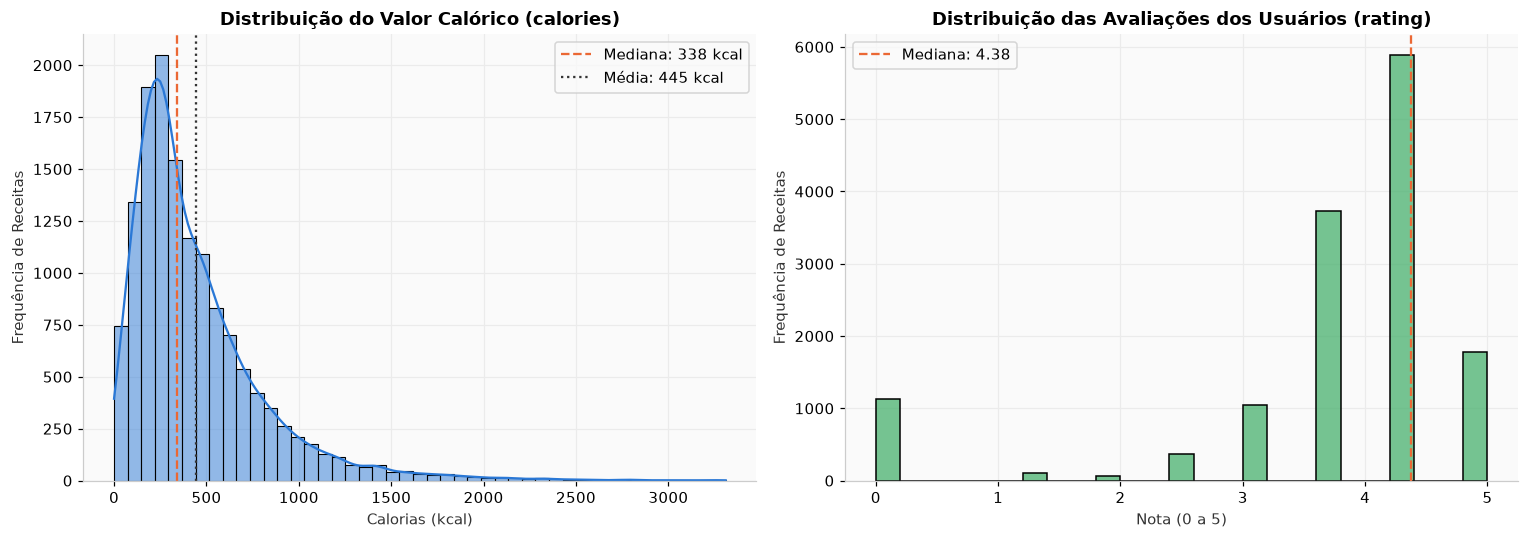

In [4]:
# %% [code]
# Distribuições de Calorias e Avaliação (Rating)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma de Calorias
sns.histplot(dados["calories"], kde=True, bins=45, color="#2a78d6", ax=axes[0])
axes[0].set_title("Distribuição do Valor Calórico (calories)")
axes[0].set_xlabel("Calorias (kcal)")
axes[0].set_ylabel("Frequência de Receitas")
axes[0].axvline(dados["calories"].median(), color="#eb6834", linestyle="--", label=f"Mediana: {dados['calories'].median():.0f} kcal")
axes[0].axvline(dados["calories"].mean(), color="#333333", linestyle=":", label=f"Média: {dados['calories'].mean():.0f} kcal")
axes[0].legend()

# Histograma de Rating
sns.histplot(dados["rating"], kde=False, bins=25, color="#48b16e", ax=axes[1])
axes[1].set_title("Distribuição das Avaliações dos Usuários (rating)")
axes[1].set_xlabel("Nota (0 a 5)")
axes[1].set_ylabel("Frequência de Receitas")
axes[1].axvline(dados["rating"].median(), color="#eb6834", linestyle="--", label=f"Mediana: {dados['rating'].median():.2f}")
axes[1].legend()

plt.tight_layout()
plt.show()

Observações sobre as distribuições:
- **`calories`:** Apresenta distribuição assimétrica à direita com cauda longa, típica de quantidades de energia alimentar. A maioria das receitas concentra-se entre 150 e 600 kcal, com mediana em torno de 310 kcal.
- **`rating`:** Apresenta comportamento fortemente discreto com picos marcados em 3.75, 4.375 e 5.0, e um agrupamento menor em 0.0 (receitas não avaliadas ou mal cotadas). Essa característica sugere que a discretização em classes ordinais é a abordagem mais natural para previsão.

In [5]:
# %% [code]
# Correlação de Spearman entre variáveis contínuas
cols_num = ["calories", "fat", "protein", "sodium", "rating"]
corr_spearman = dados[cols_num].corr(method="spearman")

display(corr_spearman.style.background_gradient(cmap="Blues", axis=None).format("{:.3f}"))

,calories,fat,protein,sodium,rating
calories,1.000,0.858,0.770,0.532,0.112
fat,0.858,1.000,0.708,0.526,0.124
protein,0.770,0.708,1.000,0.695,0.091
sodium,0.532,0.526,0.695,1.000,0.092
rating,0.112,0.124,0.091,0.092,1.000


**Conclusões da Análise de Correlação:**
- **Calorias vs. Macronutrientes:** `calories` apresenta correlações altíssimas com `fat` ($\sim 0{,}86$) e `protein` ($\sim 0{,}78$), o que decorre diretamente das leis da termodinâmica e nutrição (fatores de Atwater: 9 kcal/g para gordura e 4 kcal/g para proteína). Como o dataset carece da coluna explícita de carboidratos, as tags de amido e açúcar (e.g. `pasta`, `rice`, `dessert`) preenchem essa lacuna física.
- **Rating vs. Variáveis Físicas:** `rating` possui correlações praticamente nulas ($\sim 0{,}10$) com todas as grandezas nutricionais. Isso comprova empiricamente que o gosto dos avaliadores não é determinado simplesmente pela quantidade de gordura ou proteína, mas pela harmonia de sabores, técnicas e subjetividade individual.

### 0.4 Definição de Features e Divisão Treino/Teste

Estabelecemos as listas de variáveis:
- `MACRO_COLS`: os 3 macronutrientes (`fat`, `protein`, `sodium`).
- `TOP30_FEATURES`: as 30 variáveis selecionadas por penalização Lasso na atividade anterior (os 3 macronutrientes mais 27 marcadores de carboidratos, técnicas e tipos de prato). Na seção 1.2 (modelo 6) **reproduzimos essa seleção de forma explícita** com o `LassoCV` treinado apenas no conjunto de treino e medimos a concordância com esta lista.
- `ALL_FEATURES`: os 3 macronutrientes combinados com todas as 332 tags preservadas (total de 335 preditores).

Em seguida, efetuamos a partição em **80% para treino** e **20% para teste**, fixando `random_state=42`. Todos os ajustes (escalonamento, seleção, hiperparâmetros) usam **somente o treino**; o teste é tocado uma única vez, na avaliação final.

In [6]:
# %% [code]
# Definição dos grupos de variáveis preditoras
MACRO_COLS = ["fat", "protein", "sodium"]

TOP30_FEATURES = [
    "fat", "protein", "sodium", "pasta", "dessert", "drink", "fruit", "alcoholic",
    "sugar conscious", "no-cook", "rice", "potato", "sweet potato/yam", "bread",
    "bean", "cake", "cookies", "pear", "prune", "cranberry", "dried fruit",
    "low carb", "kidney friendly", "kosher", "salad", "garlic", "fall", "bake",
    "marinate", "quick & easy"
]

ALL_FEATURES = MACRO_COLS + tags_mantidas

# Separação das matrizes de treino e teste
X_train_full, X_test_full, y_train, y_test = train_test_split(
    dados[ALL_FEATURES],
    dados["calories"],
    test_size=0.20,
    random_state=SEED
)

# Subconjuntos de features para modelos específicos
X_train_top30 = X_train_full[TOP30_FEATURES]
X_test_top30 = X_test_full[TOP30_FEATURES]

X_train_macro = X_train_full[MACRO_COLS]
X_test_macro = X_test_full[MACRO_COLS]

print(f"Total de registros limpos:       {len(dados):,}")
print(f"Conjunto de Treino:              {len(X_train_full):,} amostras")
print(f"Conjunto de Teste:               {len(X_test_full):,} amostras")
print(f"Dimensão de TOP30_FEATURES:      {len(TOP30_FEATURES)} preditores")
print(f"Dimensão de ALL_FEATURES:        {len(ALL_FEATURES)} preditores")

Total de registros limpos:       14,096
Conjunto de Treino:              11,276 amostras
Conjunto de Teste:               2,820 amostras
Dimensão de TOP30_FEATURES:      30 preditores
Dimensão de ALL_FEATURES:        335 preditores


## Bloco 1 — Regressão: Previsão de Calorias

Neste bloco, abordamos a tarefa de regressão para estimar a variável contínua `calories` (kcal).
O percurso é estruturado em quatro etapas:
1. **Motivação univariada:** Visualização de quatro famílias de ajuste (Linear, Polinomial grau 2, Splines e LOESS) sobre a relação `fat` vs. `calories`.
2. **Treinamento e validação cruzada:** Aplicação de 10 arquiteturas de regressão com validação cruzada em 5 folds no treino e avaliação no teste.
3. **Comparação consolidada:** Tabela comparativa e gráfico de barras de $R^2$ ajustado.
4. **Diagnóstico do modelo campeão:** Análise de resíduos, dispersão real vs. predito e importância de permutação.

### 1.1 Motivação: Modelos Simples vs. Flexíveis (Visualização Univariada)

Antes de ajustar modelos multivariados com dezenas de variáveis, investigamos a capacidade de captura de padrões não-lineares em uma dimensão. Escolhemos a variável `fat` (gordura), que possui a maior correlação física com as calorias.

Criamos uma figura com 4 subplots ilustrando:
1. **Regressão Linear Simples:** Relação rígida com inclinação constante ($y = \beta_0 + \beta_1 x$).
2. **Regressão Polinomial (Grau 2):** Relação quadrática com curvatura suave global ($y = \beta_0 + \beta_1 x + \beta_2 x^2$).
3. **Spline Cúbica Suavizadora (UnivariateSpline):** Polinômios por partes com nós interiores e penalização de suavidade.
4. **Regressão Local Ponderada (LOESS):** Ajuste não-paramétrico baseado em janelas deslizantes locais ponderadas pela proximidade.

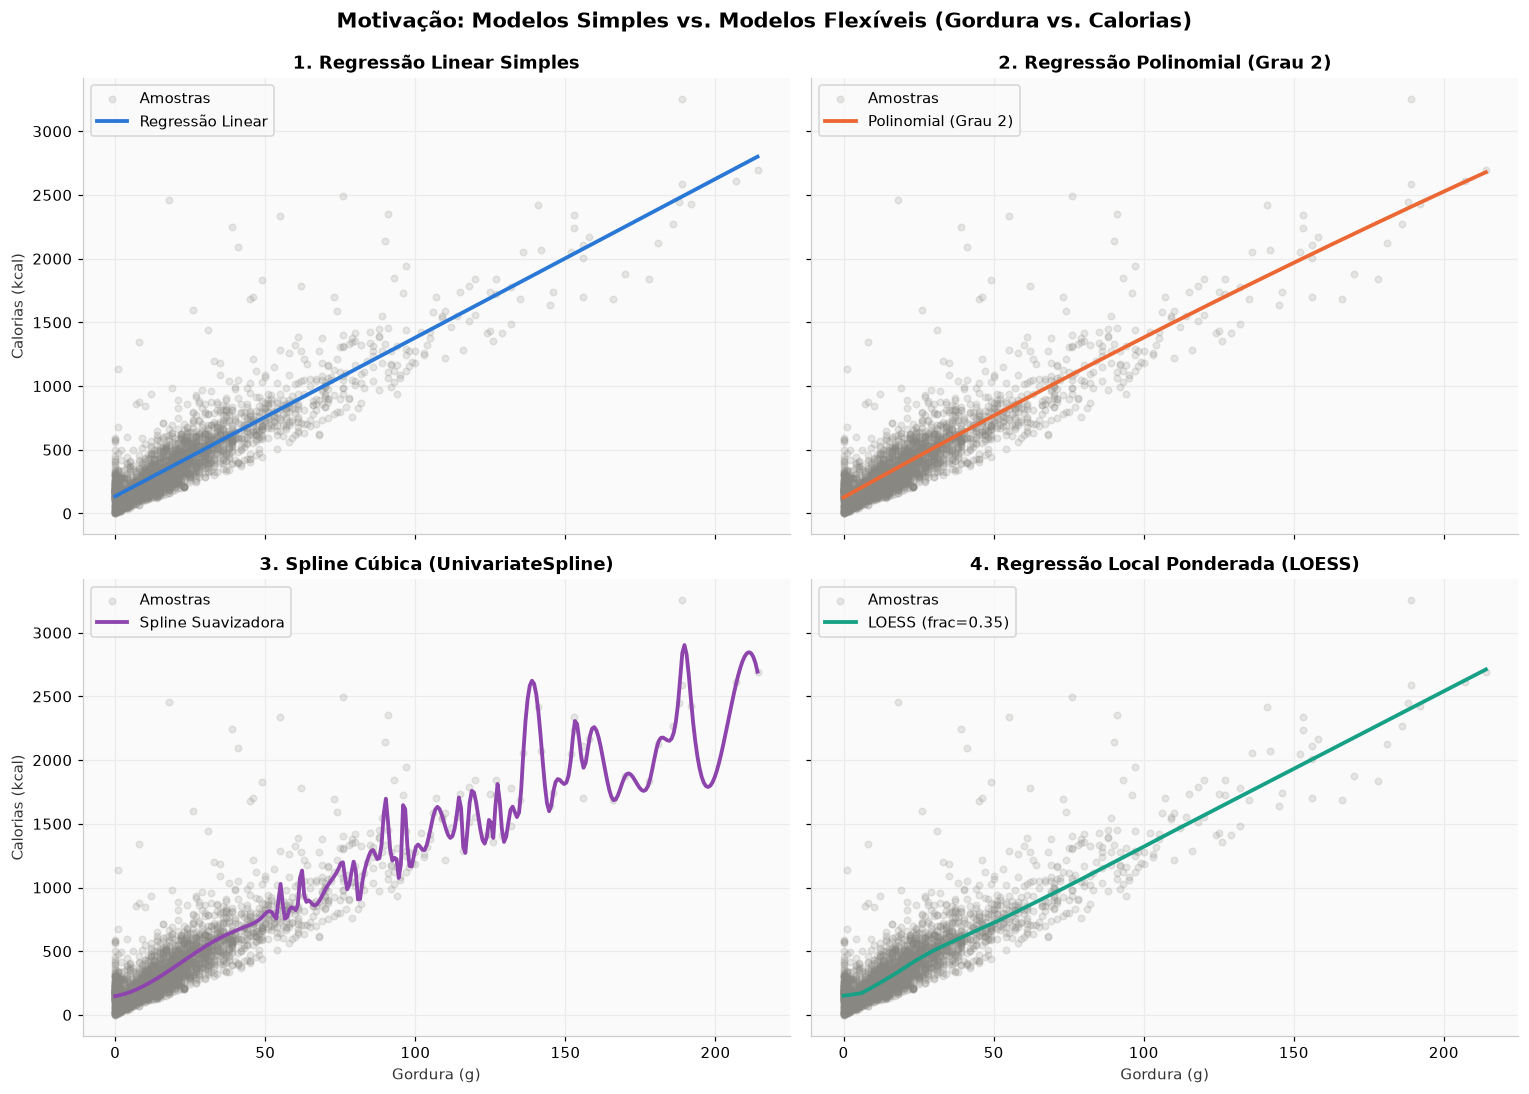

In [7]:
# %% [code]
# 1.1 Visualização Motivacional: Ajuste Univariado de Fat vs Calories
sample_vis = dados.sample(min(2500, len(dados)), random_state=SEED).sort_values("fat")
x_vis = sample_vis["fat"].values
y_vis = sample_vis["calories"].values

# Grid regular para plotagem das curvas ajustadas
x_grid = np.linspace(x_vis.min(), x_vis.max(), 300)

# 1. Ajuste Linear
lr_uni = LinearRegression().fit(x_vis.reshape(-1, 1), y_vis)
y_pred_linear = lr_uni.predict(x_grid.reshape(-1, 1))

# 2. Ajuste Polinomial (Grau 2)
poly_feat = PolynomialFeatures(degree=2, include_bias=False)
x_poly = poly_feat.fit_transform(x_vis.reshape(-1, 1))
poly_uni = LinearRegression().fit(x_poly, y_vis)
y_pred_poly = poly_uni.predict(poly_feat.transform(x_grid.reshape(-1, 1)))

# 3. Ajuste por Spline (UnivariateSpline nos pontos agregados por fat único)
fat_agg = sample_vis.groupby("fat", as_index=False)["calories"].mean()
spline_uni = UnivariateSpline(fat_agg["fat"].values, fat_agg["calories"].values, s=3e5)
y_pred_spline = spline_uni(x_grid)

# 4. Ajuste por LOESS (Local Regression)
loess_out = lowess(y_vis, x_vis, frac=0.35, return_sorted=True)

# Construção dos 4 subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)

# Subplot 1: Linear
axes[0, 0].scatter(x_vis, y_vis, alpha=0.18, color="#898781", s=18, label="Amostras")
axes[0, 0].plot(x_grid, y_pred_linear, color="#2a78d6", linewidth=2.5, label="Regressão Linear")
axes[0, 0].set_title("1. Regressão Linear Simples")
axes[0, 0].set_ylabel("Calorias (kcal)")
axes[0, 0].legend()

# Subplot 2: Polinomial grau 2
axes[0, 1].scatter(x_vis, y_vis, alpha=0.18, color="#898781", s=18, label="Amostras")
axes[0, 1].plot(x_grid, y_pred_poly, color="#eb6834", linewidth=2.5, label="Polinomial (Grau 2)")
axes[0, 1].set_title("2. Regressão Polinomial (Grau 2)")
axes[0, 1].legend()

# Subplot 3: Splines
axes[1, 0].scatter(x_vis, y_vis, alpha=0.18, color="#898781", s=18, label="Amostras")
axes[1, 0].plot(x_grid, y_pred_spline, color="#8e44ad", linewidth=2.5, label="Spline Suavizadora")
axes[1, 0].set_title("3. Spline Cúbica (UnivariateSpline)")
axes[1, 0].set_xlabel("Gordura (g)")
axes[1, 0].set_ylabel("Calorias (kcal)")
axes[1, 0].legend()

# Subplot 4: LOESS
axes[1, 1].scatter(x_vis, y_vis, alpha=0.18, color="#898781", s=18, label="Amostras")
axes[1, 1].plot(loess_out[:, 0], loess_out[:, 1], color="#16a085", linewidth=2.5, label="LOESS (frac=0.35)")
axes[1, 1].set_title("4. Regressão Local Ponderada (LOESS)")
axes[1, 1].set_xlabel("Gordura (g)")
axes[1, 1].legend()

plt.suptitle("Motivação: Modelos Simples vs. Modelos Flexíveis (Gordura vs. Calorias)", fontsize=14, fontweight="bold", y=0.99)
plt.tight_layout()
plt.savefig("figuras/motivacao_modelos_flexiveis.png", dpi=150, bbox_inches="tight")
plt.show()

**Discussão da Visualização Motivacional:**
- O modelo linear captura a tendência macroscópica com fidelidade impressionante ($\sim 9{,}8$ kcal/g de gordura), refletindo o aporte físico do nutriente.
- Contudo, tanto a Spline quanto o LOESS revelam nuances sutis: na região de baixa gordura ($< 20$g), a curva não parte da origem porque pratos pobres em gordura ainda contêm calorias de proteínas e açúcares; na região de alta gordura ($> 100$g), há leve saturação e aumento de heterocedasticidade.
- Essa flexibilidade local motiva a utilização de técnicas capazes de modelar termos aditivos não-lineares e interações de alta ordem no espaço multivariado.

### 1.2 Modelagem Multivariada — 10 Modelos de Regressão

Definimos as funções auxiliares para cálculo do $R^2$ ajustado e execução do protocolo de avaliação sob **validação cruzada em 5 folds**:

$$R^2_{\text{aj}} = 1 - (1 - R^2) \frac{n - 1}{n - p - 1}$$

onde $n$ é o tamanho amostral e $p$ o número de preditores do modelo.

In [8]:
# %% [code]
# Funções de avaliação padronizada para os regressores
def r2_ajustado(r2, n, p):
    """Calcula o R² ajustado penalizado pelo número de preditores p."""
    if n - p - 1 <= 0:
        return np.nan
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

def avaliar_modelo(nome, modelo, X_tr, y_tr, X_te, y_te, cv=5, n_features=None):
    """Executa CV em 5 folds no treino e avalia no teste (R², R² adj, MAE, RMSE)."""
    kf = KFold(n_splits=cv, shuffle=True, random_state=SEED)
    p = n_features if n_features is not None else X_tr.shape[1]
    
    # Validação cruzada no treino
    cv_r2 = cross_val_score(modelo, X_tr, y_tr, cv=kf, scoring="r2", n_jobs=-1)
    cv_mae = -cross_val_score(modelo, X_tr, y_tr, cv=kf, scoring="neg_mean_absolute_error", n_jobs=-1)
    
    # Ajuste no treino completo e predição no teste
    modelo.fit(X_tr, y_tr)
    y_pred = modelo.predict(X_te)
    
    # Métricas no teste
    n_test = len(y_te)
    test_r2 = r2_score(y_te, y_pred)
    test_r2_adj = r2_ajustado(test_r2, n_test, p)
    test_mae = mean_absolute_error(y_te, y_pred)
    test_rmse = root_mean_squared_error(y_te, y_pred)
    
    resultado = {
        "Modelo": nome,
        "Features": p,
        "R² CV (Treino)": f"{cv_r2.mean():.4f} ± {cv_r2.std():.4f}",
        "MAE CV (Treino)": f"{cv_mae.mean():.2f} ± {cv_mae.std():.2f}",
        "R² Teste": test_r2,
        "R² Ajustado Teste": test_r2_adj,
        "MAE Teste": test_mae,
        "RMSE Teste": test_rmse,
        "modelo_fitted": modelo,
        "y_pred_test": y_pred
    }
    
    print(f"[{nome}] R² Teste: {test_r2:.4f} | R² Adj: {test_r2_adj:.4f} | MAE: {test_mae:.2f} kcal | RMSE: {test_rmse:.2f} kcal")
    return resultado

# Lista acumuladora dos resultados
resultados_regressao = []

#### 1. Regressão Linear Simples (Macronutrientes)
Ajuste de Mínimos Quadrados Ordinários (OLS) utilizando apenas os 3 macronutrientes (`fat`, `protein`, `sodium`). Fornece a linha de base física do problema.

In [9]:
# %% [code]
# Modelo 1: Regressão Linear (3 macros)
res_m1 = avaliar_modelo(
    "1. Regressão Linear (3 macros)",
    LinearRegression(),
    X_train_macro, y_train,
    X_test_macro, y_test
)
resultados_regressao.append(res_m1)

[1. Regressão Linear (3 macros)] R² Teste: 0.8452 | R² Adj: 0.8450 | MAE: 95.17 kcal | RMSE: 144.37 kcal


#### 2. Regressão Polinomial (Grau 2)
Expansão polinomial de segundo grau sobre os 3 macronutrientes, gerando termos quadráticos e interações ($X_1^2, X_1 X_2, \dots$).

In [10]:
# %% [code]
# Modelo 2: Regressão Polinomial (grau 2 nos 3 macros)
pipe_poly2 = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("reg", LinearRegression())
])
res_m2 = avaliar_modelo(
    "2. Regressão Polinomial (Grau 2)",
    pipe_poly2,
    X_train_macro, y_train,
    X_test_macro, y_test
)
resultados_regressao.append(res_m2)

[2. Regressão Polinomial (Grau 2)] R² Teste: 0.8450 | R² Adj: 0.8449 | MAE: 95.77 kcal | RMSE: 144.43 kcal


#### 3. Regressão com Splines Cúbicas Naturais
Utilizamos a biblioteca `patsy` para gerar a base de splines cúbicas naturais (`cr`) com 4 graus de liberdade para `fat` e `protein`, mantendo `sodium` linear:
$$\text{calories} \sim \text{cr}(\text{fat}, df=4) + \text{cr}(\text{protein}, df=4) + \text{sodium}$$
O design matrix ajustado no treino é projetado no conjunto de teste sem vazamento.

In [11]:
# %% [code]
# Modelo 3: Splines Cúbicas Naturais via Patsy
formula_spline = "cr(fat, df=4) + cr(protein, df=4) + sodium"
X_train_spline = dmatrix(formula_spline, data=X_train_macro, return_type="dataframe")
X_test_spline = build_design_matrices([X_train_spline.design_info], X_test_macro)[0]

res_m3 = avaliar_modelo(
    "3. Splines Cúbicas Naturais (Patsy)",
    LinearRegression(fit_intercept=False),
    X_train_spline, y_train,
    X_test_spline, y_test,
    n_features=X_train_spline.shape[1] - 1
)
resultados_regressao.append(res_m3)

[3. Splines Cúbicas Naturais (Patsy)] R² Teste: 0.8448 | R² Adj: 0.8443 | MAE: 95.60 kcal | RMSE: 144.54 kcal


#### 4. Generalized Additive Model (GAM)
Modelo Aditivo Generalizado implementado com `pygam.LinearGAM`:
$$y = \beta_0 + s_1(\text{fat}) + s_2(\text{protein}) + s_3(\text{sodium})$$
Cada preditor é transformado por uma spline B penalizada, ajustada via Mínimos Quadrados Penalizados.

In [12]:
# %% [code]
# Modelo 4: LinearGAM via pygam
gam = LinearGAM(s(0) + s(1) + s(2))

# Validação cruzada customizada para pygam
kf_gam = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_r2_gam = []
cv_mae_gam = []
for tr_i, val_i in kf_gam.split(X_train_macro):
    g_fold = LinearGAM(s(0) + s(1) + s(2))
    g_fold.fit(X_train_macro.values[tr_i], y_train.values[tr_i])
    preds_val = g_fold.predict(X_train_macro.values[val_i])
    cv_r2_gam.append(r2_score(y_train.values[val_i], preds_val))
    cv_mae_gam.append(mean_absolute_error(y_train.values[val_i], preds_val))

# Ajuste no treino completo e teste
gam.fit(X_train_macro.values, y_train.values)
y_pred_gam = gam.predict(X_test_macro.values)

test_r2_gam = r2_score(y_test, y_pred_gam)
test_r2_adj_gam = r2_ajustado(test_r2_gam, len(y_test), 3)
test_mae_gam = mean_absolute_error(y_test, y_pred_gam)
test_rmse_gam = root_mean_squared_error(y_test, y_pred_gam)

res_m4 = {
    "Modelo": "4. GAM (LinearGAM pygam)",
    "Features": 3,
    "R² CV (Treino)": f"{np.mean(cv_r2_gam):.4f} ± {np.std(cv_r2_gam):.4f}",
    "MAE CV (Treino)": f"{np.mean(cv_mae_gam):.2f} ± {np.std(cv_mae_gam):.2f}",
    "R² Teste": test_r2_gam,
    "R² Ajustado Teste": test_r2_adj_gam,
    "MAE Teste": test_mae_gam,
    "RMSE Teste": test_rmse_gam,
    "modelo_fitted": gam,
    "y_pred_test": y_pred_gam
}
print(f"[4. GAM (LinearGAM pygam)] R² Teste: {test_r2_gam:.4f} | R² Adj: {test_r2_adj_gam:.4f} | MAE: {test_mae_gam:.2f} kcal | RMSE: {test_rmse_gam:.2f} kcal")
resultados_regressao.append(res_m4)

[4. GAM (LinearGAM pygam)] R² Teste: 0.8524 | R² Adj: 0.8523 | MAE: 89.99 kcal | RMSE: 140.94 kcal


#### 5. Regressão Ridge (Regularização L2)
Regressão linear com penalidade de norma $L_2$ aplicada sobre as **TOP 30 features** (3 macronutrientes + 27 tags). Inclui padronização `StandardScaler`.

In [13]:
# %% [code]
# Modelo 5: Ridge Regression (TOP30_FEATURES)
pipe_ridge = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=1.0, random_state=SEED))
])
res_m5 = avaliar_modelo(
    "5. Regressão Ridge (30 vars)",
    pipe_ridge,
    X_train_top30, y_train,
    X_test_top30, y_test
)
resultados_regressao.append(res_m5)

[5. Regressão Ridge (30 vars)] R² Teste: 0.8878 | R² Adj: 0.8866 | MAE: 71.41 kcal | RMSE: 122.90 kcal


#### 6. Regressão Lasso (Regularização L1 e Seleção de Variáveis)
Ajuste de `LassoCV` com 5 folds sobre **todas as 335 variáveis** (3 macronutrientes + 332 tags). A penalidade de norma $L_1$ zera coeficientes de variáveis irrelevantes ou redundantes.

In [14]:
# %% [code]
# Modelo 6: LassoCV em todas as 335 variáveis
pipe_lasso = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", LassoCV(cv=5, random_state=SEED, max_iter=2000, n_jobs=-1))
])
res_m6 = avaliar_modelo(
    "6. Regressão Lasso (335 vars)",
    pipe_lasso,
    X_train_full, y_train,
    X_test_full, y_test,
    n_features=len(ALL_FEATURES)
)
resultados_regressao.append(res_m6)

# Inspeção dos coeficientes do Lasso
lasso_fitted = pipe_lasso.named_steps["lasso"]
n_nao_zeros = np.sum(lasso_fitted.coef_ != 0)
print(f"Alpha ótimo escolhido pelo LassoCV: {lasso_fitted.alpha_:.4f}")
print(f"Número de coeficientes diferentes de zero retidos: {n_nao_zeros} de {len(ALL_FEATURES)}")

[6. Regressão Lasso (335 vars)] R² Teste: 0.8943 | R² Adj: 0.8801 | MAE: 67.35 kcal | RMSE: 119.26 kcal
Alpha ótimo escolhido pelo LassoCV: 0.7543
Número de coeficientes diferentes de zero retidos: 246 de 335


Variáveis com coeficiente não nulo: 246 de 335
Concordância entre o Top-30 do Lasso (treino atual) e TOP30_FEATURES: 21/30


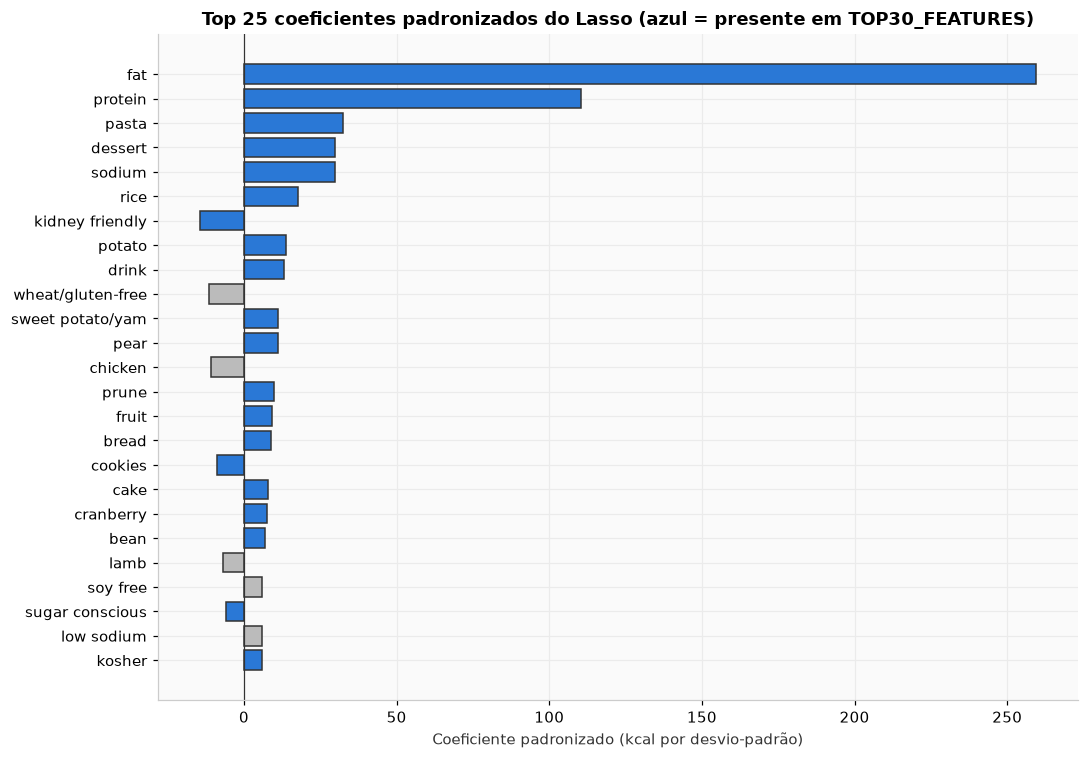

In [15]:
# Seleção explícita de variáveis via Lasso (reprodução do critério que gerou TOP30_FEATURES)
# O Lasso foi ajustado SOMENTE no treino (pipe_lasso acima). Como as variáveis foram padronizadas,
# |coeficiente| é comparável entre variáveis e funciona como ranking de relevância.
coefs_lasso = pd.Series(lasso_fitted.coef_, index=ALL_FEATURES)
ranking_lasso = coefs_lasso.abs().sort_values(ascending=False)
top30_lasso_treino = ranking_lasso.head(30).index.tolist()

concordancia = set(top30_lasso_treino) & set(TOP30_FEATURES)
print(f"Variáveis com coeficiente não nulo: {(coefs_lasso != 0).sum()} de {len(ALL_FEATURES)}")
print(f"Concordância entre o Top-30 do Lasso (treino atual) e TOP30_FEATURES: {len(concordancia)}/30")

fig, ax = plt.subplots(figsize=(10, 7))
top_plot = coefs_lasso.loc[ranking_lasso.head(25).index][::-1]
cores = ["#2a78d6" if c in TOP30_FEATURES else "#bbbbbb" for c in top_plot.index]
ax.barh(top_plot.index, top_plot.values, color=cores, edgecolor="#333333")
ax.axvline(0, color="#333333", linewidth=0.8)
ax.set_title("Top 25 coeficientes padronizados do Lasso (azul = presente em TOP30_FEATURES)")
ax.set_xlabel("Coeficiente padronizado (kcal por desvio-padrão)")
plt.tight_layout()
plt.savefig("figuras/selecao_lasso_regressao.png", dpi=150, bbox_inches="tight")
plt.show()

[GB — TOP30_FEATURES (lista original)] R² Teste: 0.8983 | R² Adj: 0.8972 | MAE: 66.20 kcal | RMSE: 116.99 kcal

[GB — Top-30 do ranking novo (|β| no α ótimo)] R² Teste: 0.8984 | R² Adj: 0.8973 | MAE: 66.05 kcal | RMSE: 116.96 kcal

Modelo,Features,R² CV (Treino),R² Teste,R² Ajustado Teste,MAE Teste,RMSE Teste
GB — TOP30_FEATURES (lista original),30,0.9040 ± 0.0101,0.8983,0.8972,66.20,116.99
GB — Top-30 do ranking novo (|β| no α ótimo),30,0.9034 ± 0.0093,0.8984,0.8973,66.05,116.96


k,Originais no top-k do ranking novo
10,9
20,18
30,21
40,25
50,27
60,29


As 9 primeiras variáveis do ranking novo pertencem todas à lista original (a 10ª, 'wheat/gluten-free', não pertence).
Pior posição de uma variável original no ranking novo: 69 ('quick & easy'); variáveis originais com coeficiente zerado pelo Lasso: 0

Só na lista original (9): no-cook (#47, β=-3.5), dried fruit (#55, β=+3.2), low carb (#33, β=-4.8), salad (#34, β=-4.5), garlic (#38, β=-4.0), fall (#51, β=+3.4), bake (#36, β=+4.3), marinate (#44, β=-3.7), quick & easy (#69, β=-2.7)
Só na lista nova (9): wheat/gluten-free (#10, β=-11.4), chicken (#13, β=-11.0), lamb (#21, β=-6.7), soy free (#22, β=+6.0), low sodium (#24, β=+5.8), roast (#26, β=-5.7), turkey (#27, β=-5.7), fish (#28, β=-5.5), peanut free (#30, β=+5.2)

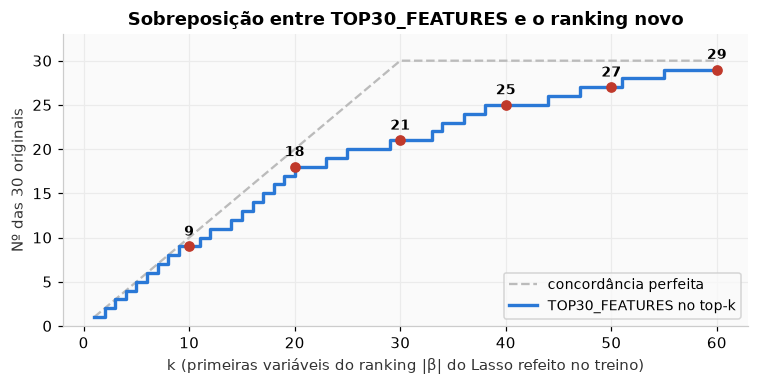

In [47]:
# 1.2 (complemento) A lista de 30 variáveis muda o desempenho do campeão?
# Lista original: TOP30_FEATURES (atividade anterior: ordem de entrada no caminho de regularização do Lasso).
# Lista nova: as 30 primeiras de ranking_lasso (|coeficiente| padronizado no α ótimo do LassoCV refeito no treino atual).
top30_ranking_novo = ranking_lasso.head(30).index.tolist()

# (a) Mesma configuração do modelo 10 (campeão): HistGradientBoostingRegressor(random_state=SEED),
#     mesmo protocolo de avaliação (CV de 5 folds no treino + teste), p = 30 nas duas listas
comparacao_listas = []
for nome_lista, cols in [("TOP30_FEATURES (lista original)", TOP30_FEATURES),
                         ("Top-30 do ranking novo (|β| no α ótimo)", top30_ranking_novo)]:
    res_lista = avaliar_modelo(f"GB — {nome_lista}", HistGradientBoostingRegressor(random_state=SEED),
                               X_train_full[cols], y_train, X_test_full[cols], y_test)
    comparacao_listas.append({c: res_lista[c] for c in
                              ["Modelo", "Features", "R² CV (Treino)", "R² Teste", "R² Ajustado Teste",
                               "MAE Teste", "RMSE Teste"]})
display(pd.DataFrame(comparacao_listas).style
        .format({"R² Teste": "{:.4f}", "R² Ajustado Teste": "{:.4f}", "MAE Teste": "{:.2f}", "RMSE Teste": "{:.2f}"})
        .hide(axis="index"))

# (b) Quantas das 30 originais aparecem no top-k do ranking novo
ks_sobrep = [10, 20, 30, 40, 50, 60]
sobreposicao_k = pd.DataFrame({
    "k": ks_sobrep,
    "Originais no top-k do ranking novo": [len(set(TOP30_FEATURES) & set(ranking_lasso.head(k).index))
                                           for k in ks_sobrep],
})
display(sobreposicao_k.style.hide(axis="index"))
posicao_nova = pd.Series({c: ranking_lasso.index.get_loc(c) + 1 for c in TOP30_FEATURES}).sort_values()
inicio_comum = next((i for i, c in enumerate(ranking_lasso.index) if c not in TOP30_FEATURES), len(ranking_lasso))
print(f"As {inicio_comum} primeiras variáveis do ranking novo pertencem todas à lista original "
      f"(a {inicio_comum + 1}ª, '{ranking_lasso.index[inicio_comum]}', não pertence).")
print(f"Pior posição de uma variável original no ranking novo: {posicao_nova.max()} ('{posicao_nova.idxmax()}'); "
      f"variáveis originais com coeficiente zerado pelo Lasso: {int((coefs_lasso[TOP30_FEATURES] == 0).sum())}")

# (c) Diferenças entre as listas (posição no ranking novo e coeficiente padronizado)
so_original = [c for c in TOP30_FEATURES if c not in top30_ranking_novo]
so_nova = [c for c in top30_ranking_novo if c not in TOP30_FEATURES]
print(f"\nSó na lista original ({len(so_original)}): " +
      ", ".join(f"{c} (#{posicao_nova[c]}, β={coefs_lasso[c]:+.1f})" for c in so_original))
print(f"Só na lista nova ({len(so_nova)}): " +
      ", ".join(f"{c} (#{ranking_lasso.index.get_loc(c) + 1}, β={coefs_lasso[c]:+.1f})" for c in so_nova))

# (d) Curva de sobreposição por k
ks_curva = np.arange(1, 61)
sobrep_curva = [len(set(TOP30_FEATURES) & set(ranking_lasso.head(k).index)) for k in ks_curva]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(ks_curva, np.minimum(ks_curva, 30), color="#bbbbbb", linestyle="--", label="concordância perfeita")
ax.step(ks_curva, sobrep_curva, where="post", color="#2a78d6", linewidth=2.2, label="TOP30_FEATURES no top-k")
ax.scatter(ks_sobrep, sobreposicao_k.iloc[:, 1], color="#c0392b", zorder=5)
for k, v in zip(ks_sobrep, sobreposicao_k.iloc[:, 1]):
    ax.annotate(f"{v}", (k, v), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=9, fontweight="bold")
ax.set_xlabel("k (primeiras variáveis do ranking |β| do Lasso refeito no treino)")
ax.set_ylabel("Nº das 30 originais")
ax.set_ylim(0, 33)
ax.set_title("Sobreposição entre TOP30_FEATURES e o ranking novo")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.savefig("figuras/sobreposicao_top30_lasso.png", dpi=150, bbox_inches="tight")
plt.show()

**Conferência da lista de 30 variáveis (resultado medido).** As duas listas usam o Lasso sobre as mesmas 335 variáveis padronizadas e a mesma base de treino (11.276 receitas, `random_state=42`), mas ranqueiam de formas diferentes:
- **`TOP30_FEATURES` (atividade anterior, seção 6.4 de [ml-atividade](https://github.com/LucasBuccini/ml-atividade)):** `lasso_path` com 200 valores de α; as variáveis são ordenadas pela **ordem de entrada** no modelo à medida que α diminui, e ficam as 30 primeiras. O corte em 30 veio da curva de $R^2$ em validação cruzada do Gradient Boosting (0,887 com 10 variáveis, 0,904 com 30 e 0,911 com as 335): é o ponto em que a curva começa a achatar, não o máximo.
- **Ranking desta seção:** o `LassoCV` (5 folds) escolhe um único α ótimo (0,754), e as variáveis são ordenadas pelo **|coeficiente| padronizado** nesse α, em que 246 das 335 continuam no modelo.
- **Diferença prática:** a ordem de entrada mede quão cedo a variável se torna útil sob penalidade forte; o |β| no α ótimo mede o tamanho do efeito num modelo que já tem muitas variáveis, em que tags correlacionadas com os macros podem ganhar peso como correções (ex.: `chicken` −11,0, `turkey` −5,7, `fish` −5,5). Por isso a concordância é parcial.
- **Desempenho (mesmo Gradient Boosting do modelo 10, p = 30 nas duas listas):** lista original — $R^2_{aj}$ = 0,8972, MAE = 66,20 kcal, RMSE = 116,99 kcal, $R^2$ CV = 0,9040 ± 0,0101; lista nova — $R^2_{aj}$ = 0,8973, MAE = 66,05 kcal, RMSE = 116,96 kcal, $R^2$ CV = 0,9034 ± 0,0093. No teste a lista nova fica à frente por 0,0001 de $R^2_{aj}$ e 0,15 kcal de MAE; na validação cruzada a original fica à frente por 0,0006. As diferenças são muito menores que o desvio-padrão entre folds (≈ 0,01).
- **Sobreposição por k:** das 30 variáveis originais, 9 estão no top-10 do ranking novo, 18 no top-20, 21 no top-30, 25 no top-40, 27 no top-50 e 29 no top-60. As 9 primeiras do ranking novo pertencem todas à lista original (a 10ª, `wheat/gluten-free`, não); nenhuma variável original tem coeficiente zerado (a pior está na posição 69, `quick & easy`).
- **Só na lista original (9):** `no-cook`, `dried fruit`, `low carb`, `salad`, `garlic`, `fall`, `bake`, `marinate`, `quick & easy` — posições 33 a 69 no ranking novo, |β| entre 2,7 e 4,8.
- **Só na lista nova (9):** `wheat/gluten-free`, `chicken`, `lamb`, `soy free`, `low sodium`, `roast`, `turkey`, `fish`, `peanut free` — posições 10 a 30, |β| entre 5,2 e 11,4.

**Seleção de variáveis na regressão (explícita):** o Lasso funciona como método *embutido* de seleção — a penalidade $L_1$ zera coeficientes irrelevantes. O ranking por $|\beta|$ padronizado mostra que `fat` e `protein` dominam, seguidos das tags que funcionam como *proxy* de carboidratos (`dessert`, `drink`, `pasta`, `rice`...). A concordância com a lista `TOP30_FEATURES` (definida na atividade anterior) confirma que o subconjunto usado pelos modelos 5 e 7–10 não é arbitrário.

#### 7. Árvore de Decisão
Regressão não-linear baseada em partições retangulares recursivas (`DecisionTreeRegressor(max_depth=8, random_state=42)`) sobre as 30 variáveis.

In [16]:
# %% [code]
# Modelo 7: Árvore de Decisão (profundidade 8)
dt_reg = DecisionTreeRegressor(max_depth=8, random_state=SEED)
res_m7 = avaliar_modelo(
    "7. Árvore de Decisão (depth=8)",
    dt_reg,
    X_train_top30, y_train,
    X_test_top30, y_test
)
resultados_regressao.append(res_m7)

[7. Árvore de Decisão (depth=8)] R² Teste: 0.8210 | R² Adj: 0.8191 | MAE: 87.07 kcal | RMSE: 155.23 kcal


#### 8. Bagging (Bootstrap Aggregating)
Ensemble com 50 árvores de decisão (`BaggingRegressor`), reduzindo a variância individual das árvores através de agregação por média.

In [17]:
# %% [code]
# Modelo 8: Bagging de Árvores de Decisão
bag_reg = BaggingRegressor(
    estimator=DecisionTreeRegressor(max_depth=8, random_state=SEED),
    n_estimators=50,
    random_state=SEED,
    n_jobs=-1
)
res_m8 = avaliar_modelo(
    "8. Bagging (50 árvores)",
    bag_reg,
    X_train_top30, y_train,
    X_test_top30, y_test
)
resultados_regressao.append(res_m8)

[8. Bagging (50 árvores)] R² Teste: 0.8745 | R² Adj: 0.8732 | MAE: 76.61 kcal | RMSE: 129.97 kcal


#### 9. Random Forest
Floresta Aleatória (`RandomForestRegressor(n_estimators=100)`) sobre as 30 variáveis, combinando amostragem de bootstrap com subespaço aleatório de preditores para descorrelacionar as árvores.

In [18]:
# %% [code]
# Modelo 9: Random Forest (100 árvores)
rf_reg = RandomForestRegressor(
    n_estimators=100,
    random_state=SEED,
    n_jobs=-1
)
res_m9 = avaliar_modelo(
    "9. Random Forest (100 árvores)",
    rf_reg,
    X_train_top30, y_train,
    X_test_top30, y_test
)
resultados_regressao.append(res_m9)

[9. Random Forest (100 árvores)] R² Teste: 0.8830 | R² Adj: 0.8817 | MAE: 69.86 kcal | RMSE: 125.50 kcal


#### 10. Gradient Boosting
Algoritmo de Boosting (`HistGradientBoostingRegressor`) ajustado sequencialmente sobre os resíduos do modelo anterior. É o modelo campeão identificado na atividade anterior.

In [19]:
# %% [code]
# Modelo 10: HistGradientBoosting (30 vars)
gb_reg = HistGradientBoostingRegressor(random_state=SEED)
res_m10 = avaliar_modelo(
    "10. Gradient Boosting (30 vars)",
    gb_reg,
    X_train_top30, y_train,
    X_test_top30, y_test
)
resultados_regressao.append(res_m10)

[10. Gradient Boosting (30 vars)] R² Teste: 0.8983 | R² Adj: 0.8972 | MAE: 66.20 kcal | RMSE: 116.99 kcal


### 1.3 Comparação Geral dos Modelos de Regressão

Consolidamos os resultados dos 10 modelos em uma tabela estilizada e em um gráfico de barras comparando o $R^2$ ajustado no conjunto de teste.

,Modelo,Features,R² CV (Treino),MAE CV (Treino),R² Teste,R² Ajustado Teste,MAE Teste,RMSE Teste
0,1. Regressão Linear (3 macros),3,0.8429 ± 0.0129,98.54 ± 3.44,0.8452,0.8450,95.17,144.37
1,2. Regressão Polinomial (Grau 2),3,0.8462 ± 0.0120,97.82 ± 3.17,0.8450,0.8449,95.77,144.43
2,3. Splines Cúbicas Naturais (Patsy),9,0.8432 ± 0.0129,98.61 ± 3.37,0.8448,0.8443,95.60,144.54
3,4. GAM (LinearGAM pygam),3,0.8494 ± 0.0136,93.72 ± 3.59,0.8524,0.8523,89.99,140.94
4,5. Regressão Ridge (30 vars),30,0.8871 ± 0.0105,74.24 ± 2.70,0.8878,0.8866,71.41,122.90
5,6. Regressão Lasso (335 vars),335,0.8929 ± 0.0100,70.59 ± 2.16,0.8943,0.8801,67.35,119.26
6,7. Árvore de Decisão (depth=8),30,0.8418 ± 0.0141,88.21 ± 2.93,0.8210,0.8191,87.07,155.23
7,8. Bagging (50 árvores),30,0.8825 ± 0.0142,78.18 ± 3.58,0.8745,0.8732,76.61,129.97
8,9. Random Forest (100 árvores),30,0.8930 ± 0.0117,71.14 ± 2.81,0.8830,0.8817,69.86,125.50
9,10. Gradient Boosting (30 vars),30,0.9040 ± 0.0101,67.99 ± 2.38,0.8983,0.8972,66.20,116.99


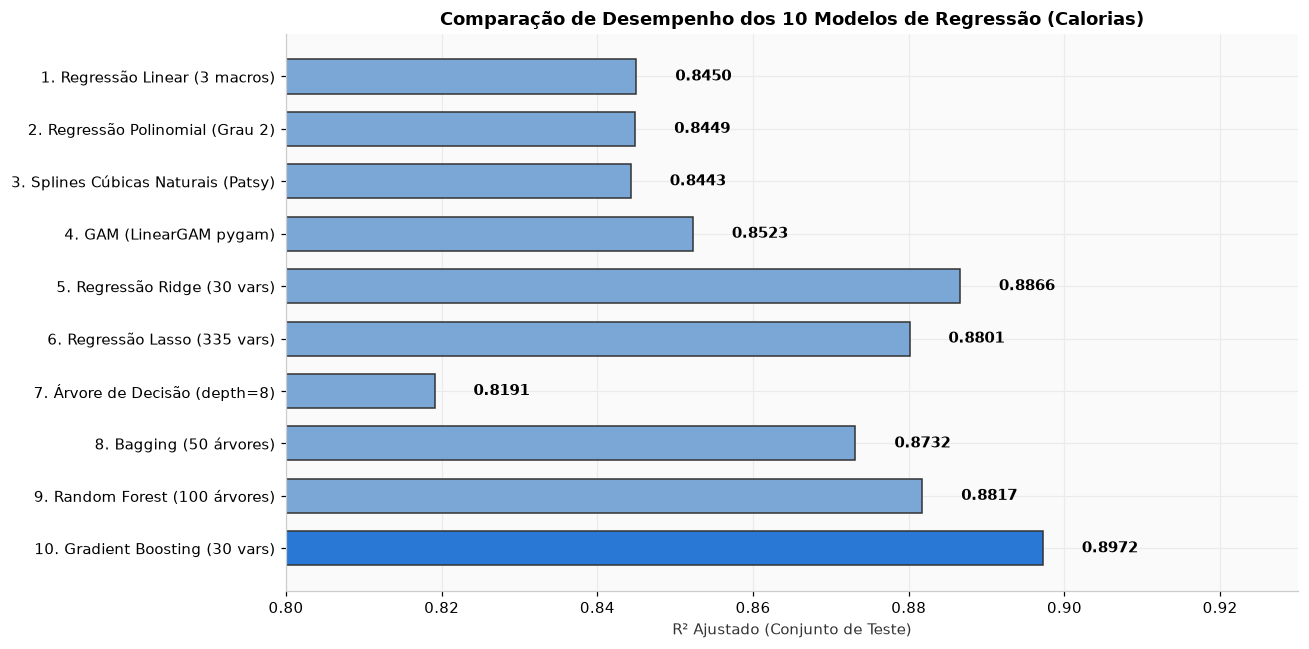

In [20]:
# %% [code]
# Criação do DataFrame comparativo
df_res_reg = pd.DataFrame(resultados_regressao)
cols_tabela = ["Modelo", "Features", "R² CV (Treino)", "MAE CV (Treino)", "R² Teste", "R² Ajustado Teste", "MAE Teste", "RMSE Teste"]
df_show_reg = df_res_reg[cols_tabela].copy()

# Visualização da tabela estilizada
display(df_show_reg.style
    .highlight_max(subset=["R² Teste", "R² Ajustado Teste"], color="#c6e2ff")
    .highlight_min(subset=["MAE Teste", "RMSE Teste"], color="#c6e2ff")
    .format({
        "R² Teste": "{:.4f}",
        "R² Ajustado Teste": "{:.4f}",
        "MAE Teste": "{:.2f}",
        "RMSE Teste": "{:.2f}"
    }))

# Gráfico de barras comparando R² ajustado
fig, ax = plt.subplots(figsize=(12, 6))
bar_colors = ["#2a78d6" if "Gradient Boosting" in m else "#7ba7d7" for m in df_res_reg["Modelo"]]
bars = ax.barh(df_res_reg["Modelo"], df_res_reg["R² Ajustado Teste"], color=bar_colors, edgecolor="#333333", height=0.65)

# Anotações nas barras
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.005, bar.get_y() + bar.get_height()/2, f"{w:.4f}", va="center", ha="left", fontsize=10, fontweight="bold")

ax.set_xlim(0.80, 0.93)
ax.set_xlabel("R² Ajustado (Conjunto de Teste)")
ax.set_title("Comparação de Desempenho dos 10 Modelos de Regressão (Calorias)")
ax.invert_yaxis()

plt.tight_layout()
plt.savefig("figuras/comparacao_regressores.png", dpi=150, bbox_inches="tight")
plt.show()

**Análise dos Resultados de Regressão:**
1. **Modelos baseados apenas nos 3 macronutrientes:**
   - A Regressão Linear com 3 macronutrientes atinge $R^2_{\text{aj}} = 0{,}845$ (MAE = 95 kcal). É uma excelente linha de base física, mas não captura o conteúdo energético de amidos e açúcares porque o dataset não traz a coluna de carboidratos.
   - Polinômio de grau 2 ($R^2_{\text{aj}} = 0{,}845$) e Splines ($0{,}844$) não trazem ganho; o GAM chega a $0{,}852$ (MAE = 90 kcal) — as não linearidades nos macros são pequenas.
2. **Impacto das tags e da seleção de variáveis:**
   - Ao incluir tags como `pasta`, `rice`, `dessert` e `drink`, o Ridge (30 variáveis) sobe para $R^2_{\text{aj}} = 0{,}887$ e o Lasso (335 variáveis, 246 não nulas) para $0{,}880$ — o Lasso tem o maior $R^2$ bruto entre os lineares (0,894), mas é mais penalizado no ajustado pelo número de preditores. As tags funcionam como *proxies* da quantidade de carboidratos.
3. **Ensembles de árvores:**
   - Uma árvore isolada tem o pior desempenho ($R^2_{\text{aj}} = 0{,}819$, sinal de alta variância); o Bagging eleva para $0{,}873$ e o Random Forest para $0{,}882$.
   - O **Gradient Boosting atinge o melhor resultado: $R^2_{\text{aj}} = 0{,}897$, MAE = 66 kcal, RMSE = 117 kcal**, com $R^2$ de validação cruzada coerente com o teste (sem sinal de sobreajuste), confirmando o resultado da atividade anterior.

### 1.4 Diagnóstico Detalhado do Modelo Campeão (Gradient Boosting)

Avaliamos a qualidade estocástica do modelo campeão através de três diagnósticos:
1. **Gráfico de Dispersão:** Calorias Reais vs. Previstas (com linha de identidade $y = x$).
2. **Gráfico de Resíduos:** Resíduos ($y - \hat{y}$) vs. Valores Previstos (verificação de homocedasticidade).
3. **Importância de Permutação:** Medição do impacto da quebra aleatória de cada variável no conjunto de teste.

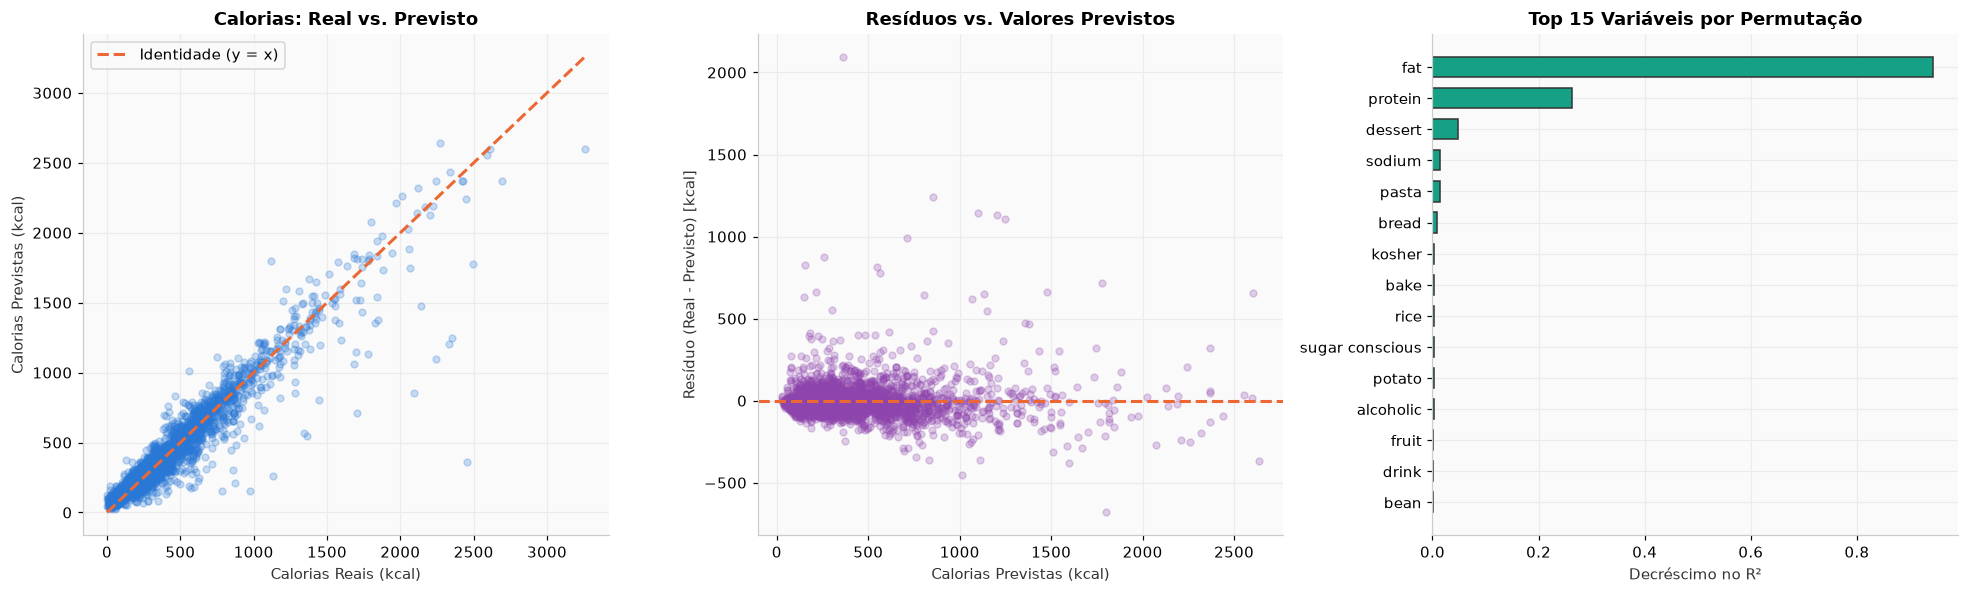

In [21]:
# %% [code]
# 1.4 Diagnóstico do Melhor Modelo (Gradient Boosting)
best_model = res_m10["modelo_fitted"]
y_pred_best = res_m10["y_pred_test"]
residuos = y_test - y_pred_best

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# 1. Real vs Previsto
axes[0].scatter(y_test, y_pred_best, alpha=0.25, color="#2a78d6", s=20)
axes[0].plot([0, y_test.max()], [0, y_test.max()], color="#eb6834", linestyle="--", linewidth=2, label="Identidade (y = x)")
axes[0].set_title("Calorias: Real vs. Previsto")
axes[0].set_xlabel("Calorias Reais (kcal)")
axes[0].set_ylabel("Calorias Previstas (kcal)")
axes[0].legend()

# 2. Resíduos vs Previsto
axes[1].scatter(y_pred_best, residuos, alpha=0.25, color="#8e44ad", s=20)
axes[1].axhline(0, color="#eb6834", linestyle="--", linewidth=2)
axes[1].set_title("Resíduos vs. Valores Previstos")
axes[1].set_xlabel("Calorias Previstas (kcal)")
axes[1].set_ylabel("Resíduo (Real - Previsto) [kcal]")

# 3. Permutation Importance (Top 15 features)
perm_imp = permutation_importance(best_model, X_test_top30, y_test, n_repeats=10, random_state=SEED, n_jobs=-1)
sorted_idx = perm_imp.importances_mean.argsort()[::-1][:15]
top_features = np.array(TOP30_FEATURES)[sorted_idx]
top_scores = perm_imp.importances_mean[sorted_idx]

y_pos = np.arange(len(top_features))
axes[2].barh(y_pos, top_scores[::-1], color="#16a085", edgecolor="#333333", height=0.65)
axes[2].set_yticks(y_pos)
axes[2].set_yticklabels(top_features[::-1])
axes[2].set_title("Top 15 Variáveis por Permutação")
axes[2].set_xlabel("Decréscimo no R²")

plt.tight_layout()
plt.savefig("figuras/modelo_final_regressao.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretação dos Diagnósticos do Modelo Final:**
- **Real vs. Previsto:** Os pontos alinham-se fortemente sobre a diagonal em toda a extensão central de calorias (100 a 1.500 kcal).
- **Comportamento dos Resíduos:** A distribuição de resíduos é centrada em zero com dispersão relativamente simétrica e homocedástica na faixa padrão de refeições. Observa-se leve subestimação em receitas hipercalóricas ($> 2.500$ kcal), decorrente de combinações atípicas de ingredientes densos.
- **Hierarquia de Importância:** A gordura (`fat`) é responsável pela esmagadora maioria da variância explicada, seguida pela proteína (`protein`). Entre as tags, `dessert` e `pasta` lideram a importância, confirmando sua função primordial em capturar carboidratos ausentes na tabela nutricional direta.

## Bloco 2 — Classificação: Categorização Automática do Tipo de Prato

**Problema de negócio.** No Epicurious, a categoria do prato (bebida, sobremesa, acompanhamento, entrada, prato principal, café da manhã) alimenta menus, filtros de busca e recomendações. Porém **5.502 das 14.096 receitas (39%) não têm nenhuma categoria** e ficam invisíveis na navegação por tipo de prato. Objetivo: um classificador que **sugira a categoria** a partir dos **ingredientes, técnicas e informação nutricional** da receita.

**Etapas:**
1. **Por que não prever o rating?** Estudo de viabilidade com 6 formulações do rating (alvo óbvio do dataset), justificando a escolha do problema.
2. **Construção do alvo multiclasse** com tratamento explícito de receitas ambíguas.
3. **Variáveis e prevenção de vazamento:** exclusão justificada das tags que *são* ou *definem* a categoria.
4. **Seleção de variáveis explícita (somente no treino):** filtros de variância e redundância, informação mútua, Lasso ($L_1$), importância por permutação e RFECV, combinados por **votação de consenso**.
5. **8 classificadores** com busca de hiperparâmetros, tratamento de desbalanceamento e métrica principal **F1-macro**.
6. **Avaliação:** matriz de confusão 6×6, métricas por classe, curvas ROC um-contra-todos, interpretação por classe, **classificação com rejeição** e aplicação às receitas sem categoria.

### 2.1 Por que não prever o rating? (estudo de viabilidade)

O `rating` é o alvo "óbvio" do dataset. Antes de descartá-lo, testamos objetivamente **todas as formulações razoáveis** com o mesmo protocolo (divisão estratificada 80/20, Gradient Boosting com todas as variáveis disponíveis). Observações importantes sobre o alvo:
- O rating tem apenas **7 valores possíveis** (1,25; 1,875; 2,5; 3,125; 3,75; 4,375; 5,0) e `rating = 0` significa **receita não avaliada**.
- Discretizar por tercis (como na primeira versão deste trabalho) repartiria receitas **com a mesma nota** entre classes diferentes — os cortes abaixo respeitam os valores da escala.
- O dataset **não informa o número de avaliações** de cada receita.

In [22]:
# 2.1 Atributos adicionais do JSON completo (usados neste bloco)
with open(caminho_json, encoding="utf-8") as f:
    receitas_json = pd.DataFrame(json.load(f))
receitas_json = receitas_json.dropna(subset=["title"]).copy()
receitas_json["titulo_chave"] = receitas_json["title"].str.strip()
receitas_json["n_ingredientes"] = receitas_json["ingredients"].apply(lambda x: len(x) if isinstance(x, list) else np.nan)
receitas_json["n_passos"] = receitas_json["directions"].apply(lambda x: len(x) if isinstance(x, list) else np.nan)
receitas_json["ano_publicacao"] = pd.to_datetime(receitas_json["date"], errors="coerce", utc=True).dt.year
extras_json = (receitas_json.drop_duplicates("titulo_chave").set_index("titulo_chave")
               [["n_ingredientes", "n_passos", "ano_publicacao"]])

dados_tipo = dados.copy()
dados_tipo["titulo_chave"] = dados_tipo["title"].str.strip()
dados_tipo = dados_tipo.join(extras_json, on="titulo_chave")
print(f"Receitas com correspondência no JSON: {dados_tipo['n_ingredientes'].notna().mean():.2%}")


def atributos_nutricionais(df_in):
    """Deriva carboidrato estimado (fatores de Atwater) e composição energética da receita."""
    out = pd.DataFrame(index=df_in.index)
    carbo = (df_in["calories"] - 9 * df_in["fat"] - 4 * df_in["protein"]).clip(lower=0) / 4
    energia = (9 * df_in["fat"] + 4 * df_in["protein"] + 4 * carbo).replace(0, np.nan)
    out["carbo_estimado_g"] = carbo
    out["pct_energia_gordura"] = 9 * df_in["fat"] / energia
    out["pct_energia_proteina"] = 4 * df_in["protein"] / energia
    out["pct_energia_carbo"] = 4 * carbo / energia
    out["sodio_por_100kcal"] = df_in["sodium"] / df_in["calories"].clip(lower=1) * 100
    return out


nutr_tipo = atributos_nutricionais(dados_tipo)
dados_tipo["log_calorias"] = np.log1p(dados_tipo["calories"])
dados_tipo["log_gordura"] = np.log1p(dados_tipo["fat"])
dados_tipo["log_proteina"] = np.log1p(dados_tipo["protein"])
dados_tipo["log_sodio"] = np.log1p(dados_tipo["sodium"])
dados_tipo["log_carbo"] = np.log1p(nutr_tipo["carbo_estimado_g"])
dados_tipo["pct_energia_gordura"] = nutr_tipo["pct_energia_gordura"]
dados_tipo["pct_energia_proteina"] = nutr_tipo["pct_energia_proteina"]
NUM_TIPO = ["log_calorias", "log_gordura", "log_proteina", "log_sodio", "log_carbo",
            "pct_energia_gordura", "pct_energia_proteina", "n_ingredientes", "n_passos"]

Receitas com correspondência no JSON: 99.98%


Formulação,Mede,Prevalência,Métrica
"Regressão da nota (1,25 a 5,0)",qualidade,—,R² = 0.038
"3 classes: baixa ≤ 3,75 | média = 4,375 | alta = 5,0",qualidade,41% / 45% / 14%,"F1-macro = 0.481 (acaso = 0,333)"
"Bem avaliada (≥ 4,375)",qualidade,59.0%,ROC-AUC = 0.619 (sem o ano: 0.610)
"Mal avaliada (≤ 3,125)",qualidade,12.3%,ROC-AUC = 0.619 (sem o ano: 0.619)
"Nota máxima (= 5,0)",qualidade?,13.7%,ROC-AUC = 0.751 (sem o ano: 0.722)
Receberá alguma avaliação? (rating > 0),engajamento,92.0%,ROC-AUC = 0.881 (sem o ano: 0.842)


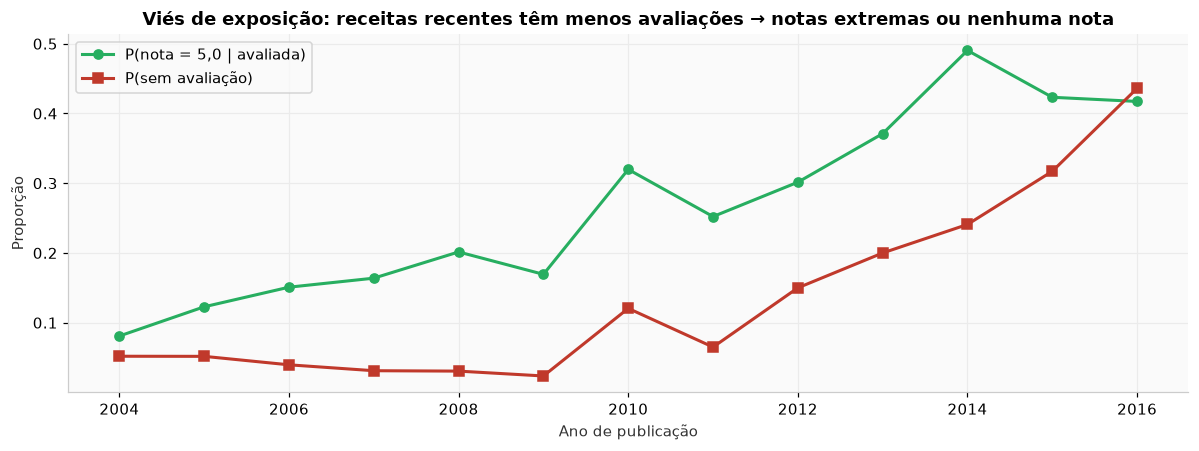

In [23]:
# 2.1 Estudo de viabilidade do rating: 6 formulações, mesmo protocolo
from sklearn.ensemble import HistGradientBoostingRegressor

feats_rating = NUM_TIPO + ["ano_publicacao"] + list(tags_mantidas)
avaliadas = dados_tipo[dados_tipo["rating"] > 0]


def gb_binario(df_alvo, alvo, cols):
    tr, te, ytr, yte = train_test_split(df_alvo[cols], alvo, test_size=0.2, random_state=SEED, stratify=alvo)
    gb = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=400, max_depth=4, random_state=SEED).fit(tr, ytr)
    return roc_auc_score(yte, gb.predict_proba(te)[:, 1])


viab = []
# (a) regressão da nota
tr, te, ytr, yte = train_test_split(avaliadas[feats_rating], avaliadas["rating"], test_size=0.2, random_state=SEED)
gbr = HistGradientBoostingRegressor(learning_rate=0.05, max_iter=400, max_depth=4, random_state=SEED).fit(tr, ytr)
viab.append({"Formulação": "Regressão da nota (1,25 a 5,0)", "Mede": "qualidade", "Prevalência": "—",
             "Métrica": f"R² = {r2_score(yte, gbr.predict(te)):.3f}"})
# (b) 3 classes com cortes nos valores da escala
y3 = pd.Series(np.select([avaliadas["rating"] <= 3.75, avaliadas["rating"] == 4.375], ["baixa", "média"], "alta"),
               index=avaliadas.index)
tr, te, ytr, yte = train_test_split(avaliadas[feats_rating], y3, test_size=0.2, random_state=SEED, stratify=y3)
gb3 = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=400, max_depth=4, class_weight="balanced",
                                     random_state=SEED).fit(tr, ytr)
p3 = gb3.predict(te)
viab.append({"Formulação": "3 classes: baixa ≤ 3,75 | média = 4,375 | alta = 5,0", "Mede": "qualidade",
             "Prevalência": "41% / 45% / 14%",
             "Métrica": f"F1-macro = {f1_score(yte, p3, average='macro'):.3f} (acaso = 0,333)"})
# (c-f) formulações binárias
sem_ano = [c for c in feats_rating if c != "ano_publicacao"]
for nome_f, mascara, base, mede in [
    ("Bem avaliada (≥ 4,375)", avaliadas["rating"] >= 4.375, avaliadas, "qualidade"),
    ("Mal avaliada (≤ 3,125)", avaliadas["rating"] <= 3.125, avaliadas, "qualidade"),
    ("Nota máxima (= 5,0)", avaliadas["rating"] == 5, avaliadas, "qualidade?"),
    ("Receberá alguma avaliação? (rating > 0)", dados_tipo["rating"] > 0, dados_tipo, "engajamento"),
]:
    alvo = mascara.astype(int)
    auc_c = gb_binario(base, alvo, feats_rating)
    auc_s = gb_binario(base, alvo, sem_ano)
    viab.append({"Formulação": nome_f, "Mede": mede, "Prevalência": f"{alvo.mean():.1%}",
                 "Métrica": f"ROC-AUC = {auc_c:.3f} (sem o ano: {auc_s:.3f})"})
display(pd.DataFrame(viab).style.hide(axis="index"))

taxa_ano = dados_tipo.groupby("ano_publicacao").agg(n=("rating", "size"),
                                                     nota_5=("rating", lambda r: (r[r > 0] == 5).mean()),
                                                     sem_avaliacao=("rating", lambda r: (r == 0).mean()))
taxa_ano = taxa_ano[taxa_ano["n"] >= 100]
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(taxa_ano.index.astype(int), taxa_ano["nota_5"], marker="o", color="#27ae60", linewidth=2, label="P(nota = 5,0 | avaliada)")
ax.plot(taxa_ano.index.astype(int), taxa_ano["sem_avaliacao"], marker="s", color="#c0392b", linewidth=2, label="P(sem avaliação)")
ax.set_xlabel("Ano de publicação")
ax.set_ylabel("Proporção")
ax.set_title("Viés de exposição: receitas recentes têm menos avaliações → notas extremas ou nenhuma nota")
ax.legend()
plt.tight_layout()
plt.savefig("figuras/rating_viabilidade.png", dpi=150, bbox_inches="tight")
plt.show()

**Conclusão do estudo de viabilidade — por que o rating não é o alvo deste trabalho:**
- **Qualidade percebida não é previsível com estes dados.** A regressão da nota explica 3,8% da variância ($R^2$ = 0,038); com 3 classes cortadas nos valores da escala, o F1-macro é 0,48 (acaso = 0,33) e o modelo praticamente não distingue "baixa" de "média"; "bem avaliada" e "mal avaliada" ficam em ROC-AUC ≈ 0,62.
- **O sinal que existe é de exposição, não de qualidade.** As duas formulações com AUC mais alto — nota máxima (0,75) e "receberá alguma avaliação?" (0,88) — dependem do ano de publicação: receitas recentes tiveram menos tempo para acumular avaliações, então têm mais notas extremas ou nenhuma nota (gráfico acima). Sem o ano, o AUC cai, e o restante vem da **fonte editorial** (receitas de *House & Garden* e *HarperCollins* ficam ~50% sem avaliação, contra ~5% das da *Bon Appétit*) e de bebidas.
- **Causa raiz:** o dataset não informa o **número de avaliações**; uma nota 5,0 dada por 1 pessoa e outra dada por 500 são indistinguíveis.
- **Testes exploratórios complementares** (fora deste notebook, mesmo protocolo): o texto completo da receita (ingredientes, preparo e descrição, via TF-IDF) acrescentou no máximo +0,005 de AUC; e a versão inicial deste trabalho, com o rating em tercis, decidia a classe de 74% das receitas pela ordem da linha (notas iguais em classes diferentes).
- **Outras alternativas descartadas:** prever **restrições alimentares** (vegetariana, sem glúten) — os rótulos são inconsistentes (4.047 receitas sem carne nem peixe nos ingredientes não têm a tag `vegetarian`), o que tornaria a avaliação enganosa; **tipo de prato a partir do texto** (TF-IDF) — +5 p.p. de F1, mas exige técnicas de processamento de linguagem fora do escopo da disciplina (fica como próximo passo).

**Decisão:** o rating fica registrado como **resultado negativo documentado**. O problema de classificação escolhido é a **categorização do tipo de prato**: rótulo editorial explícito, uso de negócio concreto (39% do catálogo sem categoria) e solucionável apenas com os métodos da disciplina sobre dados tabulares.

### 2.2 Construção do Alvo Multiclasse

As categorias vêm de tags editoriais binárias. Mapeamento: `bebida` ← `drink`; `sobremesa` ← `dessert`; `acompanhamento` ← `side`; `entrada` ← `appetizer`; `principal` ← `dinner` ou `lunch`; `café da manhã` ← `breakfast` ou `brunch`.

Uma receita pode ter **mais de uma** categoria (ex.: acompanhamento **e** prato principal). Forçar uma única classe por uma regra de prioridade arbitrária introduziria ruído de rótulo — o mesmo erro da discretização por tercis. Por isso:
- **Exatamente 1 categoria** → conjunto de modelagem (treino/teste).
- **2 ou mais categorias** → validação complementar (acerto se a classe prevista estiver entre as categorias da receita).
- **Nenhuma categoria** → conjunto de aplicação (o caso de uso real).

grupo
rotulada         7704
sem categoria    5504
ambígua           888

Combinações mais frequentes entre as ambíguas:
acompanhamento + principal    241
entrada + principal           141
sobremesa + café da manhã     118
acompanhamento + entrada       98
principal + café da manhã      67
bebida + café da manhã         56


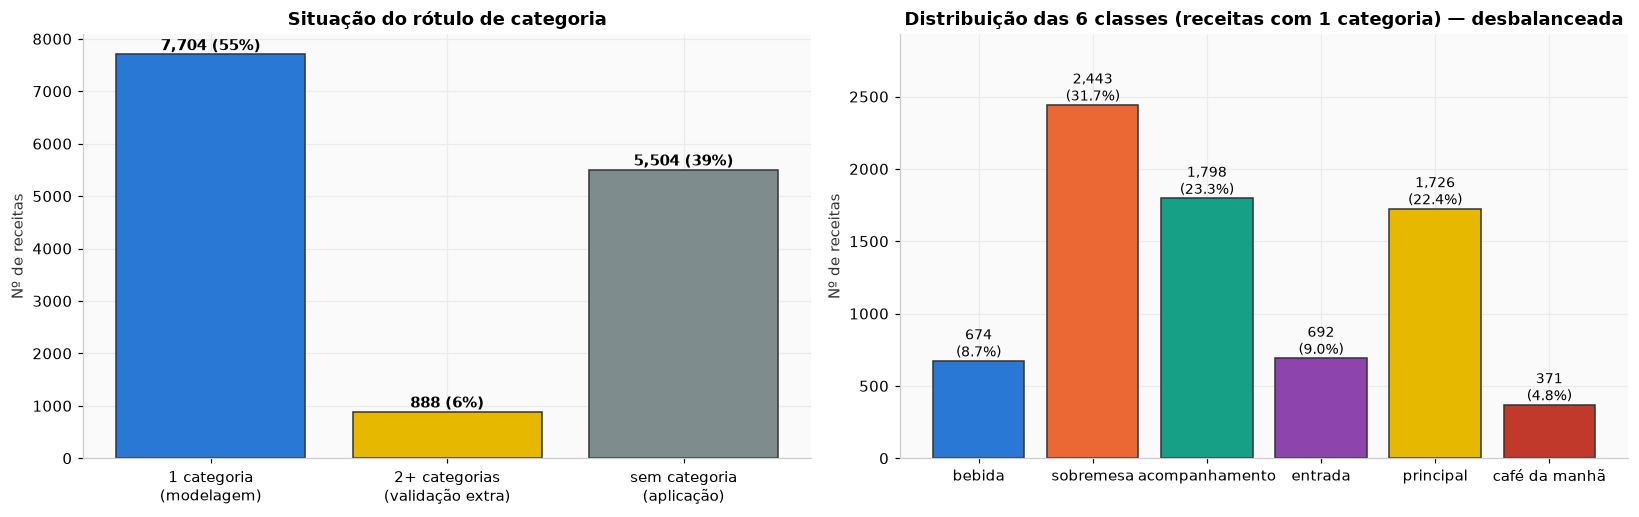

Razão entre a maior e a menor classe: 6.6×


In [24]:
# 2.2 Construção do alvo
CATEGORIAS = {
    "bebida": ["drink"],
    "sobremesa": ["dessert"],
    "acompanhamento": ["side"],
    "entrada": ["appetizer"],
    "principal": ["dinner", "lunch"],
    "café da manhã": ["breakfast", "brunch"],
}
ORDEM_CLASSES = list(CATEGORIAS)
TAGS_CATEGORIA = sorted({t for ts in CATEGORIAS.values() for t in ts})
pertence = pd.DataFrame({c: dados_tipo[ts].max(axis=1).astype(int) for c, ts in CATEGORIAS.items()},
                        index=dados_tipo.index)
n_categorias = pertence.sum(axis=1)
dados_tipo["grupo"] = np.select([n_categorias == 1, n_categorias > 1], ["rotulada", "ambígua"], default="sem categoria")
dados_tipo["tipo"] = np.where(n_categorias == 1, pertence.idxmax(axis=1), None)

print(dados_tipo["grupo"].value_counts().to_string())
print("\nCombinações mais frequentes entre as ambíguas:")
print(pertence[n_categorias > 1].apply(lambda r: " + ".join(r.index[r == 1]), axis=1).value_counts().head(6).to_string())

dist_tipo = dados_tipo.loc[dados_tipo["grupo"] == "rotulada", "tipo"].value_counts().reindex(ORDEM_CLASSES)
contagem_grupo = dados_tipo["grupo"].value_counts().reindex(["rotulada", "ambígua", "sem categoria"])
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
axes[0].bar(["1 categoria\n(modelagem)", "2+ categorias\n(validação extra)", "sem categoria\n(aplicação)"],
            contagem_grupo.values, color=["#2a78d6", "#e6b800", "#7f8c8d"], edgecolor="#333333")
for i, v in enumerate(contagem_grupo.values):
    axes[0].text(i, v + 80, f"{v:,} ({v / len(dados_tipo):.0%})", ha="center", fontweight="bold")
axes[0].set_title("Situação do rótulo de categoria")
axes[0].set_ylabel("Nº de receitas")
axes[1].bar(dist_tipo.index, dist_tipo.values, color=PALETA[:6], edgecolor="#333333")
for i, v in enumerate(dist_tipo.values):
    axes[1].text(i, v + 30, f"{v:,}\n({v / dist_tipo.sum():.1%})", ha="center", fontsize=9)
axes[1].set_title("Distribuição das 6 classes (receitas com 1 categoria) — desbalanceada")
axes[1].set_ylabel("Nº de receitas")
axes[1].set_ylim(0, dist_tipo.max() * 1.2)
plt.tight_layout()
plt.savefig("figuras/classificacao_alvo.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Razão entre a maior e a menor classe: {dist_tipo.max() / dist_tipo.min():.1f}×")

### 2.3 Variáveis Candidatas e Prevenção de Vazamento

**Numéricas (9):** `log` de calorias, gordura, proteína, sódio e carboidrato estimado (fatores de Atwater: $(\text{cal} - 9\cdot\text{fat} - 4\cdot\text{protein})/4$); fração da energia vinda de gordura e de proteína; nº de ingredientes e nº de passos (do JSON). O `log1p` reduz a assimetria das quantidades.

**Tags binárias:** ingredientes (`chocolate`, `tequila`, `beef`), técnicas (`bake`, `grill`, `blender`), ocasiões (`thanksgiving`, `picnic`), dietas e fontes editoriais.

**Exclusões para evitar vazamento** (o modelo não pode "ler" a resposta):
1. As **tags que definem as categorias** (`drink`, `dessert`, `side`, `appetizer`, `dinner`, `lunch`, `breakfast`, `brunch`).
2. As **tags que nomeiam um tipo de prato ou de refeição** — são, na prática, subcategorias do alvo (ex.: toda receita `cake` é sobremesa): `cake`, `cookie`, `cookies`, `frozen dessert`, `pastry`, `salad`, `salad dressing`, `soup/stew`, `stew`, `sandwich`, `sauce`, `condiment`, `condiment/spread`, `jam or jelly`, `bread`, `casserole/gratin`, `stuffing/dressing`, `cocktail`, `cocktail party`, `non-alcoholic`.

Mantêm-se ingredientes, técnicas, equipamentos e ocasiões, que existem em qualquer receita independentemente da categoria editorial — mesmo quando muito associados a uma classe (ex.: `gin` → bebida). A tabela abaixo mostra a **pureza** (proporção da classe dominante) das tags excluídas, confirmando que elas praticamente determinam a categoria.

In [25]:
# 2.3 Exclusão justificada de tags e divisão treino/teste
TAGS_TIPO_PRATO = ["cake", "cookie", "cookies", "frozen dessert", "pastry", "salad", "salad dressing", "soup/stew", "stew",
                   "sandwich", "sauce", "condiment", "condiment/spread", "jam or jelly", "bread", "casserole/gratin",
                   "stuffing/dressing", "cocktail", "cocktail party", "non-alcoholic"]
TAGS_EXCLUIDAS = [t for t in TAGS_CATEGORIA + TAGS_TIPO_PRATO if t in tags_mantidas]
TAGS_PERMITIDAS = [t for t in tags_mantidas if t not in TAGS_EXCLUIDAS]

rotuladas = dados_tipo[dados_tipo["grupo"] == "rotulada"]
pureza = []
for t in [t for t in TAGS_TIPO_PRATO if t in tags_mantidas]:
    sub = rotuladas.loc[rotuladas[t] == 1, "tipo"]
    if len(sub):
        pureza.append({"Tag excluída": t, "Receitas rotuladas com a tag": len(sub),
                       "Classe dominante": sub.value_counts().idxmax(), "Pureza": sub.value_counts(normalize=True).max()})
display(pd.DataFrame(pureza).sort_values("Pureza", ascending=False).style.format({"Pureza": "{:.0%}"}).hide(axis="index"))

FEAT_CAND_T = NUM_TIPO + TAGS_PERMITIDAS
X_tipo = rotuladas[FEAT_CAND_T]
y_tipo = rotuladas["tipo"]
X_tr_t, X_te_t, y_tr_t, y_te_t = train_test_split(X_tipo, y_tipo, test_size=0.20, random_state=SEED, stratify=y_tipo)
print(f"Tags excluídas: {len(TAGS_EXCLUIDAS)} | variáveis candidatas: {len(FEAT_CAND_T)} "
      f"({len(NUM_TIPO)} numéricas + {len(TAGS_PERMITIDAS)} tags)")
print(f"Treino: {len(X_tr_t):,} | Teste: {len(X_te_t):,} (estratificado 80/20, random_state={SEED})")

print("Perfil numérico médio por classe (treino):")
display(X_tr_t[NUM_TIPO].assign(tipo=y_tr_t).groupby("tipo").mean().reindex(ORDEM_CLASSES)
        .style.format("{:.2f}").background_gradient(cmap="Blues", axis=0))

Tag excluída,Receitas rotuladas com a tag,Classe dominante,Pureza
cocktail,213,bebida,100%
cookies,160,sobremesa,99%
non-alcoholic,119,bebida,99%
frozen dessert,230,sobremesa,99%
stuffing/dressing,76,acompanhamento,99%
cake,513,sobremesa,95%
sandwich,137,principal,90%
jam or jelly,74,sobremesa,85%
casserole/gratin,109,acompanhamento,81%
stew,33,principal,79%


Tags excluídas: 28 | variáveis candidatas: 313 (9 numéricas + 304 tags)
Treino: 6,163 | Teste: 1,541 (estratificado 80/20, random_state=42)
Perfil numérico médio por classe (treino):


,log_calorias,log_gordura,log_proteina,log_sodio,log_carbo,pct_energia_gordura,pct_energia_proteina,n_ingredientes,n_passos
tipo,,,,,,,,,
bebida,5.24,0.48,0.54,2.42,3.77,0.06,0.02,5.93,1.43
sobremesa,5.86,2.72,1.71,4.47,3.77,0.42,0.05,11.22,4.51
acompanhamento,5.47,2.43,1.89,5.16,3.18,0.45,0.10,8.29,2.78
entrada,5.46,2.70,2.29,5.80,2.61,0.55,0.17,10.76,3.66
principal,6.29,3.43,3.39,6.35,3.23,0.52,0.24,12.11,4.39
café da manhã,5.86,2.81,2.43,5.70,3.30,0.47,0.14,10.16,3.55


### 2.4 Seleção de Variáveis (somente no conjunto de treino)

Mesmo protocolo de consenso, adaptado para 6 classes (critério: **F1-macro**, a média do F1 das 6 classes com peso igual — adequada ao desbalanceamento, pois um modelo que ignora "café da manhã" é penalizado, o que não aconteceria com a acurácia):

| Etapa | Família | Método | Critério de corte |
|---|---|---|---|
| 1 | Filtro | Variância | Remove tags presentes em < 1% das receitas do treino |
| 2 | Filtro | Redundância (correlação de Pearson) | Em pares com \|r\| > 0,90, remove a de menor informação mútua |
| 3 | Filtro | Informação mútua com a classe | Top-*k*, com *k* escolhido por **validação cruzada aninhada** |
| 4 | Embutido | Regressão Logística $L_1$ (Lasso multinomial) | Coeficiente ≠ 0 em ao menos uma classe, no *C* de maior F1-macro |
| 5 | Embutido (modelo) | Importância por permutação (Gradient Boosting) | Queda média de F1-macro − 1 dp > 0 em validação interna |
| 6 | Wrapper | RFECV (eliminação recursiva com CV) | Subconjunto de maior F1-macro |
| — | **Consenso** | Votação | Variável mantida se recebe **≥ 2 votos** entre as etapas 3–6 |

In [26]:
# 2.4 (Etapas 1 e 2) Filtros de variância e redundância + ranking por informação mútua
skf_tipo = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
imputador_t = SimpleImputer(strategy="median").fit(X_tr_t)
X_tr_imp_t = pd.DataFrame(imputador_t.transform(X_tr_t), columns=FEAT_CAND_T, index=X_tr_t.index)

prev_tags_t = X_tr_imp_t[TAGS_PERMITIDAS].mean()
rem_var_t = prev_tags_t[prev_tags_t < 0.01].index.tolist()
feats_e1 = [c for c in FEAT_CAND_T if c not in rem_var_t]

mask_e1 = np.array([c in TAGS_PERMITIDAS for c in feats_e1])
mi_t = pd.Series(mutual_info_classif(X_tr_imp_t[feats_e1], y_tr_t, discrete_features=mask_e1, random_state=SEED),
                 index=feats_e1).sort_values(ascending=False)

corr_t = X_tr_imp_t[feats_e1].corr().abs()
pares_t = corr_t.where(np.triu(np.ones(corr_t.shape, dtype=bool), k=1)).stack()
pares_t = pares_t[pares_t > 0.90]
rem_red_t = sorted({a if mi_t[a] < mi_t[b] else b for a, b in pares_t.index})
feats_e2 = [c for c in feats_e1 if c not in rem_red_t]

print(f"Candidatas iniciais:                     {len(FEAT_CAND_T)}")
print(f"Etapa 1 — removidas por baixa variância: {len(rem_var_t)} tags (prevalência < 1%)")
print(f"Etapa 2 — pares com |r| > 0,90:          {[f'{a} ~ {b} (r={v:.2f})' for (a, b), v in pares_t.items()]}")
print(f"          removidas por redundância:     {rem_red_t}")
print(f"Variáveis após os filtros:               {len(feats_e2)}")

Candidatas iniciais:                     313
Etapa 1 — removidas por baixa variância: 115 tags (prevalência < 1%)
Etapa 2 — pares com |r| > 0,90:          []
          removidas por redundância:     []
Variáveis após os filtros:               198


Etapa 3 — Informação mútua: k ótimo = 160 (F1-macro CV = 0.7245; com todas as 198: 0.7170)
Etapa 4 — Lasso L1:         C ótimo = 0.03 → 177 variáveis com coeficiente não nulo
Etapa 5 — Permutação (HGB): 77 variáveis com importância significativamente positiva
Etapa 6 — RFECV:            148 variáveis no subconjunto ótimo
Tempo total da seleção: 390s


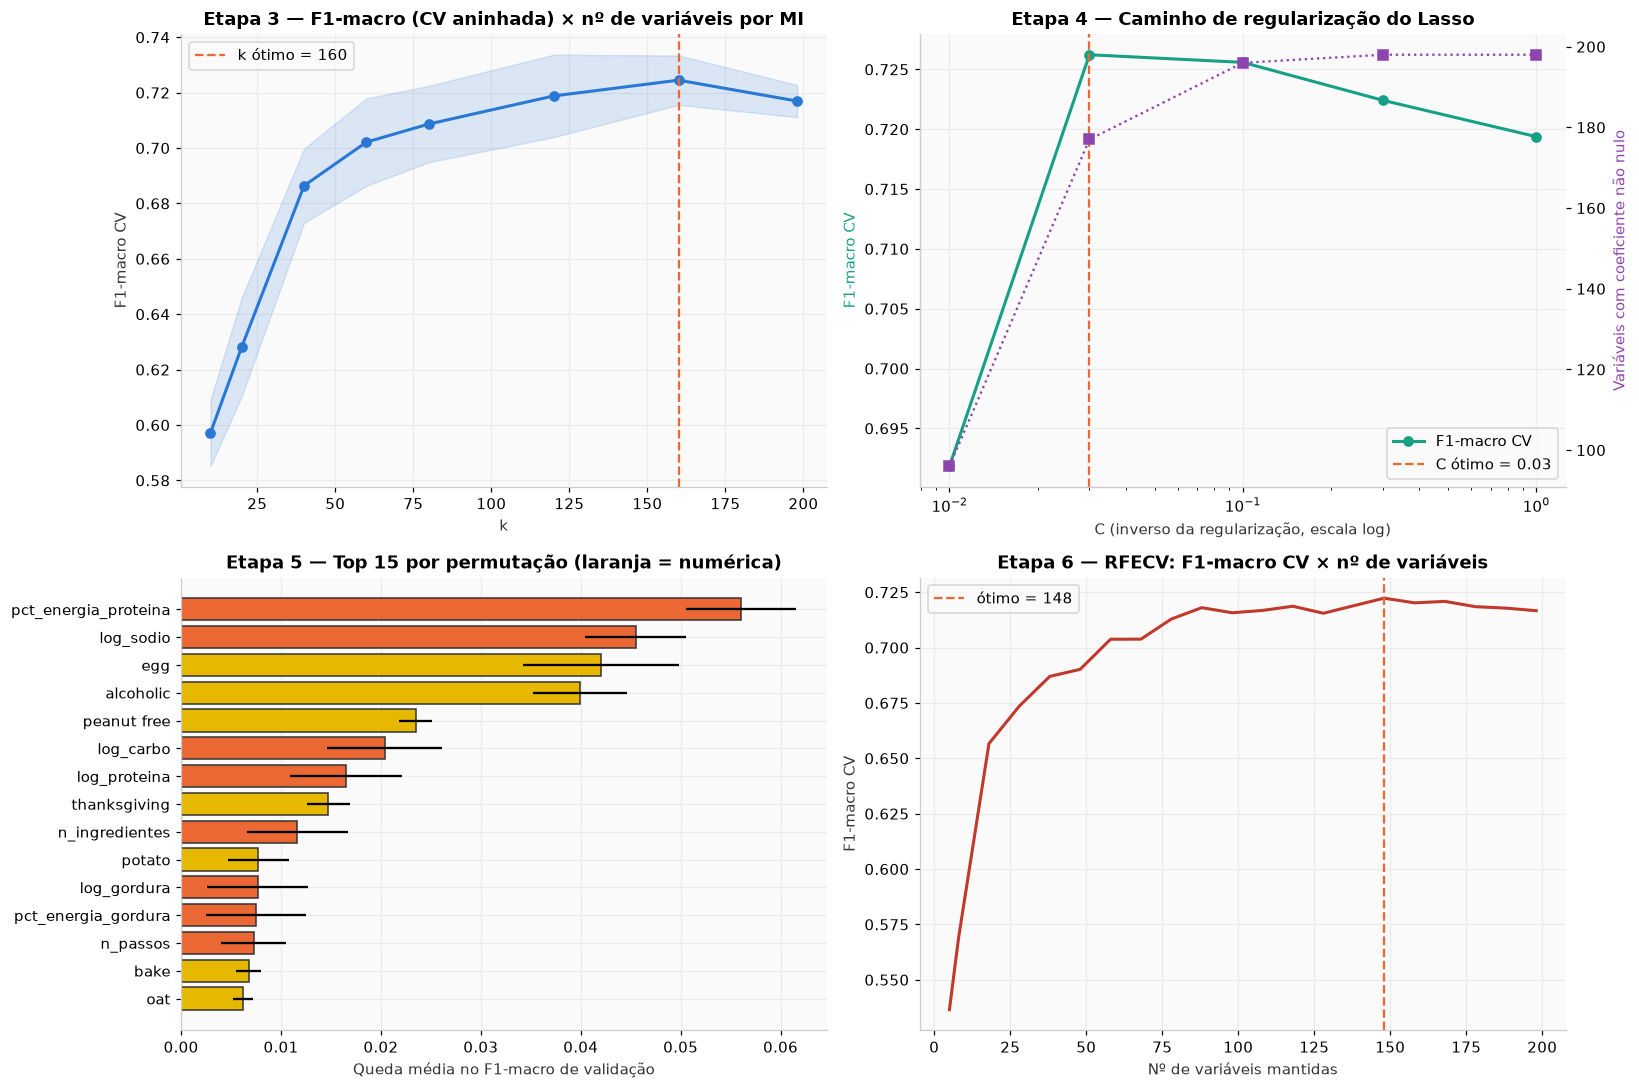

In [27]:
# 2.4 (Etapas 3 a 6) Informação mútua com k por CV aninhada, Lasso L1, permutação e RFECV
t_inicio = time.time()
ref_logit = lambda: LogisticRegression(C=1.0, class_weight="balanced", max_iter=5000)

# Etapa 3 — curva F1-macro × k (SelectKBest refeito dentro de cada fold → sem viés de seleção)
mask_e2 = np.array([c in TAGS_PERMITIDAS for c in feats_e2])
mi_func_t = partial(mutual_info_classif, discrete_features=mask_e2, random_state=SEED)
ks_t = [10, 20, 40, 60, 80, 120, 160, len(feats_e2)]
curva_k_t = {}
for k in ks_t:
    pipe_k = Pipeline([("imp", SimpleImputer(strategy="median")), ("kbest", SelectKBest(mi_func_t, k=k)),
                       ("sc", StandardScaler()), ("clf", ref_logit())])
    s_k = cross_val_score(pipe_k, X_tr_t[feats_e2], y_tr_t, cv=skf_tipo, scoring="f1_macro", n_jobs=-1)
    curva_k_t[k] = (s_k.mean(), s_k.std())
k_mi_t = max(curva_k_t, key=lambda k: curva_k_t[k][0])
sel_mi_t = mi_t.reindex(feats_e2).sort_values(ascending=False).head(k_mi_t).index.tolist()

# Etapa 4 — Lasso logístico multinomial (solver saga): caminho de regularização
Cs_t = [0.01, 0.03, 0.1, 0.3, 1.0]
curva_l1_t = []
for C in Cs_t:
    pipe_l1 = Pipeline([("sc", StandardScaler()),
                        ("clf", LogisticRegression(l1_ratio=1.0, solver="saga", C=C, class_weight="balanced", max_iter=3000, tol=1e-3))])
    s_l1 = cross_val_score(pipe_l1, X_tr_imp_t[feats_e2], y_tr_t, cv=skf_tipo, scoring="f1_macro", n_jobs=-1)
    nz = int((np.abs(pipe_l1.fit(X_tr_imp_t[feats_e2], y_tr_t)[-1].coef_).sum(axis=0) > 0).sum())
    curva_l1_t.append({"C": C, "f1": s_l1.mean(), "nao_nulos": nz})
curva_l1_t = pd.DataFrame(curva_l1_t)
C_l1_t = curva_l1_t.loc[curva_l1_t["f1"].idxmax(), "C"]
lasso_t = Pipeline([("sc", StandardScaler()),
                    ("clf", LogisticRegression(l1_ratio=1.0, solver="saga", C=C_l1_t, class_weight="balanced", tol=1e-3,
                                               max_iter=5000))]).fit(X_tr_imp_t[feats_e2], y_tr_t)
sel_l1_t = list(np.array(feats_e2)[np.abs(lasso_t[-1].coef_).sum(axis=0) > 0])

# Etapa 5 — importância por permutação (Gradient Boosting, validação interna de 25% do treino)
X_sub_t, X_val_t, y_sub_t, y_val_t = train_test_split(X_tr_imp_t[feats_e2], y_tr_t, test_size=0.25,
                                                      random_state=SEED, stratify=y_tr_t)
hgb_sel_t = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, random_state=SEED).fit(X_sub_t, y_sub_t)
perm_t = permutation_importance(hgb_sel_t, X_val_t, y_val_t, scoring="f1_macro", n_repeats=5, random_state=SEED, n_jobs=-1)
imp_perm_t = pd.DataFrame({"media": perm_t.importances_mean, "dp": perm_t.importances_std}, index=feats_e2)
sel_perm_t = imp_perm_t.index[(imp_perm_t["media"] - imp_perm_t["dp"]) > 0].tolist()

# Etapa 6 — RFECV com Regressão Logística multinomial
X_tr_esc_t = pd.DataFrame(StandardScaler().fit_transform(X_tr_imp_t[feats_e2]), columns=feats_e2, index=X_tr_t.index)
rfecv_t = RFECV(ref_logit(), step=10, cv=skf_tipo, scoring="f1_macro", min_features_to_select=5, n_jobs=-1).fit(X_tr_esc_t, y_tr_t)
sel_rfe_t = list(np.array(feats_e2)[rfecv_t.support_])

print(f"Etapa 3 — Informação mútua: k ótimo = {k_mi_t} (F1-macro CV = {curva_k_t[k_mi_t][0]:.4f}; "
      f"com todas as {len(feats_e2)}: {curva_k_t[len(feats_e2)][0]:.4f})")
print(f"Etapa 4 — Lasso L1:         C ótimo = {C_l1_t} → {len(sel_l1_t)} variáveis com coeficiente não nulo")
print(f"Etapa 5 — Permutação (HGB): {len(sel_perm_t)} variáveis com importância significativamente positiva")
print(f"Etapa 6 — RFECV:            {rfecv_t.n_features_} variáveis no subconjunto ótimo")
print(f"Tempo total da seleção: {time.time() - t_inicio:.0f}s")

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
ks_arr = np.array(list(curva_k_t.keys()))
med = np.array([v[0] for v in curva_k_t.values()])
dp = np.array([v[1] for v in curva_k_t.values()])
axes[0, 0].plot(ks_arr, med, marker="o", color="#2a78d6", linewidth=2)
axes[0, 0].fill_between(ks_arr, med - dp, med + dp, color="#2a78d6", alpha=0.15)
axes[0, 0].axvline(k_mi_t, color="#eb6834", linestyle="--", label=f"k ótimo = {k_mi_t}")
axes[0, 0].set_title("Etapa 3 — F1-macro (CV aninhada) × nº de variáveis por MI")
axes[0, 0].set_xlabel("k")
axes[0, 0].set_ylabel("F1-macro CV")
axes[0, 0].legend()

ax_b = axes[0, 1]
ax_b.plot(curva_l1_t["C"], curva_l1_t["f1"], marker="o", color="#16a085", linewidth=2, label="F1-macro CV")
ax_b.set_xscale("log")
ax_b.axvline(C_l1_t, color="#eb6834", linestyle="--", label=f"C ótimo = {C_l1_t}")
ax_b.set_xlabel("C (inverso da regularização, escala log)")
ax_b.set_ylabel("F1-macro CV", color="#16a085")
ax_b2 = ax_b.twinx()
ax_b2.plot(curva_l1_t["C"], curva_l1_t["nao_nulos"], marker="s", color="#8e44ad", linestyle=":")
ax_b2.set_ylabel("Variáveis com coeficiente não nulo", color="#8e44ad")
ax_b2.grid(False)
ax_b.set_title("Etapa 4 — Caminho de regularização do Lasso")
ax_b.legend(loc="lower right")

top_perm_t = imp_perm_t.sort_values("media", ascending=False).head(15)[::-1]
axes[1, 0].barh(top_perm_t.index, top_perm_t["media"], xerr=top_perm_t["dp"],
                color=["#eb6834" if c in NUM_TIPO else "#e6b800" for c in top_perm_t.index], edgecolor="#333333")
axes[1, 0].set_title("Etapa 5 — Top 15 por permutação (laranja = numérica)")
axes[1, 0].set_xlabel("Queda média no F1-macro de validação")

n_feats_rfe_t = rfecv_t.cv_results_.get("n_features", np.arange(len(rfecv_t.cv_results_["mean_test_score"])))
axes[1, 1].plot(n_feats_rfe_t, rfecv_t.cv_results_["mean_test_score"], color="#c0392b", linewidth=2)
axes[1, 1].axvline(rfecv_t.n_features_, color="#eb6834", linestyle="--", label=f"ótimo = {rfecv_t.n_features_}")
axes[1, 1].set_title("Etapa 6 — RFECV: F1-macro CV × nº de variáveis")
axes[1, 1].set_xlabel("Nº de variáveis mantidas")
axes[1, 1].set_ylabel("F1-macro CV")
axes[1, 1].legend()
plt.tight_layout()
plt.savefig("figuras/selecao_variaveis_classificacao.png", dpi=150, bbox_inches="tight")
plt.show()

Distribuição de votos: {0: 5, 1: 18, 2: 36, 3: 84, 4: 55}

VARIÁVEIS SELECIONADAS (≥ 2 votos): 175 de 313 candidatas (9 numéricas + 166 tags)
Numéricas selecionadas: ['log_calorias', 'log_gordura', 'log_proteina', 'log_sodio', 'log_carbo', 'pct_energia_gordura', 'pct_energia_proteina', 'n_ingredientes', 'n_passos']
Numéricas descartadas:  []

Top 25 variáveis selecionadas (ordenadas por votos e informação mútua):


,Filtro MI,Lasso L1,Permutação,RFECV,Total de votos,MI
pct_energia_proteina,1,1,1,1,4,0.4900
log_proteina,1,1,1,1,4,0.4004
log_sodio,1,1,1,1,4,0.2832
log_gordura,1,1,1,1,4,0.2348
alcoholic,1,1,1,1,4,0.2061
pct_energia_gordura,1,1,1,1,4,0.1912
vegetarian,1,1,1,1,4,0.1459
no sugar added,1,1,1,1,4,0.1430
n_ingredientes,1,1,1,1,4,0.1300
bake,1,1,1,1,4,0.1286


Conjunto,F1-macro CV — Logística,F1-macro CV — Gradient Boosting
Após filtros (198),0.7170 ± 0.0058,0.7579 ± 0.0085
Consenso ≥ 2 votos (175),0.7227 ± 0.0073,0.7539 ± 0.0072


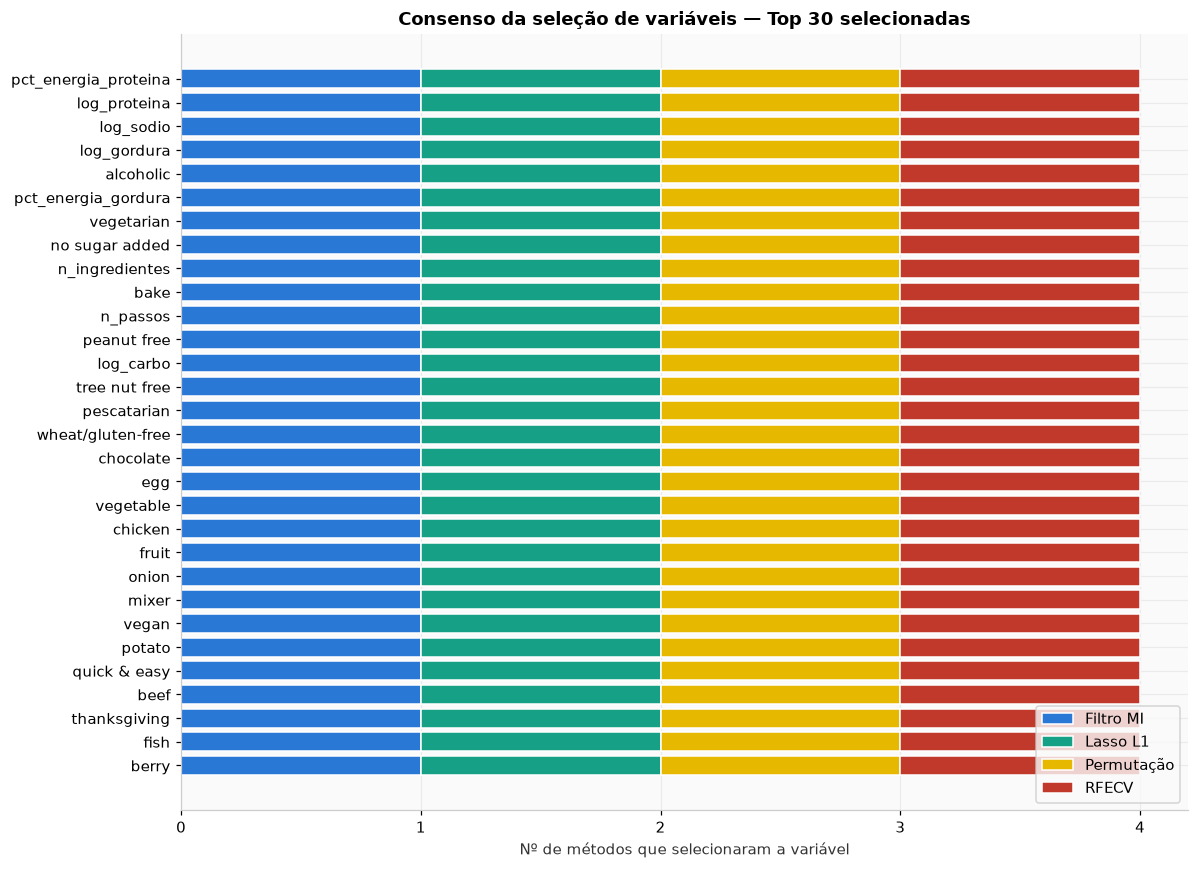

In [28]:
# 2.4 Consenso entre os métodos
votos_t = pd.DataFrame(index=feats_e2)
votos_t["Filtro MI"] = votos_t.index.isin(sel_mi_t)
votos_t["Lasso L1"] = votos_t.index.isin(sel_l1_t)
votos_t["Permutação"] = votos_t.index.isin(sel_perm_t)
votos_t["RFECV"] = votos_t.index.isin(sel_rfe_t)
votos_t = votos_t.astype(int)
votos_t["Total de votos"] = votos_t.sum(axis=1)
votos_t["MI"] = mi_t.reindex(votos_t.index)

FEAT_SEL_T = votos_t.index[votos_t["Total de votos"] >= 2].tolist()
num_sel_t = [c for c in FEAT_SEL_T if c in NUM_TIPO]
bin_sel_t = [c for c in FEAT_SEL_T if c not in NUM_TIPO]
print("Distribuição de votos:", votos_t["Total de votos"].value_counts().sort_index().to_dict())
print(f"\nVARIÁVEIS SELECIONADAS (≥ 2 votos): {len(FEAT_SEL_T)} de {len(FEAT_CAND_T)} candidatas "
      f"({len(num_sel_t)} numéricas + {len(bin_sel_t)} tags)")
print(f"Numéricas selecionadas: {num_sel_t}")
print(f"Numéricas descartadas:  {[c for c in NUM_TIPO if c not in num_sel_t]}")

print("\nTop 25 variáveis selecionadas (ordenadas por votos e informação mútua):")
display(votos_t.loc[FEAT_SEL_T].sort_values(["Total de votos", "MI"], ascending=False).head(25)
        .style.format({"MI": "{:.4f}"}).background_gradient(subset=["Total de votos"], cmap="Greens"))

comparacao_sel_t = []
for nome_conj, cols in [(f"Após filtros ({len(feats_e2)})", feats_e2), (f"Consenso ≥ 2 votos ({len(FEAT_SEL_T)})", FEAT_SEL_T)]:
    lin = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()), ("clf", ref_logit())])
    hgb = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, random_state=SEED)
    a = cross_val_score(lin, X_tr_t[cols], y_tr_t, cv=skf_tipo, scoring="f1_macro", n_jobs=-1)
    b = cross_val_score(hgb, X_tr_t[cols], y_tr_t, cv=skf_tipo, scoring="f1_macro", n_jobs=-1)
    comparacao_sel_t.append({"Conjunto": nome_conj,
                             "F1-macro CV — Logística": f"{a.mean():.4f} ± {a.std():.4f}",
                             "F1-macro CV — Gradient Boosting": f"{b.mean():.4f} ± {b.std():.4f}"})
display(pd.DataFrame(comparacao_sel_t).style.hide(axis="index"))

fig, ax = plt.subplots(figsize=(11, 8))
top_v = votos_t.loc[FEAT_SEL_T].sort_values(["Total de votos", "MI"], ascending=False).head(30)[::-1]
esq = np.zeros(len(top_v))
for m, cor in zip(["Filtro MI", "Lasso L1", "Permutação", "RFECV"], ["#2a78d6", "#16a085", "#e6b800", "#c0392b"]):
    ax.barh(top_v.index, top_v[m], left=esq, color=cor, edgecolor="white", label=m)
    esq += top_v[m].values
ax.set_xlabel("Nº de métodos que selecionaram a variável")
ax.set_title("Consenso da seleção de variáveis — Top 30 selecionadas")
ax.set_xticks([0, 1, 2, 3, 4])
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("figuras/consenso_variaveis.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretação da seleção de variáveis:**
- **Filtros:** 115 tags presentes em menos de 1% das receitas do treino foram removidas; nenhum par de variáveis tinha \|r\| > 0,90 (sem redundância forte).
- **Informação mútua (CV aninhada):** o F1-macro atinge o pico com **k = 160** variáveis (0,7245), acima do conjunto completo de 198 (0,7170). Como o `SelectKBest` é refeito dentro de cada fold, essa comparação não tem viés de seleção.
- **Lasso multinomial:** melhor F1-macro com C = 0,03, mantendo 177 variáveis com coeficiente não nulo. **Permutação:** 77 variáveis com importância significativamente positiva (o critério mais restritivo). **RFECV:** 148.
- **Consenso:** 55 variáveis receberam os 4 votos, 84 receberam 3 e 36 receberam 2 → **175 variáveis** (9 numéricas + 166 tags), **44% menos** que as 313 candidatas.
- **O que é mais informativo:** as **9 variáveis nutricionais foram todas selecionadas** e lideram a informação mútua — `pct_energia_proteina` (0,49), `log_proteina` (0,40), `log_sodio` (0,28), `log_gordura` (0,23). Faz sentido: pratos principais concentram proteína e sódio; bebidas e sobremesas, quase nada. Entre as tags, as mais informativas são `alcoholic`, marcadores de dieta (`vegetarian`, `no sugar added`, `peanut free`, `pescatarian`), técnicas (`bake`) e ingredientes (`chocolate`, `egg`, `chicken`, `fruit`, `onion`).
- **Validação:** com o conjunto de consenso, o F1-macro em CV fica equivalente ao do conjunto completo (Logística 0,717 → 0,723; Gradient Boosting 0,758 → 0,754): **mesmo desempenho com 44% menos variáveis**, modelos mais simples e interpretáveis. A estimativa honesta de desempenho é a do teste (seção 2.6), que não participou da seleção.

### 2.5 Treinamento dos 8 Classificadores

**Protocolo comum** (função `ajustar_classificador`):
- Variáveis: o subconjunto de consenso `FEAT_SEL_T`.
- `GridSearchCV` com `StratifiedKFold` (5 folds, `random_state=42`), critério **F1-macro**; acurácia também registrada.
- Desbalanceamento (a maior classe tem ~6,6× a menor): `class_weight="balanced"` nos modelos que o aceitam; nos demais, a escolha dos hiperparâmetros por F1-macro já favorece as classes raras.
- Linha de base: `DummyClassifier` que sempre prevê a classe mais frequente.
- Avaliação única no teste: acurácia, acurácia balanceada, F1-macro, F1 ponderado e **ROC-AUC macro um-contra-todos** (a partir das probabilidades).

| # | Modelo | Pré-processamento | Hiperparâmetros buscados |
|---|---|---|---|
| 1 | Regressão Logística multinomial | imputação + padronização | `C` |
| 2 | LDA | imputação + padronização | `shrinkage` |
| 3 | QDA | imputação + padronização | `reg_param` |
| 4 | Naive Bayes (Bernoulli) | numéricas discretizadas em quintis (one-hot) + tags | `alpha` |
| 5 | KNN | imputação + padronização | `n_neighbors`, `weights` |
| 6 | SVM (kernel RBF) | imputação + padronização | `C`, `gamma` |
| 7 | Random Forest | imputação | `max_features`, `min_samples_leaf` |
| 8 | Gradient Boosting (Hist) | — | `learning_rate`, `max_depth` |

In [29]:
# 2.5 Função de ajuste e avaliação
def ajustar_classificador(nome, pipe, grade):
    t0 = time.time()
    busca = GridSearchCV(pipe, grade, cv=skf_tipo, n_jobs=-1, refit="f1_macro",
                         scoring={"f1_macro": "f1_macro", "acc": "accuracy"})
    busca.fit(X_tr_t[FEAT_SEL_T], y_tr_t)
    i = busca.best_index_
    modelo = busca.best_estimator_
    proba = modelo.predict_proba(X_te_t[FEAT_SEL_T])
    y_hat = modelo.classes_[np.argmax(proba, axis=1)]
    res = {
        "Modelo": nome,
        "Melhores hiperparâmetros": ", ".join(f"{k.split('__')[-1]}={v}" for k, v in busca.best_params_.items()) or "—",
        "F1-macro CV": busca.cv_results_["mean_test_f1_macro"][i],
        "dp CV": busca.cv_results_["std_test_f1_macro"][i],
        "Acurácia CV": busca.cv_results_["mean_test_acc"][i],
        "Acurácia": accuracy_score(y_te_t, y_hat),
        "Acurácia Balanceada": balanced_accuracy_score(y_te_t, y_hat),
        "F1-macro": f1_score(y_te_t, y_hat, average="macro"),
        "F1 ponderado": f1_score(y_te_t, y_hat, average="weighted"),
        "ROC-AUC (OvR)": roc_auc_score(y_te_t, proba, multi_class="ovr", average="macro", labels=modelo.classes_),
        "Tempo (s)": time.time() - t0,
        "modelo": modelo, "proba": proba, "y_hat": y_hat,
    }
    print(f"[{nome:28s}] F1-macro CV={res['F1-macro CV']:.3f} | teste: F1-macro={res['F1-macro']:.3f} "
          f"acc={res['Acurácia']:.3f} AUC={res['ROC-AUC (OvR)']:.3f} | {res['Melhores hiperparâmetros']} "
          f"({res['Tempo (s)']:.0f}s)")
    return res


def prep_t(escalar=True):
    passos = [("imp", SimpleImputer(strategy="median"))]
    if escalar:
        passos.append(("sc", StandardScaler()))
    return passos


resultados_tipo = []
resultados_tipo.append(ajustar_classificador(
    "0. Baseline (classe majoritária)", Pipeline([("clf", DummyClassifier(strategy="most_frequent"))]), {}))
resultados_tipo.append(ajustar_classificador(
    "1. Regressão Logística",
    Pipeline(prep_t() + [("clf", LogisticRegression(class_weight="balanced", max_iter=5000))]),
    {"clf__C": [0.03, 0.1, 0.3, 1.0, 3.0]}))
resultados_tipo.append(ajustar_classificador(
    "2. LDA",
    Pipeline(prep_t() + [("clf", LinearDiscriminantAnalysis(solver="lsqr"))]),
    {"clf__shrinkage": [None, "auto", 0.1, 0.3]}))
resultados_tipo.append(ajustar_classificador(
    "3. QDA",
    Pipeline(prep_t() + [("clf", QuadraticDiscriminantAnalysis())]),
    {"clf__reg_param": [0.1, 0.3, 0.5, 0.8]}))
pre_nb_t = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("kb", KBinsDiscretizer(n_bins=5, encode="onehot", strategy="quantile"))]), num_sel_t),
    ("bin", "passthrough", bin_sel_t),
])
resultados_tipo.append(ajustar_classificador(
    "4. Naive Bayes (Bernoulli)",
    Pipeline([("pre", pre_nb_t), ("clf", BernoulliNB())]),
    {"clf__alpha": [0.1, 0.3, 1.0, 3.0]}))

[0. Baseline (classe majoritária)] F1-macro CV=0.080 | teste: F1-macro=0.080 acc=0.317 AUC=0.500 | — (0s)


[1. Regressão Logística      ] F1-macro CV=0.728 | teste: F1-macro=0.732 acc=0.788 AUC=0.949 | C=0.03 (2s)


[2. LDA                      ] F1-macro CV=0.735 | teste: F1-macro=0.722 acc=0.799 AUC=0.941 | shrinkage=auto (1s)


[3. QDA                      ] F1-macro CV=0.689 | teste: F1-macro=0.695 acc=0.761 AUC=0.934 | reg_param=0.8 (1s)


[4. Naive Bayes (Bernoulli)  ] F1-macro CV=0.685 | teste: F1-macro=0.686 acc=0.784 AUC=0.933 | alpha=0.1 (0s)


In [30]:
# 2.5 (continuação) Modelos baseados em instâncias, margem e ensembles
resultados_tipo.append(ajustar_classificador(
    "5. KNN",
    Pipeline(prep_t() + [("clf", KNeighborsClassifier())]),
    {"clf__n_neighbors": [5, 15, 31, 61], "clf__weights": ["uniform", "distance"]}))
resultados_tipo.append(ajustar_classificador(
    "6. SVM (kernel RBF)",
    Pipeline(prep_t() + [("clf", SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=SEED))]),
    {"clf__C": [1.0, 3.0, 10.0], "clf__gamma": ["scale", 0.003]}))
resultados_tipo.append(ajustar_classificador(
    "7. Random Forest",
    Pipeline(prep_t(escalar=False) + [("clf", RandomForestClassifier(n_estimators=400, class_weight="balanced_subsample",
                                                                      random_state=SEED, n_jobs=-1))]),
    {"clf__max_features": ["sqrt", 0.2], "clf__min_samples_leaf": [1, 3]}))
resultados_tipo.append(ajustar_classificador(
    "8. Gradient Boosting",
    Pipeline([("clf", HistGradientBoostingClassifier(max_iter=300, class_weight="balanced", random_state=SEED))]),
    {"clf__learning_rate": [0.05, 0.1], "clf__max_depth": [3, None]}))

[5. KNN                      ] F1-macro CV=0.632 | teste: F1-macro=0.639 acc=0.746 AUC=0.883 | n_neighbors=5, weights=distance (1s)


[6. SVM (kernel RBF)         ] F1-macro CV=0.744 | teste: F1-macro=0.751 acc=0.830 AUC=0.956 | C=3.0, gamma=0.003 (23s)


[7. Random Forest            ] F1-macro CV=0.736 | teste: F1-macro=0.744 acc=0.818 AUC=0.946 | max_features=sqrt, min_samples_leaf=3 (6s)


[8. Gradient Boosting        ] F1-macro CV=0.769 | teste: F1-macro=0.766 acc=0.833 AUC=0.956 | learning_rate=0.05, max_depth=None (38s)


### 2.6 Comparação dos Classificadores e Análise do Modelo Escolhido

O modelo final é escolhido pelo **maior F1-macro em validação cruzada** — o teste não participa da escolha.

Modelo escolhido (maior F1-macro em CV): 8. Gradient Boosting


Modelo,Melhores hiperparâmetros,F1-macro CV,dp CV,Acurácia CV,Acurácia,Acurácia Balanceada,F1-macro,F1 ponderado,ROC-AUC (OvR),Tempo (s)
0. Baseline (classe majoritária),—,0.080,0.000,0.317,0.317,0.167,0.080,0.153,0.500,0
1. Regressão Logística,C=0.03,0.728,0.011,0.784,0.788,0.761,0.732,0.798,0.949,2
2. LDA,shrinkage=auto,0.735,0.009,0.807,0.799,0.707,0.722,0.796,0.941,1
3. QDA,reg_param=0.8,0.689,0.018,0.756,0.761,0.710,0.695,0.767,0.934,1
4. Naive Bayes (Bernoulli),alpha=0.1,0.685,0.017,0.783,0.784,0.690,0.686,0.780,0.933,0
5. KNN,"n_neighbors=5, weights=distance",0.632,0.008,0.738,0.746,0.632,0.639,0.730,0.883,1
6. SVM (kernel RBF),"C=3.0, gamma=0.003",0.744,0.014,0.810,0.830,0.745,0.751,0.822,0.956,23
7. Random Forest,"max_features=sqrt, min_samples_leaf=3",0.736,0.018,0.808,0.818,0.742,0.744,0.812,0.946,6
8. Gradient Boosting,"learning_rate=0.05, max_depth=None",0.769,0.005,0.835,0.833,0.753,0.766,0.829,0.956,38


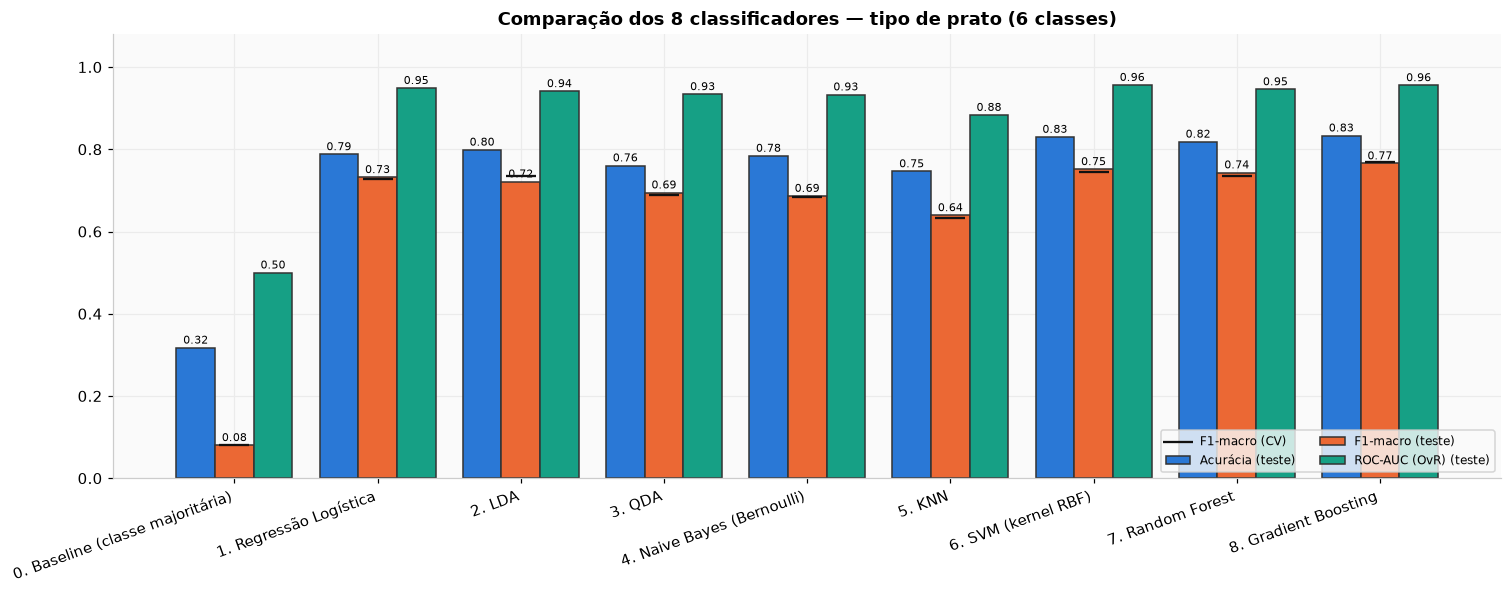

In [31]:
# 2.6 Tabela consolidada e gráfico comparativo
cols_tipo = ["Modelo", "Melhores hiperparâmetros", "F1-macro CV", "dp CV", "Acurácia CV", "Acurácia",
             "Acurácia Balanceada", "F1-macro", "F1 ponderado", "ROC-AUC (OvR)", "Tempo (s)"]
df_res_tipo = pd.DataFrame([{k: r[k] for k in cols_tipo} for r in resultados_tipo])
reais_t = df_res_tipo[~df_res_tipo["Modelo"].str.startswith("0.")]
melhor_tipo = resultados_tipo[reais_t["F1-macro CV"].idxmax()]
print(f"Modelo escolhido (maior F1-macro em CV): {melhor_tipo['Modelo']}")

metr_t = ["F1-macro CV", "Acurácia CV", "Acurácia", "Acurácia Balanceada", "F1-macro", "F1 ponderado", "ROC-AUC (OvR)"]
display(df_res_tipo.style.format({**{m: "{:.3f}" for m in metr_t}, "dp CV": "{:.3f}", "Tempo (s)": "{:.0f}"})
        .highlight_max(subset=metr_t, color="#c6e2ff").hide(axis="index"))

fig, ax = plt.subplots(figsize=(14, 5.5))
x_idx = np.arange(len(df_res_tipo))
w = 0.27
for j, (col, cor) in enumerate([("Acurácia", "#2a78d6"), ("F1-macro", "#eb6834"), ("ROC-AUC (OvR)", "#16a085")]):
    barras = ax.bar(x_idx + (j - 1) * w, df_res_tipo[col], w, label=f"{col} (teste)", color=cor, edgecolor="#333333")
    for b in barras:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01, f"{b.get_height():.2f}", ha="center", fontsize=7)
ax.scatter(x_idx, df_res_tipo["F1-macro CV"], color="#111111", marker="_", s=400, zorder=4, label="F1-macro (CV)")
ax.set_xticks(x_idx)
ax.set_xticklabels(df_res_tipo["Modelo"], rotation=20, ha="right")
ax.set_ylim(0, 1.08)
ax.set_title("Comparação dos 8 classificadores — tipo de prato (6 classes)")
ax.legend(loc="lower right", fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig("figuras/comparacao_classificadores.png", dpi=150, bbox_inches="tight")
plt.show()

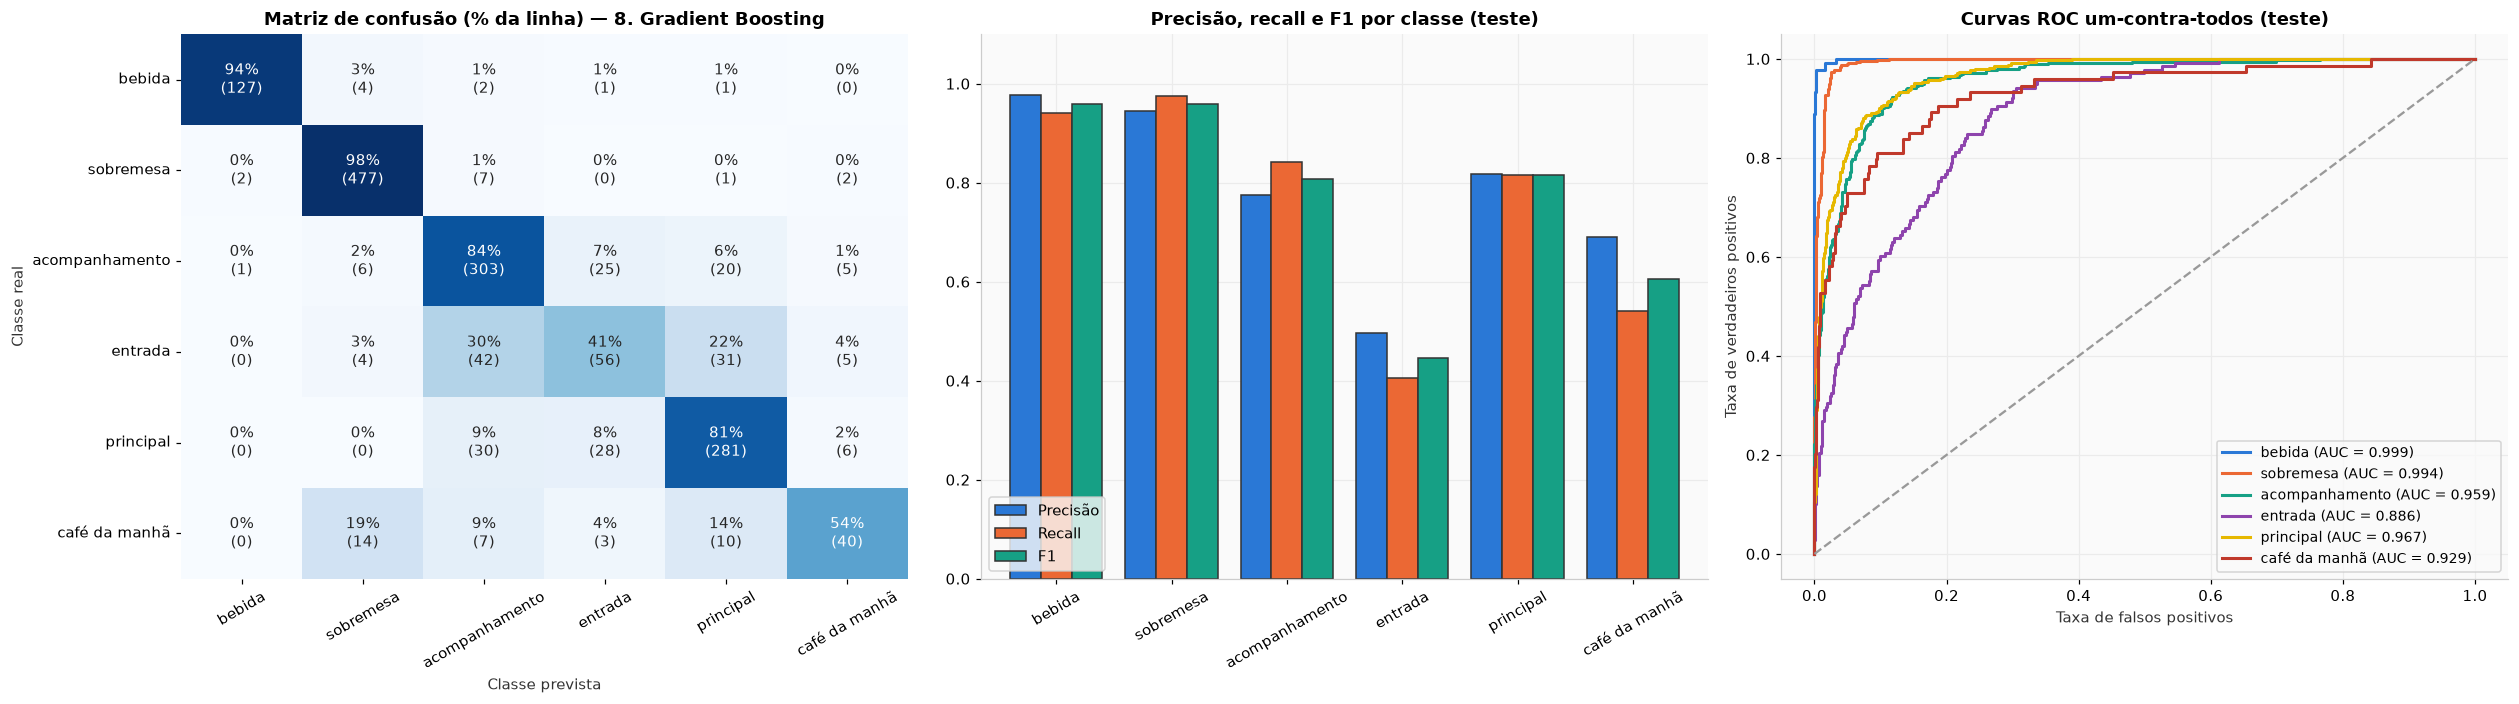

,Precisão,Recall,F1,Suporte
bebida,0.977,0.941,0.958,135
sobremesa,0.945,0.975,0.960,489
acompanhamento,0.775,0.842,0.807,360
entrada,0.496,0.406,0.446,138
principal,0.817,0.814,0.816,345
café da manhã,0.690,0.541,0.606,74


Confusões mais frequentes (real → previsto):
  entrada         → acompanhamento : 42 receitas
  entrada         → principal      : 31 receitas
  principal       → acompanhamento : 30 receitas
  principal       → entrada        : 28 receitas


In [32]:
# 2.6 Modelo escolhido: matriz de confusão, métricas por classe e curvas ROC um-contra-todos
classes_m = list(melhor_tipo["modelo"].classes_)
cm_t = confusion_matrix(y_te_t, melhor_tipo["y_hat"], labels=ORDEM_CLASSES)
cm_norm = cm_t / cm_t.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 3, figsize=(23, 6.5))
anot = np.array([[f"{cm_norm[i, j]:.0%}\n({cm_t[i, j]})" for j in range(6)] for i in range(6)])
sns.heatmap(cm_norm, annot=anot, fmt="", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=ORDEM_CLASSES, yticklabels=ORDEM_CLASSES)
axes[0].set_xlabel("Classe prevista")
axes[0].set_ylabel("Classe real")
axes[0].set_title(f"Matriz de confusão (% da linha) — {melhor_tipo['Modelo']}")
axes[0].tick_params(axis="x", rotation=30)

rel = pd.DataFrame({
    "Precisão": precision_score(y_te_t, melhor_tipo["y_hat"], labels=ORDEM_CLASSES, average=None),
    "Recall": recall_score(y_te_t, melhor_tipo["y_hat"], labels=ORDEM_CLASSES, average=None),
    "F1": f1_score(y_te_t, melhor_tipo["y_hat"], labels=ORDEM_CLASSES, average=None),
    "Suporte": y_te_t.value_counts().reindex(ORDEM_CLASSES).values,
}, index=ORDEM_CLASSES)
rel[["Precisão", "Recall", "F1"]].plot.bar(ax=axes[1], color=["#2a78d6", "#eb6834", "#16a085"], edgecolor="#333333", width=0.8)
axes[1].set_ylim(0, 1.1)
axes[1].set_title("Precisão, recall e F1 por classe (teste)")
axes[1].tick_params(axis="x", rotation=30)
axes[1].legend(loc="lower left")

for j, c in enumerate(ORDEM_CLASSES):
    alvo_c = (y_te_t == c).astype(int)
    sc_c = melhor_tipo["proba"][:, classes_m.index(c)]
    fpr, tpr, _ = roc_curve(alvo_c, sc_c)
    axes[2].plot(fpr, tpr, color=PALETA[j], linewidth=2, label=f"{c} (AUC = {roc_auc_score(alvo_c, sc_c):.3f})")
axes[2].plot([0, 1], [0, 1], color="#999999", linestyle="--")
axes[2].set_xlabel("Taxa de falsos positivos")
axes[2].set_ylabel("Taxa de verdadeiros positivos")
axes[2].set_title("Curvas ROC um-contra-todos (teste)")
axes[2].legend(fontsize=9, loc="lower right")
plt.tight_layout()
plt.savefig("figuras/matriz_confusao.png", dpi=150, bbox_inches="tight")
plt.show()
display(rel.style.format({"Precisão": "{:.3f}", "Recall": "{:.3f}", "F1": "{:.3f}"}))

pares_confusos = (pd.DataFrame(cm_t, index=ORDEM_CLASSES, columns=ORDEM_CLASSES).stack()
                  .loc[lambda s: s.index.get_level_values(0) != s.index.get_level_values(1)]
                  .sort_values(ascending=False).head(4))
print("Confusões mais frequentes (real → previsto):")
for (real, prev), n in pares_confusos.items():
    print(f"  {real:15s} → {prev:15s}: {n} receitas")

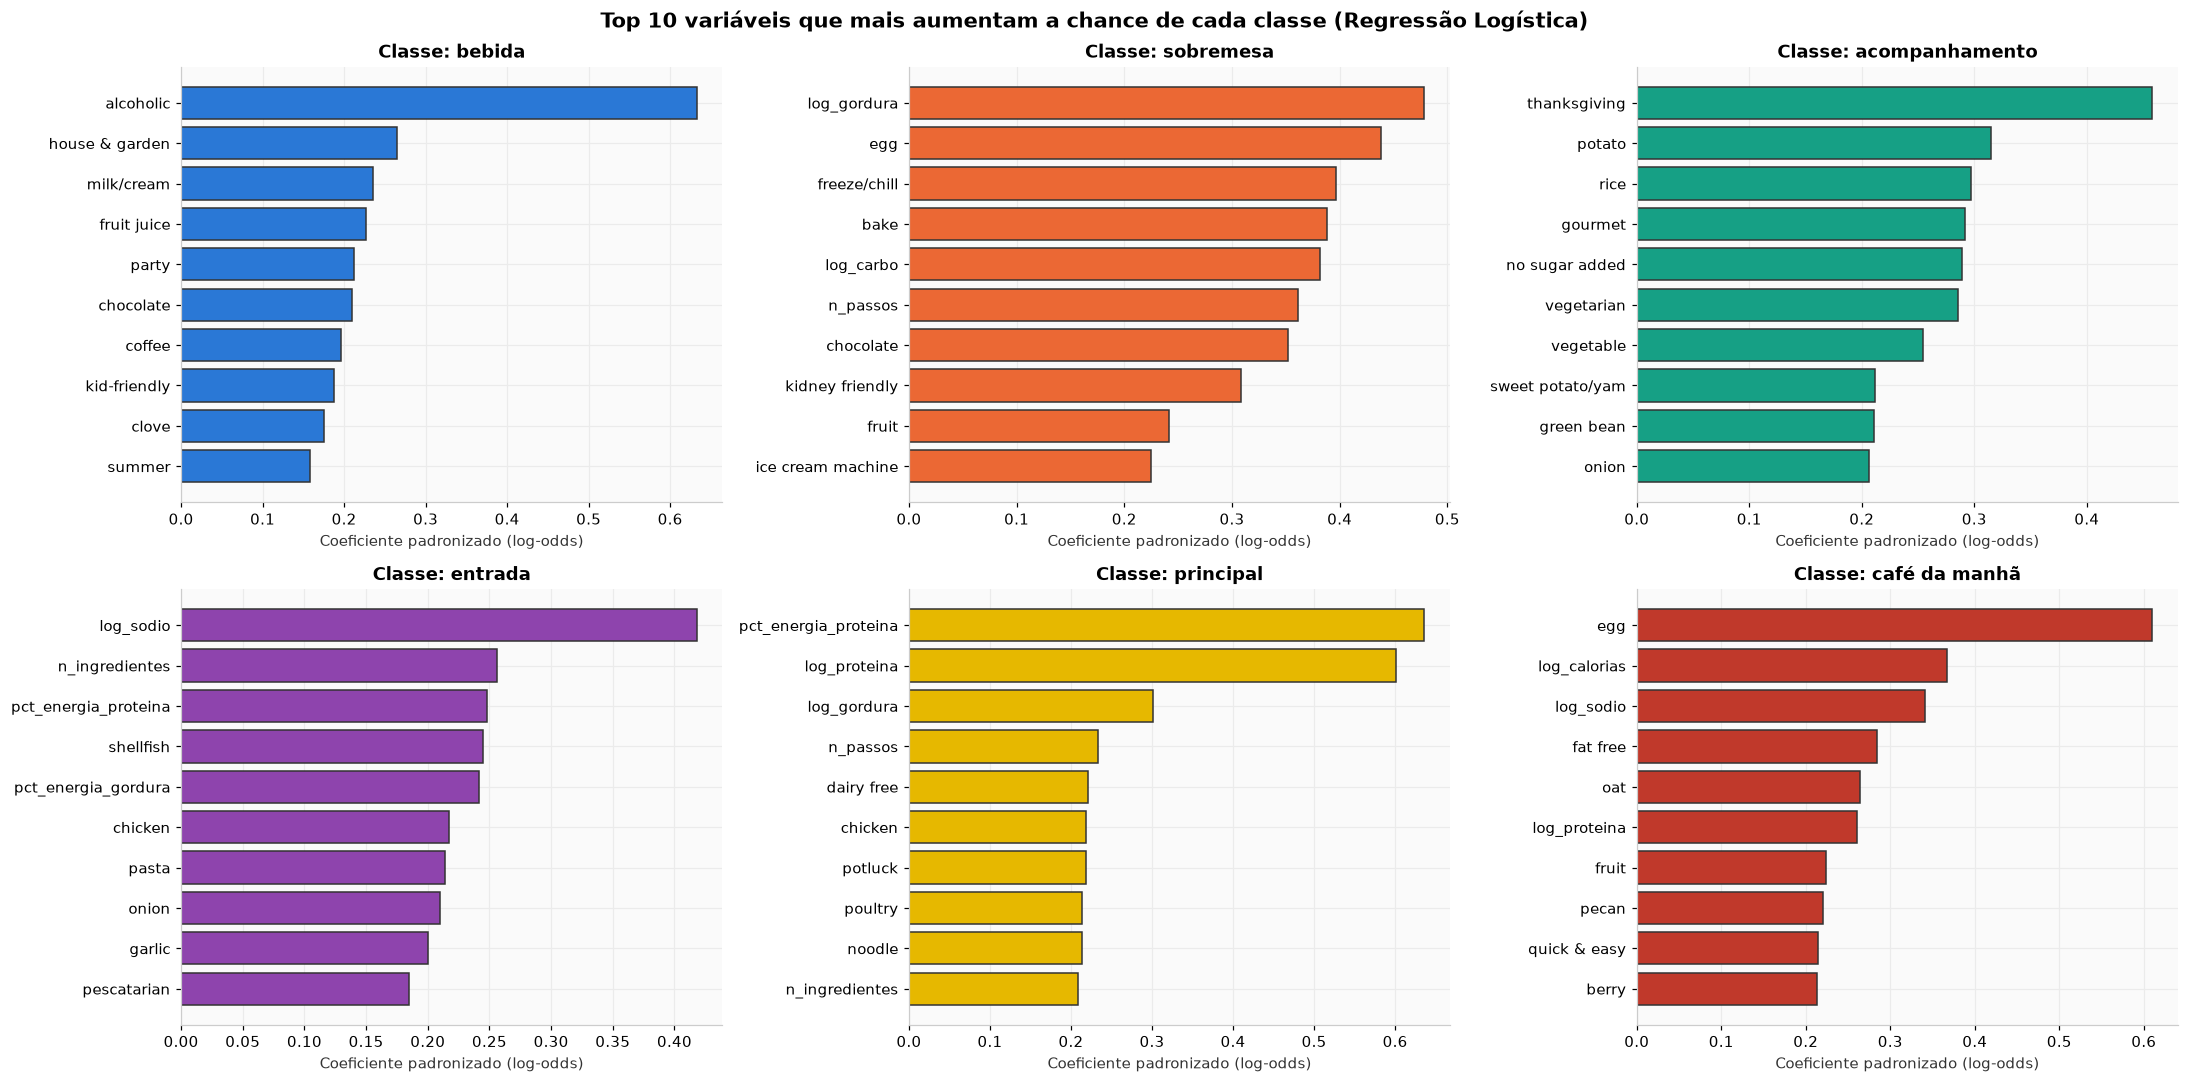

Coeficientes das variáveis numéricas (padronizadas) por classe:


,log_calorias,log_gordura,log_proteina,log_sodio,log_carbo,pct_energia_gordura,pct_energia_proteina,n_ingredientes,n_passos
bebida,-0.07,-0.41,-0.24,-0.32,0.16,-0.45,-0.13,-0.29,-0.23
sobremesa,0.03,0.48,-0.45,-0.55,0.38,0.04,-0.70,0.09,0.36
acompanhamento,-0.21,-0.05,-0.18,0.16,0.14,0.07,-0.17,-0.31,-0.36
entrada,-0.31,-0.03,-0.00,0.42,-0.34,0.24,0.25,0.26,0.01
principal,0.19,0.30,0.60,-0.06,-0.18,0.18,0.64,0.21,0.23
café da manhã,0.37,-0.30,0.26,0.34,-0.17,-0.08,0.12,0.04,-0.01


In [33]:
# 2.6 Interpretabilidade: variáveis que mais aumentam a chance de cada classe (Regressão Logística)
logit_tipo = next(r for r in resultados_tipo if r["Modelo"].startswith("1."))["modelo"]
coefs_t = logit_tipo.named_steps["clf"].coef_
classes_l = list(logit_tipo.named_steps["clf"].classes_)
nomes_feat_t = np.array(FEAT_SEL_T)

fig, axes = plt.subplots(2, 3, figsize=(20, 10))
for ax, c in zip(axes.ravel(), ORDEM_CLASSES):
    w_c = coefs_t[classes_l.index(c)]
    top = np.argsort(-w_c)[:10][::-1]
    ax.barh(nomes_feat_t[top], w_c[top], color=PALETA[ORDEM_CLASSES.index(c)], edgecolor="#333333")
    ax.set_title(f"Classe: {c}")
    ax.set_xlabel("Coeficiente padronizado (log-odds)")
plt.suptitle("Top 10 variáveis que mais aumentam a chance de cada classe (Regressão Logística)",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("figuras/importancia_classificacao.png", dpi=150, bbox_inches="tight")
plt.show()

if num_sel_t:
    idx_num = [FEAT_SEL_T.index(c) for c in num_sel_t]
    coef_num_t = pd.DataFrame(coefs_t[:, idx_num], index=classes_l, columns=num_sel_t).reindex(ORDEM_CLASSES)
    print("Coeficientes das variáveis numéricas (padronizadas) por classe:")
    display(coef_num_t.style.format("{:.2f}").background_gradient(cmap="RdBu_r", axis=None, vmin=-1.5, vmax=1.5))

#### Classificação com rejeição: quando automatizar?

Em produção não é preciso categorizar **todas** as receitas automaticamente: aquelas em que o modelo está pouco confiante podem ir para **revisão humana**. A probabilidade máxima prevista serve como medida de confiança. O limiar é escolhido nas predições *out-of-fold* do **treino** para garantir **≥ 95% de acerto** nas receitas automatizadas e, depois, verificado no teste.

Limiar de confiança escolhido no treino (OOF) para ≥ 95% de acerto: τ = 0.96
No TESTE: 64.1% das receitas são categorizadas automaticamente, com acurácia de 94.9%; as 35.9% restantes vão para revisão humana (nelas o modelo acertaria só 62.6%).


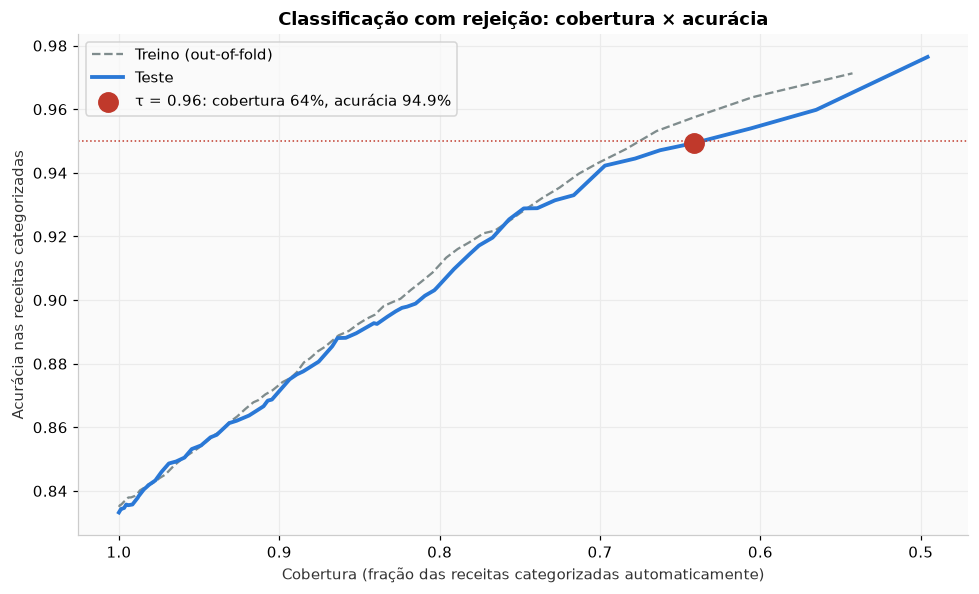

In [34]:
# 2.6 Cobertura × acurácia (classificação com rejeição)
oof_proba = cross_val_predict(melhor_tipo["modelo"], X_tr_t[FEAT_SEL_T], y_tr_t, cv=skf_tipo,
                              method="predict_proba", n_jobs=-1)
classes_b = melhor_tipo["modelo"].classes_
conf_oof = oof_proba.max(axis=1)
acerto_oof = classes_b[oof_proba.argmax(axis=1)] == y_tr_t.to_numpy()

limiares = np.linspace(0, 0.99, 100)


def curva_rejeicao(conf, acerto):
    cob = np.array([(conf >= t).mean() for t in limiares])
    acc = np.array([acerto[conf >= t].mean() if (conf >= t).any() else np.nan for t in limiares])
    return cob, acc


cob_oof, acc_oof = curva_rejeicao(conf_oof, acerto_oof)
META_ACC = 0.95
TAU = float(limiares[np.argmax(acc_oof >= META_ACC)]) if (acc_oof >= META_ACC).any() else 0.99

conf_te = melhor_tipo["proba"].max(axis=1)
acerto_te = melhor_tipo["y_hat"] == y_te_t.to_numpy()
cob_te, acc_te = curva_rejeicao(conf_te, acerto_te)
aceitas = conf_te >= TAU
print(f"Limiar de confiança escolhido no treino (OOF) para ≥ {META_ACC:.0%} de acerto: τ = {TAU:.2f}")
print(f"No TESTE: {aceitas.mean():.1%} das receitas são categorizadas automaticamente, com acurácia de "
      f"{acerto_te[aceitas].mean():.1%}; as {(~aceitas).mean():.1%} restantes vão para revisão humana "
      f"(nelas o modelo acertaria só {acerto_te[~aceitas].mean():.1%}).")

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(cob_oof, acc_oof, color="#7f8c8d", linestyle="--", label="Treino (out-of-fold)")
ax.plot(cob_te, acc_te, color="#2a78d6", linewidth=2.5, label="Teste")
ax.scatter([aceitas.mean()], [acerto_te[aceitas].mean()], s=160, color="#c0392b", zorder=5,
           label=f"τ = {TAU:.2f}: cobertura {aceitas.mean():.0%}, acurácia {acerto_te[aceitas].mean():.1%}")
ax.axhline(META_ACC, color="#c0392b", linestyle=":", linewidth=1)
ax.set_xlabel("Cobertura (fração das receitas categorizadas automaticamente)")
ax.set_ylabel("Acurácia nas receitas categorizadas")
ax.set_title("Classificação com rejeição: cobertura × acurácia")
ax.invert_xaxis()
ax.legend()
plt.tight_layout()
plt.savefig("figuras/rejeicao_cobertura.png", dpi=150, bbox_inches="tight")
plt.show()

In [35]:
# 2.6 Validação complementar (receitas ambíguas) e aplicação às receitas sem categoria
modelo_final_tipo = melhor_tipo["modelo"]

ambiguas = dados_tipo[dados_tipo["grupo"] == "ambígua"]
prev_amb = modelo_final_tipo.predict(ambiguas[FEAT_SEL_T])
acerto_amb = np.array([pertence.loc[i, p] == 1 for i, p in zip(ambiguas.index, prev_amb)])
print(f"Receitas com 2+ categorias: {len(ambiguas):,} — a classe prevista é uma das categorias da receita em "
      f"{acerto_amb.mean():.1%} dos casos")

sem_cat = dados_tipo[dados_tipo["grupo"] == "sem categoria"]
proba_sc = modelo_final_tipo.predict_proba(sem_cat[FEAT_SEL_T])
prev_sc = modelo_final_tipo.classes_[proba_sc.argmax(axis=1)]
conf_sc = proba_sc.max(axis=1)

# Mudança de distribuição: as receitas sem categoria são comparáveis às rotuladas?
eh_molho = sem_cat[[t for t in ["sauce", "condiment/spread", "condiment", "salad dressing"] if t in sem_cat]].max(axis=1) == 1
comparacao_dist = pd.DataFrame({
    "Teste (rotuladas)": [X_te_t[TAGS_PERMITIDAS].sum(axis=1).mean(), conf_te.mean(), (conf_te >= TAU).mean()],
    "Sem categoria": [sem_cat[TAGS_PERMITIDAS].sum(axis=1).mean(), conf_sc.mean(), (conf_sc >= TAU).mean()],
    "Sem categoria — molhos/condimentos": [sem_cat.loc[eh_molho, TAGS_PERMITIDAS].sum(axis=1).mean(),
                                           conf_sc[eh_molho.to_numpy()].mean(), (conf_sc[eh_molho.to_numpy()] >= TAU).mean()],
}, index=["Nº médio de tags (informação disponível)", "Confiança média do modelo", f"Fração com confiança ≥ τ"])
display(comparacao_dist.style.format("{:.2f}"))

resumo_sc = pd.DataFrame({"Prevista (todas)": pd.Series(prev_sc).value_counts(),
                          f"Prevista com confiança ≥ {TAU:.2f}": pd.Series(prev_sc[conf_sc >= TAU]).value_counts()}
                         ).reindex(ORDEM_CLASSES).fillna(0).astype(int)
print(f"Receitas sem categoria: {len(sem_cat):,} — {(conf_sc >= TAU).mean():.1%} podem ser categorizadas "
      f"automaticamente (confiança ≥ {TAU:.2f}); as demais iriam para revisão humana")
display(resumo_sc)

ordem_map = {c: i for i, c in enumerate(ORDEM_CLASSES)}
exemplos_sc = (sem_cat.assign(prevista=prev_sc, confianca=conf_sc, ordem=[ordem_map[p] for p in prev_sc])
               .sort_values("confianca", ascending=False).groupby("prevista").head(2)
               .sort_values(["ordem", "confianca"], ascending=[True, False])
               [["prevista", "title", "confianca"]].reset_index(drop=True))
exemplos_sc["title"] = exemplos_sc["title"].str.strip()
print("Exemplos de receitas sem categoria e a categoria atribuída com maior confiança:")
display(exemplos_sc.style.format({"confianca": "{:.1%}"}).hide(axis="index"))

Receitas com 2+ categorias: 888 — a classe prevista é uma das categorias da receita em 80.9% dos casos


,Teste (rotuladas),Sem categoria,Sem categoria — molhos/condimentos
Nº médio de tags (informação disponível),12.40,7.64,6.86
Confiança média do modelo,0.91,0.83,0.76
Fração com confiança ≥ τ,0.64,0.37,0.17


Receitas sem categoria: 5,504 — 36.8% podem ser categorizadas automaticamente (confiança ≥ 0.96); as demais iriam para revisão humana


,Prevista (todas),Prevista com confiança ≥ 0.96
bebida,110,63
sobremesa,371,159
acompanhamento,1066,188
entrada,986,79
principal,2782,1507
café da manhã,189,32


Exemplos de receitas sem categoria e a categoria atribuída com maior confiança:


prevista,title,confianca
bebida,Rhubarb-Fennel Gin Cocktail,100.0%
bebida,Blood Orange Jell-O Shots,100.0%
sobremesa,Spiced Chocolate Torte Wrapped in Chocolate Ribbons,100.0%
sobremesa,Raspberry Sorbet,100.0%
acompanhamento,"Green Beans with Crisp Shallots, Chile, and Mint",100.0%
acompanhamento,Winter Vegetables with Horseradish Dill Butter,99.9%
entrada,Stilton Walnut Tarts,100.0%
entrada,Mustard-Seed Cheddar Sticks,100.0%
principal,"Fish in Foil with Sweet Onions, Tomatoes, and Mojo Verde",100.0%
principal,Coffee-Marinated Skirt Steak,100.0%


**Discussão dos resultados de classificação:**
1. **Todos os modelos superam a linha de base** (classe majoritária: acurácia 0,317, F1-macro 0,08).
2. **Modelo escolhido: Gradient Boosting**, com o maior F1-macro em CV (0,769) e o **menor desvio entre folds** (± 0,005). No teste: **F1-macro = 0,766, acurácia = 0,833, acurácia balanceada = 0,753, ROC-AUC = 0,956**. CV ≈ teste: sem sinal de sobreajuste.
3. **Comparação entre famílias:** SVM (0,751), Random Forest (0,744), Regressão Logística (0,732) e LDA (0,722) ficam próximos — a fronteira entre as classes é em boa parte linear. QDA (0,695) e Naive Bayes (0,686) pagam por suas hipóteses (normalidade com covariância por classe; independência entre tags). O **KNN é o pior** (0,639): com 175 dimensões majoritariamente binárias, as distâncias perdem poder discriminativo (maldição da dimensionalidade).
4. **Desempenho por classe:** **bebida (F1 = 0,96)** e **sobremesa (0,96)** são quase perfeitamente separáveis — composição energética própria (carboidrato, pouca proteína) e ingredientes característicos. **Acompanhamento (0,81)** e **principal (0,82)** são bons; **café da manhã (0,61)** sofre com poucos exemplos (5%); **entrada (0,45)** é a classe difícil: é confundida com acompanhamento (42 receitas) e principal (31). Não é falha do modelo, é **ambiguidade do rótulo** — a mesma receita pode ser entrada ou acompanhamento conforme a porção e o momento da refeição (das 888 receitas com 2+ categorias, 141 são "entrada + principal" e 98 "acompanhamento + entrada").
5. **Interpretação (Regressão Logística):** a chance de "principal" cresce com a fração de energia vinda da proteína (+0,64) e com a quantidade de proteína (+0,60); "sobremesa" cresce com gordura e carboidrato e cai com proteína e sódio; "entrada" cresce com sódio (+0,42); "bebida" é marcada por baixa fração de energia da gordura (−0,45) e por menos ingredientes e passos.
6. **Classificação com rejeição:** com confiança ≥ 0,96 (limiar escolhido no treino), **64,1% das receitas de teste são categorizadas automaticamente com 94,9% de acerto**; as 35,9% restantes — onde o modelo acertaria só 62,6% — vão para revisão humana.
7. **Validação complementar:** nas 888 receitas ambíguas, a classe prevista é uma das categorias da receita em **80,9%** dos casos.
8. **Aplicação e mudança de distribuição:** as 5.504 receitas sem categoria têm **menos tags** (7,6 contra 12,4 no teste) e, portanto, menos informação: a confiança média cai de 0,91 para 0,83 e só **36,8%** passam no limiar. Os molhos e condimentos — que não cabem em nenhuma das 6 classes — passam só em 17% dos casos: a rejeição funciona como **mecanismo de segurança**. A maioria das previsões é "principal", coerente com o perfil dessas receitas (mais carne, frango e peixe). Em produção, o desempenho real nesse grupo deve ser um pouco inferior ao medido no teste.

## Bloco 3 — Análise Não Supervisionada: Segmentação Nutricional das Receitas

Objetivo: descobrir **perfis nutricionais** de receitas (sem usar nenhum alvo) e usá-los em um sistema de substituição de receitas. Etapas:
1. **Seleção de atributos para agrupamento** — critérios explícitos e comparação quantitativa de espaços de atributos (estatística de Hopkins, silhouette, Davies–Bouldin).
2. **PCA** — variância explicada, critério de Kaiser, *loadings*, *biplot*.
3. **K-Means** — escolha de *k* por cotovelo, silhouette, Davies–Bouldin, Calinski–Harabasz e estabilidade por *bootstrap*.
4. **Clustering hierárquico** — escolha do *linkage* por correlação cofenética e dendrograma com linha de corte.
5. **GMM** — seleção por BIC (nº de componentes × tipo de covariância) e atribuição suave.
6. **DBSCAN** — escolha de `eps` pelo gráfico de *k*-distâncias; detecção de receitas atípicas.
7. **Comparação dos métodos, perfis dos grupos e aplicação** (`sugerir_substitutos`).

### 3.1 Seleção de Atributos para o Agrupamento

**Por que não reutilizar `TOP30_FEATURES`?** Essa lista foi escolhida pelo Lasso para **prever calorias** — é uma seleção *supervisionada*, otimizada para outra tarefa. Além disso, 27 das 30 variáveis são binárias: distâncias euclidianas entre vetores 0/1 padronizados são dominadas pelas tags raras, e a versão anterior precisava de 24 de 30 componentes para reter 90% da variância (PC1 com só 10%), sinal de ausência de estrutura.

**Variáveis candidatas (definidas pelo domínio nutricional):** 9 atributos derivados de `calories`, `fat`, `protein` e `sodium` — quantidades absolutas (em log) e **composição energética** (fração das calorias vinda de gordura, proteína e carboidrato estimado) e densidade de sódio.

**Critérios de seleção aplicados em sequência:**
1. **Assimetria:** variáveis de quantidade têm cauda longa → transformação `log1p` (reduz a influência de receitas extremas nas distâncias).
2. **Escala × composição:** as quantidades absolutas são fortemente correlacionadas entre si e medem essencialmente o **tamanho da porção**; mantemos uma única variável de escala (`log_calorias`) e privilegiamos variáveis de composição, que descrevem o *tipo* de receita.
3. **Redundância:** remover variáveis com \|r\| > 0,85 ou que sejam combinação linear exata de outras (`pct_energia_carbo = 1 − gordura − proteína`).
4. **Validação quantitativa:** comparar o espaço final com alternativas por **estatística de Hopkins** (tendência de agrupamento; 0,5 = aleatório, → 1 = agrupável), **silhouette** e **Davies–Bouldin**.

Receitas com perfil nutricional completo: 14,091 de 14,096


,Assimetria (bruta),Assimetria (log1p)
calories,2.16,-0.80
fat,2.42,-0.76
protein,2.33,0.01
carbo_estimado_g,4.05,-0.67
sodium,2.80,-0.82
sodio_por_100kcal,55.09,-0.45


PC1 das 5 quantidades absolutas explica 62.7% da variância (fator 'tamanho da porção', loadings = [0.51, 0.49, 0.51, 0.24, 0.43])
pct_gordura + pct_proteína + pct_carbo = 1 em 100.0% das receitas → pct_energia_carbo é combinação linear exata e é removida


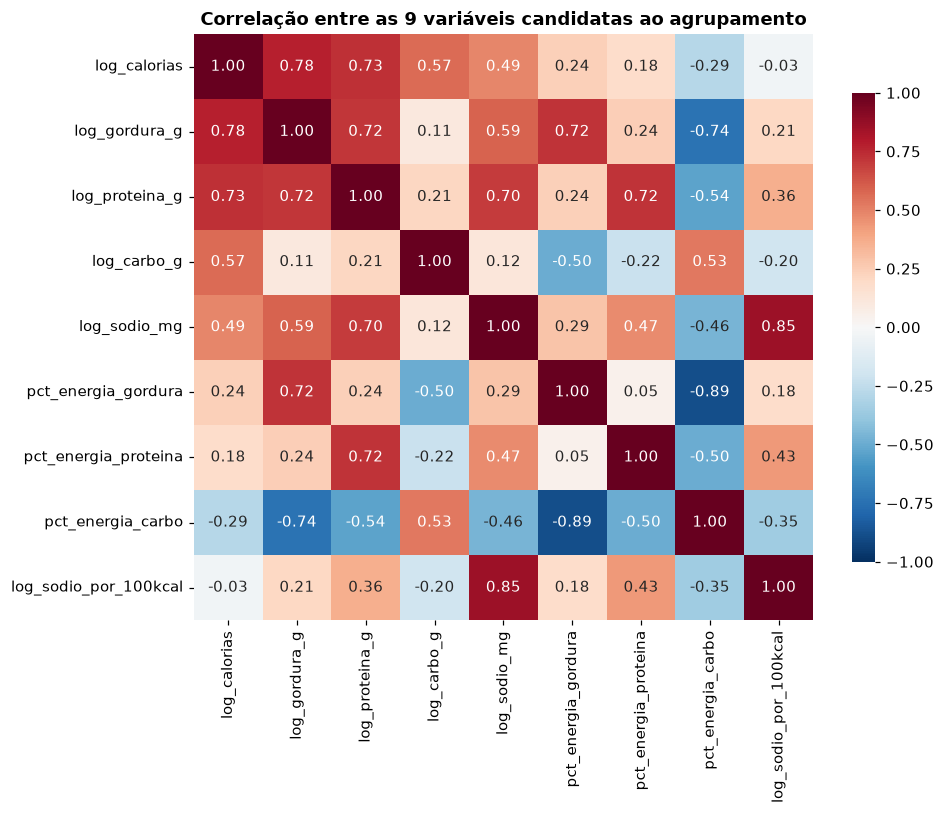

Pares com |r| > 0,85: {'log_sodio_mg ~ log_sodio_por_100kcal': 0.85, 'pct_energia_gordura ~ pct_energia_carbo': 0.89}


In [36]:
# 3.1 Construção das variáveis candidatas e diagnóstico de assimetria
dados_unsup = dados.copy()
nutr_u = atributos_nutricionais(dados_unsup)

candidatas_unsup = pd.DataFrame({
    "log_calorias": np.log1p(dados_unsup["calories"]),
    "log_gordura_g": np.log1p(dados_unsup["fat"]),
    "log_proteina_g": np.log1p(dados_unsup["protein"]),
    "log_carbo_g": np.log1p(nutr_u["carbo_estimado_g"]),
    "log_sodio_mg": np.log1p(dados_unsup["sodium"]),
    "pct_energia_gordura": nutr_u["pct_energia_gordura"],
    "pct_energia_proteina": nutr_u["pct_energia_proteina"],
    "pct_energia_carbo": nutr_u["pct_energia_carbo"],
    "log_sodio_por_100kcal": np.log1p(nutr_u["sodio_por_100kcal"]),
}, index=dados_unsup.index)
validas = candidatas_unsup.notna().all(axis=1)
print(f"Receitas com perfil nutricional completo: {validas.sum():,} de {len(dados_unsup):,}")
dados_unsup = dados_unsup[validas].copy()
candidatas_unsup = candidatas_unsup[validas]

# Critério 1 — assimetria antes e depois do log
brutas = pd.DataFrame({"calories": dados_unsup["calories"], "fat": dados_unsup["fat"],
                       "protein": dados_unsup["protein"], "carbo_estimado_g": nutr_u.loc[validas, "carbo_estimado_g"],
                       "sodium": dados_unsup["sodium"], "sodio_por_100kcal": nutr_u.loc[validas, "sodio_por_100kcal"]})
assimetria = pd.DataFrame({
    "Assimetria (bruta)": brutas.skew().values,
    "Assimetria (log1p)": candidatas_unsup[["log_calorias", "log_gordura_g", "log_proteina_g", "log_carbo_g",
                                            "log_sodio_mg", "log_sodio_por_100kcal"]].skew().values,
}, index=brutas.columns)
display(assimetria.style.format("{:.2f}"))

# Critério 2 — o bloco de quantidades absolutas é dominado por um fator de "tamanho"
bloco_qtd = ["log_calorias", "log_gordura_g", "log_proteina_g", "log_carbo_g", "log_sodio_mg"]
pca_qtd = PCA().fit(StandardScaler().fit_transform(candidatas_unsup[bloco_qtd]))
print(f"PC1 das 5 quantidades absolutas explica {pca_qtd.explained_variance_ratio_[0]:.1%} da variância "
      f"(fator 'tamanho da porção', loadings = {np.round(pca_qtd.components_[0], 2).tolist()})")

# Critério 3 — redundância/combinação linear no bloco de composição
soma_pct = candidatas_unsup[["pct_energia_gordura", "pct_energia_proteina", "pct_energia_carbo"]].sum(axis=1)
print(f"pct_gordura + pct_proteína + pct_carbo = 1 em {np.isclose(soma_pct, 1).mean():.1%} das receitas "
      f"→ pct_energia_carbo é combinação linear exata e é removida")

corr_unsup = candidatas_unsup.corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr_unsup, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Correlação entre as 9 variáveis candidatas ao agrupamento")
plt.tight_layout()
plt.savefig("figuras/correlacao_candidatas_cluster.png", dpi=150, bbox_inches="tight")
plt.show()

pares_u = corr_unsup.abs().where(np.triu(np.ones(corr_unsup.shape, dtype=bool), k=1)).stack()
print("Pares com |r| > 0,85:", {f"{a} ~ {b}": round(v, 2) for (a, b), v in pares_u[pares_u > 0.85].items()})

In [37]:
# 3.1 Validação quantitativa dos espaços de atributos
FEAT_CLUSTER = ["log_calorias", "pct_energia_gordura", "pct_energia_proteina", "log_sodio_por_100kcal"]


def estatistica_hopkins(X, m=500, seed=SEED):
    """H ≈ 0,5: dados uniformes (sem estrutura); H → 1: forte tendência de agrupamento."""
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(X), size=m, replace=False)
    nn = NearestNeighbors(n_neighbors=2).fit(X)
    uniformes = rng.uniform(X.min(axis=0), X.max(axis=0), size=(m, X.shape[1]))
    u = nn.kneighbors(uniformes, n_neighbors=1)[0].ravel()
    w = nn.kneighbors(X[idx], n_neighbors=2)[0][:, 1]
    return u.sum() / (u.sum() + w.sum())


espacos = {
    "TOP30_FEATURES (versão anterior)": dados_unsup[TOP30_FEATURES],
    "5 quantidades absolutas (log)": candidatas_unsup[bloco_qtd],
    "9 candidatas": candidatas_unsup,
    "4 selecionadas (composição + escala)": candidatas_unsup[FEAT_CLUSTER],
}
linhas_esp = []
for nome_e, M in espacos.items():
    Xe = StandardScaler().fit_transform(M)
    lab = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit_predict(Xe)
    pca_e = PCA().fit(Xe)
    linhas_esp.append({
        "Espaço de atributos": nome_e,
        "Nº variáveis": Xe.shape[1],
        "Hopkins": estatistica_hopkins(Xe),
        "Silhouette (k=4)": silhouette_score(Xe, lab, sample_size=6000, random_state=SEED),
        "Davies–Bouldin (k=4)": davies_bouldin_score(Xe, lab),
        "Variância PC1+PC2": pca_e.explained_variance_ratio_[:2].sum(),
    })
tabela_espacos = pd.DataFrame(linhas_esp)
display(tabela_espacos.style.format({"Hopkins": "{:.3f}", "Silhouette (k=4)": "{:.3f}",
                                     "Davies–Bouldin (k=4)": "{:.2f}", "Variância PC1+PC2": "{:.1%}"})
        .hide(axis="index"))
print(f"Variáveis finais para o agrupamento: {FEAT_CLUSTER}")

Espaço de atributos,Nº variáveis,Hopkins,Silhouette (k=4),Davies–Bouldin (k=4),Variância PC1+PC2
TOP30_FEATURES (versão anterior),30,0.973,0.178,1.87,17.7%
5 quantidades absolutas (log),5,0.928,0.280,1.18,84.0%
9 candidatas,9,0.942,0.266,1.23,71.6%
4 selecionadas (composição + escala),4,0.910,0.253,1.24,66.8%


Variáveis finais para o agrupamento: ['log_calorias', 'pct_energia_gordura', 'pct_energia_proteina', 'log_sodio_por_100kcal']


**Interpretação da seleção de atributos:**
- **TOP30 (versão anterior):** Hopkins de 0,973 parece excelente, mas é um **artefato das variáveis binárias** — muitas receitas têm vetores de tags idênticos (distância 0 ao vizinho), o que infla a estatística. A silhouette (0,178) e a variância capturada por PC1+PC2 (17,7%) confirmam a ausência de estrutura útil.
- **Quantidades absolutas (log):** a maior silhouette (0,280), mas o PC1 explica 62,7% da variância com *loadings* todos positivos — é um eixo de **tamanho da porção**. Agrupar nesse espaço separaria receitas pequenas, médias e grandes, e não *tipos* de receita.
- **4 variáveis selecionadas** (`log_calorias`, `pct_energia_gordura`, `pct_energia_proteina`, `log_sodio_por_100kcal`): forte tendência de agrupamento (Hopkins = 0,91), silhouette de 0,253 (+42% sobre o TOP30), Davies–Bouldin de 1,24 (−34%), sem redundância nem combinações lineares, e **PC1+PC2 = 66,8%** (contra 17,7%). Aceitamos uma silhouette ligeiramente menor que a do espaço de quantidades em troca de grupos que descrevem a **composição** da receita.

### 3.2 Análise de Componentes Principais (PCA)

As 4 variáveis selecionadas são padronizadas (`StandardScaler`: média 0, desvio 1 — necessário porque PCA e K-Means usam distâncias euclidianas e as variáveis têm escalas diferentes). O número de componentes é avaliado por três critérios: **Kaiser** (autovalor > 1), **variância acumulada** (≥ 80%) e **cotovelo do scree plot**.

,Autovalor,Variância explicada,Variância acumulada,Kaiser (autovalor > 1)
PC1,1.549,38.7%,38.7%,sim
PC2,1.125,28.1%,66.8%,sim
PC3,0.860,21.5%,88.4%,não
PC4,0.466,11.6%,100.0%,não


Critério de Kaiser: 2 componentes | ≥ 80% da variância: 3 componentes


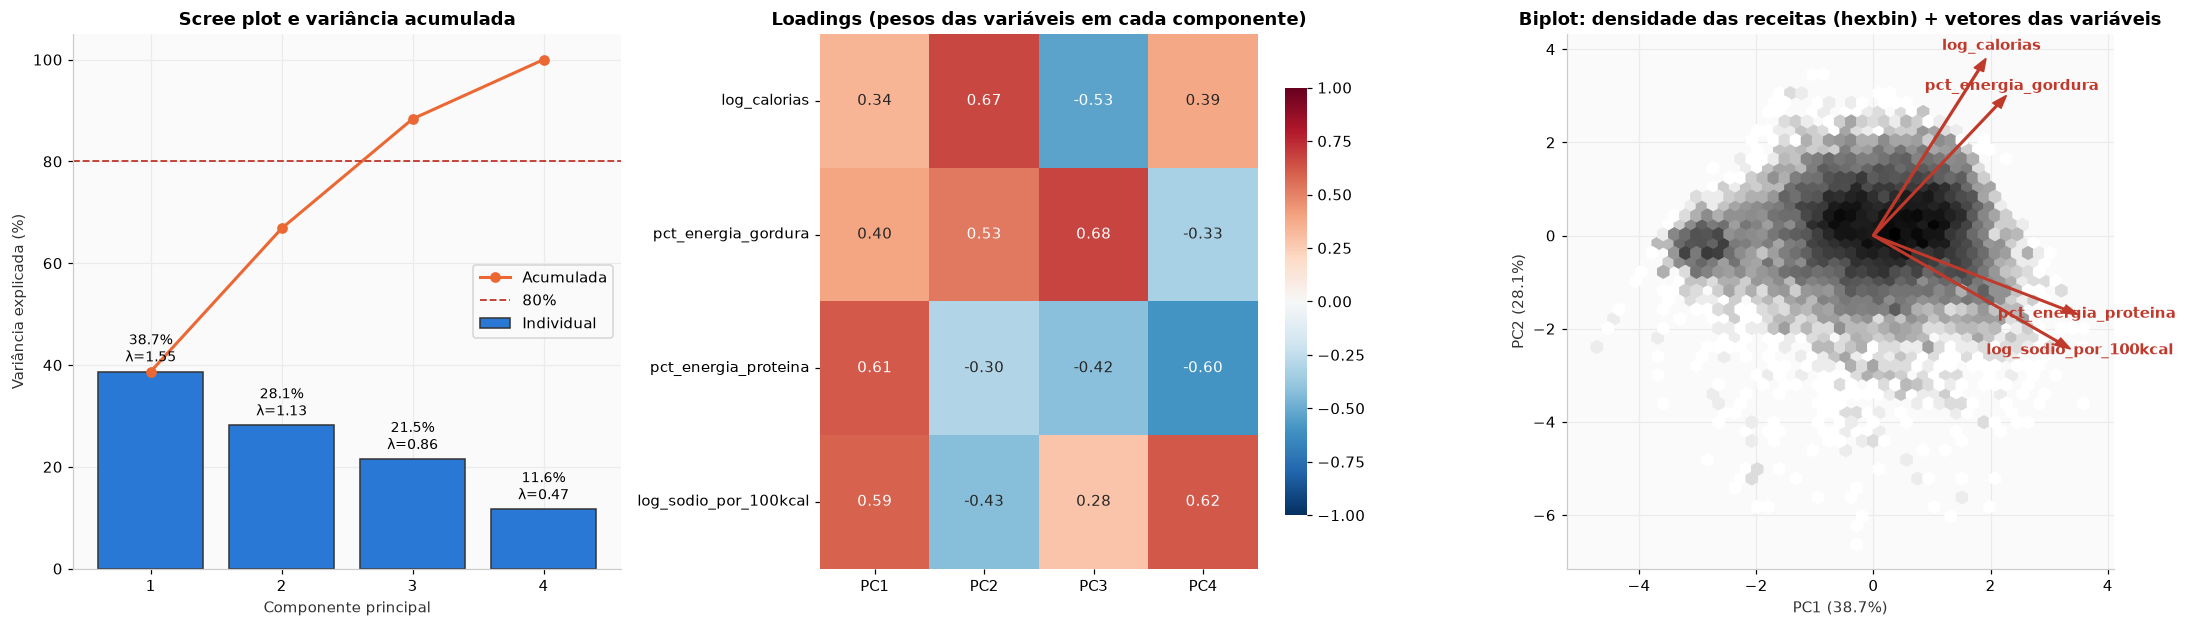

In [38]:
# 3.2 PCA nas variáveis selecionadas
escalador_cl = StandardScaler()
Z_cl = escalador_cl.fit_transform(candidatas_unsup[FEAT_CLUSTER])

pca = PCA(random_state=SEED).fit(Z_cl)
X_pca = pca.transform(Z_cl)
var_exp = pca.explained_variance_ratio_
var_cum = np.cumsum(var_exp)
autovalores = pca.explained_variance_
n_kaiser = int((autovalores > 1).sum())
n_80 = int(np.argmax(var_cum >= 0.80)) + 1

tabela_pca = pd.DataFrame({"Autovalor": autovalores, "Variância explicada": var_exp, "Variância acumulada": var_cum,
                           "Kaiser (autovalor > 1)": np.where(autovalores > 1, "sim", "não")},
                          index=[f"PC{i + 1}" for i in range(len(var_exp))])
display(tabela_pca.style.format({"Autovalor": "{:.3f}", "Variância explicada": "{:.1%}", "Variância acumulada": "{:.1%}"}))
loadings = pd.DataFrame(pca.components_.T, index=FEAT_CLUSTER, columns=[f"PC{i + 1}" for i in range(len(var_exp))])
print(f"Critério de Kaiser: {n_kaiser} componentes | ≥ 80% da variância: {n_80} componentes")

fig, axes = plt.subplots(1, 3, figsize=(20, 5.8))
pcs = np.arange(1, len(var_exp) + 1)
axes[0].bar(pcs, var_exp * 100, color="#2a78d6", edgecolor="#333333", label="Individual")
axes[0].plot(pcs, var_cum * 100, color="#eb6834", marker="o", linewidth=2, label="Acumulada")
axes[0].axhline(80, color="#c0392b", linestyle="--", linewidth=1.2, label="80%")
for i, (v, c) in enumerate(zip(var_exp, var_cum)):
    axes[0].text(i + 1, v * 100 + 2, f"{v:.1%}\nλ={autovalores[i]:.2f}", ha="center", fontsize=9)
axes[0].set_xticks(pcs)
axes[0].set_xlabel("Componente principal")
axes[0].set_ylabel("Variância explicada (%)")
axes[0].set_ylim(0, 105)
axes[0].set_title("Scree plot e variância acumulada")
axes[0].legend(loc="center right")

sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[1], cbar_kws={"shrink": 0.8})
axes[1].set_title("Loadings (pesos das variáveis em cada componente)")

rng_vis = np.random.default_rng(SEED)
amostra_vis = rng_vis.choice(len(X_pca), size=4000, replace=False)
axes[2].hexbin(X_pca[:, 0], X_pca[:, 1], gridsize=45, cmap="Greys", mincnt=1, bins="log")
escala_seta = np.abs(X_pca[:, :2]).max() * 0.8
for var, (lx, ly) in zip(FEAT_CLUSTER, pca.components_[:2].T):
    axes[2].arrow(0, 0, lx * escala_seta, ly * escala_seta, color="#c0392b", width=0.03, head_width=0.18)
    axes[2].text(lx * escala_seta * 1.12, ly * escala_seta * 1.12, var, color="#c0392b", fontsize=10,
                 fontweight="bold", ha="center")
axes[2].set_xlabel(f"PC1 ({var_exp[0]:.1%})")
axes[2].set_ylabel(f"PC2 ({var_exp[1]:.1%})")
axes[2].set_title("Biplot: densidade das receitas (hexbin) + vetores das variáveis")
plt.tight_layout()
plt.savefig("figuras/pca_visualizacao.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretação do PCA:**
- **Número de componentes:** o critério de Kaiser retém **2 componentes** (autovalores 1,55 e 1,13), que explicam **66,8%** da variância. Para ≥ 80% são necessários 3 (88,4%).
- **PC1 (38,7%) — eixo salgado/proteico × doce/carboidrato:** *loadings* positivos em `pct_energia_proteina` (0,61), `log_sodio_por_100kcal` (0,59) e `pct_energia_gordura` (0,40). À direita ficam carnes, peixes e pratos salgados; à esquerda, bebidas e preparos à base de açúcar/amido.
- **PC2 (28,1%) — eixo densidade energética:** `log_calorias` (0,67) e `pct_energia_gordura` (0,53) contra sódio (−0,43) e proteína (−0,30). No alto ficam sobremesas ricas e pratos fartos; embaixo, caldos e molhos magros.
- **PC3 (21,5%):** contrapõe gordura (0,68) e calorias (−0,53) — receitas gordurosas porém pouco calóricas (saladas com molho, entradas).
- **Uso:** o PCA serve aqui para **visualização e interpretação**. Os algoritmos de agrupamento usam as 4 variáveis padronizadas completas: o K-Means é invariante a rotações, então usar os 4 PCs daria o mesmo resultado, e usar só 2 descartaria 33% da informação. O *biplot* mostra uma nuvem contínua, sem "ilhas" separadas — um primeiro indício de que os grupos serão uma segmentação de um contínuo.

### 3.3 K-Means — Escolha do Número de Clusters

Avaliamos $k \in [2, 10]$ com cinco critérios complementares (todos calculados no espaço padronizado de 4 variáveis; o K-Means usa todas as dimensões, não apenas o plano PC1×PC2):

| Critério | O que mede | Melhor valor |
|---|---|---|
| Inércia (cotovelo) | soma das distâncias quadráticas aos centróides | ponto de inflexão (detectado automaticamente pela maior distância à corda) |
| Silhouette | coesão interna vs. separação do vizinho mais próximo (−1 a 1) | máximo |
| Davies–Bouldin | razão dispersão interna / distância entre centróides | mínimo |
| Calinski–Harabasz | razão variância entre / dentro dos grupos | máximo |
| Estabilidade (ARI *bootstrap*) | concordância das partições em 10 reamostragens | alto (≥ 0,8 = estável) |

**Regra de decisão:** cada um dos 4 primeiros critérios vota em um *k*; entre os *k* com partição estável (ARI ≥ 0,8), escolhe-se o mais votado.

,Inércia,Silhouette,Davies–Bouldin,Calinski–Harabasz,Estabilidade (ARI)
k,,,,,
2,"42,471",0.248,1.521,"4,609",0.903
3,"34,199",0.244,1.416,"4,565",0.836
4,"27,957",0.253,1.242,"4,771",0.935
5,"24,522",0.239,1.264,"4,573",0.777
6,"21,702",0.243,1.196,"4,499",0.914
7,"19,583",0.255,1.140,"4,409",0.927
8,"18,267",0.248,1.153,"4,196",0.818
9,"17,260",0.230,1.238,"3,988",0.681
10,"16,230",0.236,1.232,"3,869",0.732


Votos por critério: {'Cotovelo': 5, 'Silhouette': 7, 'Davies–Bouldin': 7, 'Calinski–Harabasz': 4}
k com partição estável (ARI ≥ 0,8): [2, 3, 4, 6, 7, 8]
==> k escolhido: 7


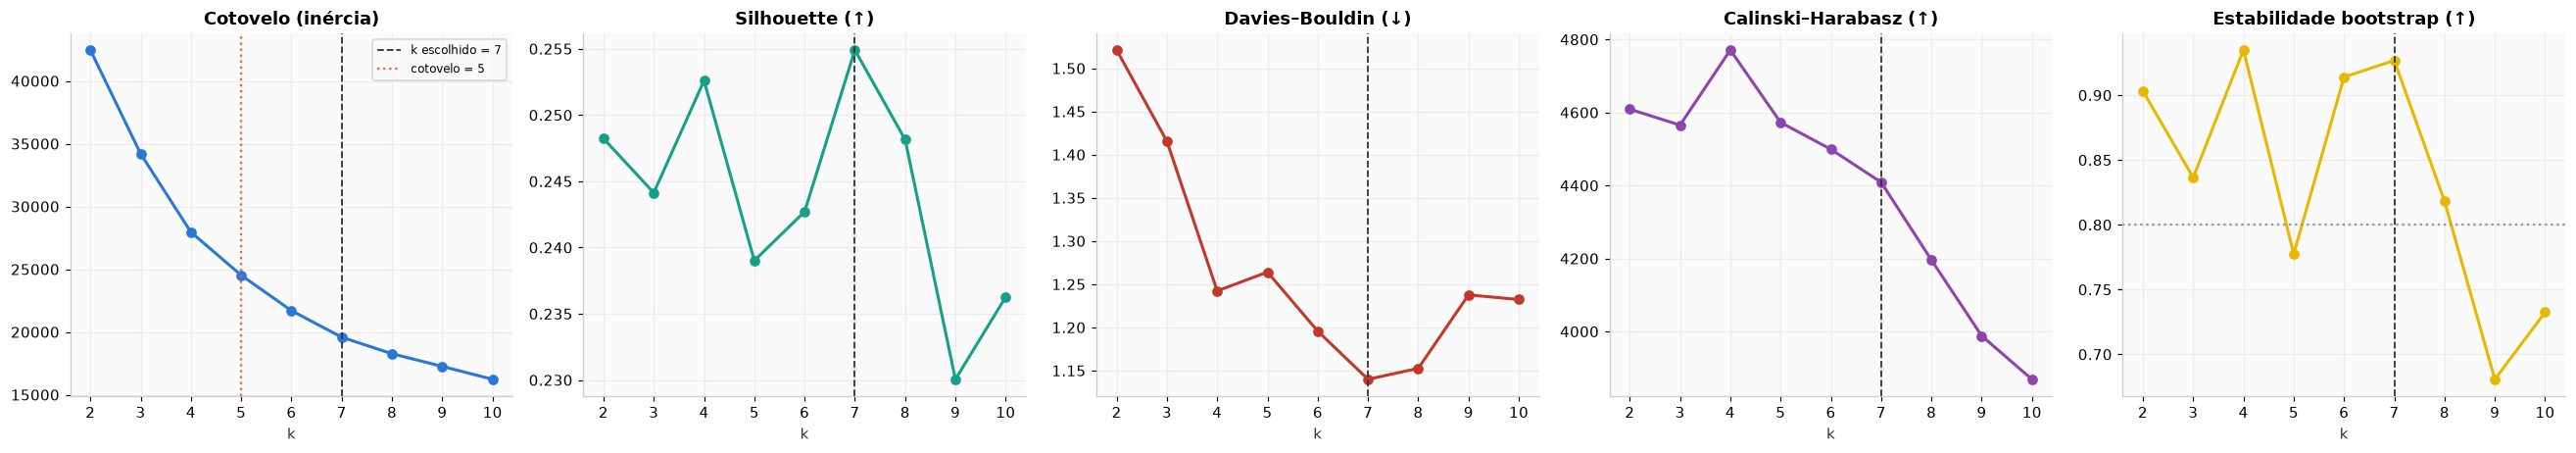

In [39]:
# 3.3 Métricas para k = 2..10
k_range = list(range(2, 11))
rng_boot = np.random.default_rng(SEED)
metricas_k = []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z_cl)
    aris = []
    for b in range(10):
        idx_b = rng_boot.choice(len(Z_cl), size=len(Z_cl), replace=True)
        km_b = KMeans(n_clusters=k, n_init=3, random_state=b).fit(Z_cl[idx_b])
        aris.append(adjusted_rand_score(km.labels_, km_b.predict(Z_cl)))
    metricas_k.append({
        "k": k,
        "Inércia": km.inertia_,
        "Silhouette": silhouette_score(Z_cl, km.labels_, sample_size=6000, random_state=SEED),
        "Davies–Bouldin": davies_bouldin_score(Z_cl, km.labels_),
        "Calinski–Harabasz": calinski_harabasz_score(Z_cl, km.labels_),
        "Estabilidade (ARI)": np.mean(aris),
    })
metricas_k = pd.DataFrame(metricas_k).set_index("k")

# Cotovelo: ponto de maior distância à reta que liga o primeiro e o último ponto da curva normalizada
x_n = (np.array(k_range) - k_range[0]) / (k_range[-1] - k_range[0])
y_in = metricas_k["Inércia"].to_numpy()
y_n = (y_in - y_in.min()) / (y_in.max() - y_in.min())
k_cotovelo = k_range[int(np.argmax(np.abs((1 - x_n) - y_n)))]

votos_k = {
    "Cotovelo": k_cotovelo,
    "Silhouette": int(metricas_k["Silhouette"].idxmax()),
    "Davies–Bouldin": int(metricas_k["Davies–Bouldin"].idxmin()),
    "Calinski–Harabasz": int(metricas_k["Calinski–Harabasz"].idxmax()),
}
estaveis = metricas_k.index[metricas_k["Estabilidade (ARI)"] >= 0.8].tolist()
contagem_votos = pd.Series(list(votos_k.values())).value_counts()
if contagem_votos.index.isin(estaveis).any():
    contagem_votos = contagem_votos[contagem_votos.index.isin(estaveis)]
K_FINAL = int(contagem_votos.index[contagem_votos == contagem_votos.max()].min())

display(metricas_k.style.format({"Inércia": "{:,.0f}", "Silhouette": "{:.3f}", "Davies–Bouldin": "{:.3f}",
                                 "Calinski–Harabasz": "{:,.0f}", "Estabilidade (ARI)": "{:.3f}"})
        .highlight_max(subset=["Silhouette", "Calinski–Harabasz", "Estabilidade (ARI)"], color="#c6e2ff")
        .highlight_min(subset=["Davies–Bouldin"], color="#c6e2ff"))
print("Votos por critério:", votos_k)
print(f"k com partição estável (ARI ≥ 0,8): {estaveis}")
print(f"==> k escolhido: {K_FINAL}")

fig, axes = plt.subplots(1, 5, figsize=(24, 4.3))
especs = [("Inércia", "Cotovelo (inércia)", "#2a78d6"), ("Silhouette", "Silhouette (↑)", "#16a085"),
          ("Davies–Bouldin", "Davies–Bouldin (↓)", "#c0392b"), ("Calinski–Harabasz", "Calinski–Harabasz (↑)", "#8e44ad"),
          ("Estabilidade (ARI)", "Estabilidade bootstrap (↑)", "#e6b800")]
for ax, (col, titulo, cor) in zip(axes, especs):
    ax.plot(k_range, metricas_k[col], marker="o", color=cor, linewidth=2)
    ax.axvline(K_FINAL, color="#333333", linestyle="--", linewidth=1.2, label=f"k escolhido = {K_FINAL}")
    ax.set_title(titulo)
    ax.set_xlabel("k")
    ax.set_xticks(k_range)
axes[0].axvline(k_cotovelo, color="#eb6834", linestyle=":", label=f"cotovelo = {k_cotovelo}")
axes[0].legend(fontsize=8)
axes[4].axhline(0.8, color="#999999", linestyle=":")
plt.tight_layout()
plt.savefig("figuras/kmeans_selecao_k.png", dpi=150, bbox_inches="tight")
plt.show()

,Nome,Receitas,% do total,Calorias,Gordura_g,Proteina_g,Carbo_g,Sodio_mg,Pct_gordura,Pct_proteina,Pct_carbo,Rating,Tags características (lift)
cluster,,,,,,,,,,,,,
0,Molhos e petiscos leves,862,6.1%,70,2.3,2.8,9.5,532,30%,16%,53%,3.48,"no-cook (2.6×), sauce (2.5×), cocktail party (2.5×), condiment/spread (1.9×), healthy (1.9×), appetizer (1.8×)"
1,Bebidas e coquetéis,1450,10.3%,233,1.9,1.9,52.1,16,7%,3%,90%,3.03,"gin (9.2×), cocktail (8.9×), alcoholic (8.6×), spirit (8.5×), drink (8.0×), fat free (7.6×)"
2,Saladas e entradas,2142,15.2%,237,18.9,5.9,10.7,384,71%,10%,19%,3.78,"no-cook (2.6×), salad (2.5×), appetizer (2.4×), condiment/spread (2.4×), leafy green (2.3×), sugar conscious (1.9×)"
3,Sobremesas ricas,2008,14.3%,398,26.6,5.8,34.0,84,60%,6%,34%,3.80,"chocolate (4.5×), almond (3.0×), mixer (2.8×), dessert (2.8×), nut (2.7×), cake (2.3×)"
4,"Massas, pães e acompanhamentos",3127,22.2%,411,15.3,11.1,57.1,477,34%,11%,55%,3.82,"cake (2.2×), pasta (2.1×), bake (1.6×), thanksgiving (1.6×), side (1.6×), dessert (1.6×)"
5,Proteína magra (peixes/aves),1501,10.7%,434,19.5,43.4,21.2,947,40%,40%,20%,3.92,"turkey (5.6×), fish (3.9×), shellfish (3.6×), shrimp (3.3×), poultry (2.9×), marinate (2.8×)"
6,Pratos principais fartos,3001,21.3%,875,58.3,44.4,43.2,977,60%,21%,19%,4.01,"beef (2.8×), chicken (2.8×), pork (2.3×), dinner (2.1×), roast (2.0×), grill/barbecue (2.0×)"


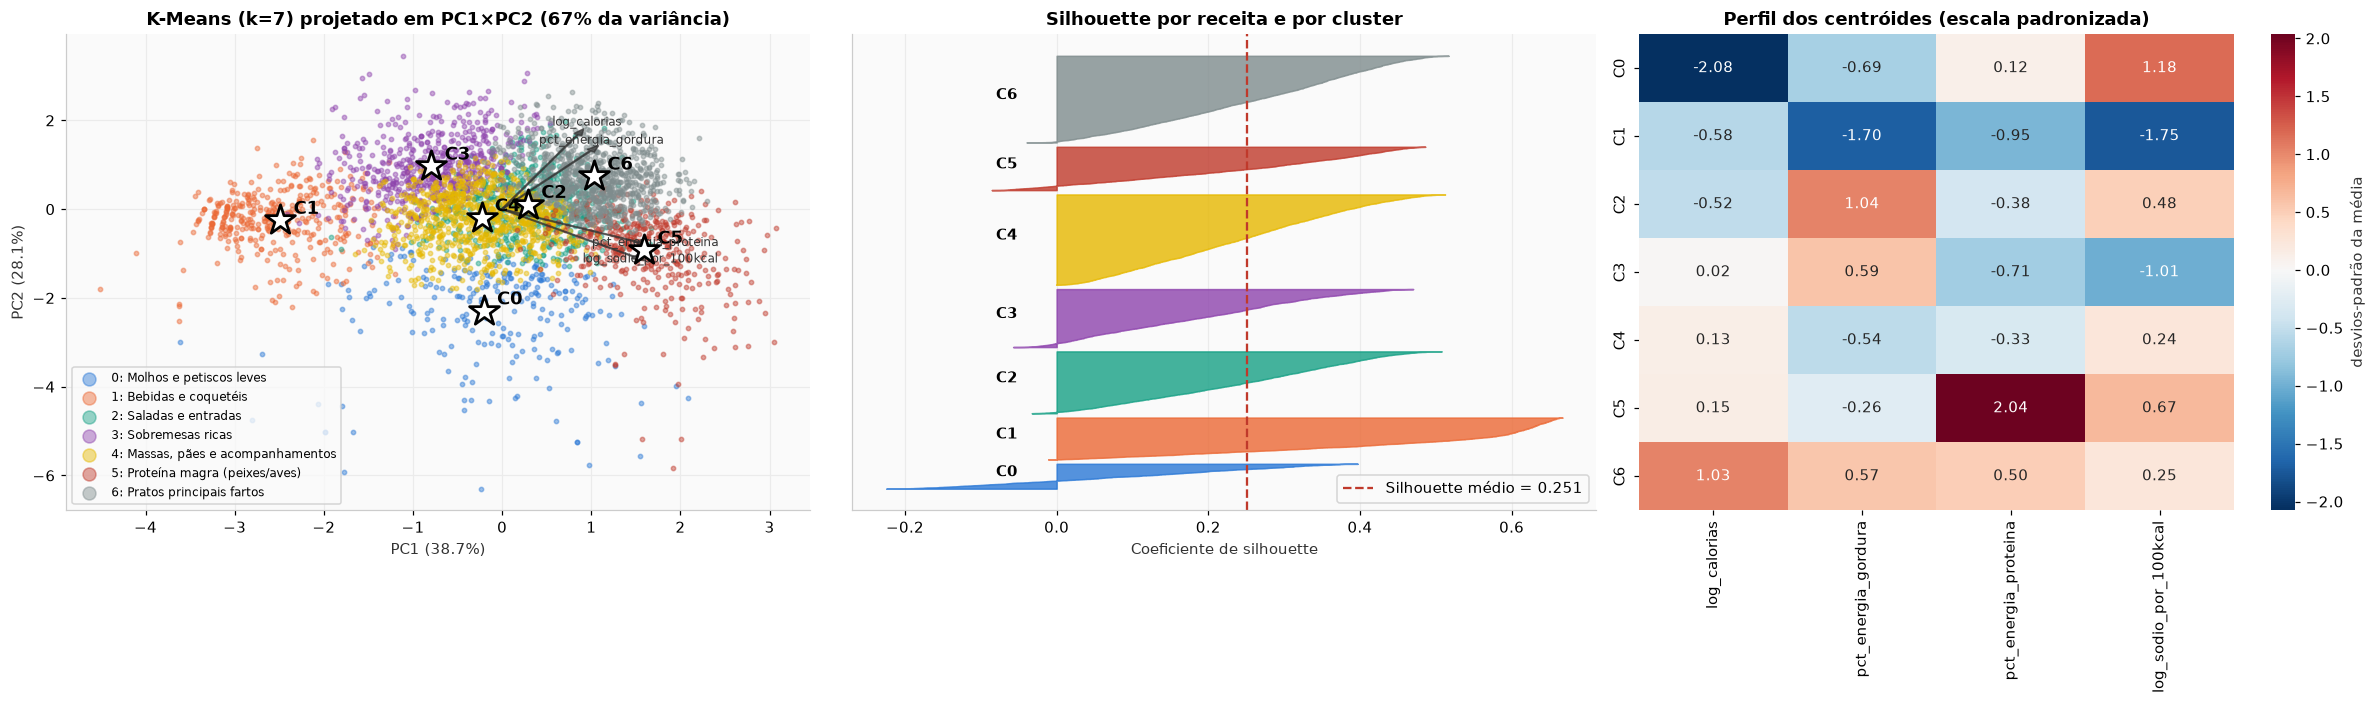

Silhouette médio (todas as receitas): 0.251 | proporção de receitas com silhouette < 0: 4.6%


In [40]:
# 3.3 Ajuste final do K-Means e perfis dos clusters
km_final = KMeans(n_clusters=K_FINAL, n_init=20, random_state=SEED).fit(Z_cl)

# Reordena os rótulos pela caloria média (rótulos determinísticos e legíveis: 0 = mais leve)
ordem_cal = pd.Series(dados_unsup["calories"].to_numpy()).groupby(km_final.labels_).mean().sort_values().index
mapa_rotulos = {antigo: novo for novo, antigo in enumerate(ordem_cal)}
dados_unsup["cluster"] = np.array([mapa_rotulos[l] for l in km_final.labels_])
centroides_z = km_final.cluster_centers_[list(ordem_cal)]

# Nomes atribuídos a partir da tabela de perfis abaixo (rótulos ordenados por caloria média)
NOMES_CLUSTERS = {
    0: "Molhos e petiscos leves",
    1: "Bebidas e coquetéis",
    2: "Saladas e entradas",
    3: "Sobremesas ricas",
    4: "Massas, pães e acompanhamentos",
    5: "Proteína magra (peixes/aves)",
    6: "Pratos principais fartos",
}
assert len(NOMES_CLUSTERS) == K_FINAL, "Revisar os nomes se o k escolhido mudar"

# Perfil em unidades originais
dados_unsup["carbo_estimado_g"] = nutr_u.loc[dados_unsup.index, "carbo_estimado_g"]
for col in ["pct_energia_gordura", "pct_energia_proteina", "pct_energia_carbo"]:
    dados_unsup[col] = candidatas_unsup[col]
perfil = dados_unsup.groupby("cluster").agg(
    Receitas=("title", "size"),
    Calorias=("calories", "mean"),
    Gordura_g=("fat", "mean"),
    Proteina_g=("protein", "mean"),
    Carbo_g=("carbo_estimado_g", "mean"),
    Sodio_mg=("sodium", "mean"),
    Pct_gordura=("pct_energia_gordura", "mean"),
    Pct_proteina=("pct_energia_proteina", "mean"),
    Pct_carbo=("pct_energia_carbo", "mean"),
    Rating=("rating", "mean"),
)
perfil.insert(1, "% do total", perfil["Receitas"] / perfil["Receitas"].sum())

# Tags características: lift = frequência no cluster / frequência geral (suporte mínimo de 8% no cluster)
freq_geral = dados_unsup[tags_mantidas].mean()
tags_carac = {}
for c in range(K_FINAL):
    freq_c = dados_unsup.loc[dados_unsup["cluster"] == c, tags_mantidas].mean()
    lift = (freq_c / freq_geral)[freq_c >= 0.08].sort_values(ascending=False).head(6)
    tags_carac[c] = ", ".join(f"{t} ({v:.1f}×)" for t, v in lift.items())
perfil["Tags características (lift)"] = pd.Series(tags_carac)
perfil.insert(0, "Nome", pd.Series(NOMES_CLUSTERS))
display(perfil.style.format({"% do total": "{:.1%}", "Calorias": "{:.0f}", "Gordura_g": "{:.1f}",
                             "Proteina_g": "{:.1f}", "Carbo_g": "{:.1f}", "Sodio_mg": "{:.0f}",
                             "Pct_gordura": "{:.0%}", "Pct_proteina": "{:.0%}", "Pct_carbo": "{:.0%}",
                             "Rating": "{:.2f}"}))

sil_amostras = silhouette_samples(Z_cl, dados_unsup["cluster"].to_numpy())
sil_km = sil_amostras.mean()

fig, axes = plt.subplots(1, 3, figsize=(22, 6.5))
# (a) clusters no plano PC1 × PC2 com centróides
for c in range(K_FINAL):
    m = (dados_unsup["cluster"].to_numpy() == c)
    m_vis = np.zeros(len(m), dtype=bool)
    m_vis[amostra_vis] = True
    axes[0].scatter(X_pca[m & m_vis, 0], X_pca[m & m_vis, 1], s=8, alpha=0.45, color=PALETA[c],
                    label=f"{c}: {NOMES_CLUSTERS[c]}")
cent_pca = pca.transform(centroides_z)
axes[0].scatter(cent_pca[:, 0], cent_pca[:, 1], marker="*", s=420, color="white", edgecolor="black", linewidth=1.8, zorder=5)
for c, (cx, cy) in enumerate(cent_pca[:, :2]):
    axes[0].text(cx + 0.15, cy + 0.15, f"C{c}", fontsize=12, fontweight="bold")
for var, (lx, ly) in zip(FEAT_CLUSTER, pca.components_[:2].T):
    axes[0].arrow(0, 0, lx * 2.5, ly * 2.5, color="#333333", width=0.015, head_width=0.1, alpha=0.7)
    axes[0].text(lx * 2.8, ly * 2.8, var, fontsize=8, color="#333333", ha="center")
axes[0].set_xlabel(f"PC1 ({var_exp[0]:.1%})")
axes[0].set_ylabel(f"PC2 ({var_exp[1]:.1%})")
axes[0].set_title(f"K-Means (k={K_FINAL}) projetado em PC1×PC2 ({var_cum[1]:.0%} da variância)")
axes[0].legend(fontsize=8, loc="best", markerscale=3)

# (b) gráfico de silhouette por cluster
y_base = 10
for c in range(K_FINAL):
    vals = np.sort(sil_amostras[dados_unsup["cluster"].to_numpy() == c])
    axes[1].fill_betweenx(np.arange(y_base, y_base + len(vals)), 0, vals, color=PALETA[c], alpha=0.8)
    axes[1].text(-0.08, y_base + len(vals) / 2, f"C{c}", fontweight="bold")
    y_base += len(vals) + 150
axes[1].axvline(sil_km, color="#c0392b", linestyle="--", label=f"Silhouette médio = {sil_km:.3f}")
axes[1].set_xlabel("Coeficiente de silhouette")
axes[1].set_yticks([])
axes[1].set_title("Silhouette por receita e por cluster")
axes[1].legend()

# (c) heatmap dos centróides padronizados
sns.heatmap(pd.DataFrame(centroides_z, columns=FEAT_CLUSTER, index=[f"C{c}" for c in range(K_FINAL)]),
            annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[2], cbar_kws={"label": "desvios-padrão da média"})
axes[2].set_title("Perfil dos centróides (escala padronizada)")
plt.tight_layout()
plt.savefig("figuras/kmeans_clusters.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Silhouette médio (todas as receitas): {sil_km:.3f} | proporção de receitas com silhouette < 0: "
      f"{(sil_amostras < 0).mean():.1%}")

**Escolha de k e interpretação dos 7 perfis:**
- **Decisão:** silhouette (0,255) e Davies–Bouldin (1,140) apontaram **k = 7**; o cotovelo apontou 5 e o Calinski–Harabasz, 4. O k = 7 é também **estável** (ARI *bootstrap* = 0,93), enquanto k = 5 é instável (0,78). Pela regra definida previamente, **k = 7**.
- **Qualidade:** silhouette médio = 0,25, o que indica **estrutura fraca a moderada** (Kaufman & Rousseeuw: 0,26–0,50 = estrutura fraca); só 4,6% das receitas têm silhouette negativa. O grupo de bebidas (C1) é o mais coeso. Conclusão honesta: os perfis são uma **segmentação útil de um contínuo**, não grupos naturalmente isolados.

| Cluster | Perfil | kcal média | Composição energética (G / P / C) | Tags características |
|---|---|---|---|---|
| C0 (6%) | **Molhos e petiscos leves** | 70 | 30% / 16% / 53% | `no-cook`, `sauce`, `condiment/spread`, `healthy` |
| C1 (10%) | **Bebidas e coquetéis** | 233 | 7% / 3% / 90% | `gin`, `cocktail`, `alcoholic`, `drink` (lift 8–9×) |
| C2 (15%) | **Saladas e entradas** | 237 | 71% / 10% / 19% | `salad`, `appetizer`, `leafy green` |
| C3 (14%) | **Sobremesas ricas** | 398 | 60% / 6% / 34% | `chocolate`, `almond`, `nut`, `dessert`, `cake` |
| C4 (22%) | **Massas, pães e acompanhamentos** | 411 | 34% / 11% / 55% | `pasta`, `cake`, `bake`, `side`, `thanksgiving` |
| C5 (11%) | **Proteína magra (peixes/aves)** | 434 | 40% / 40% / 20% | `turkey`, `fish`, `shellfish`, `shrimp`, `marinate` |
| C6 (21%) | **Pratos principais fartos** | 875 | 60% / 21% / 19% | `beef`, `chicken`, `pork`, `roast`, `grill/barbecue` |

- Os grupos foram descobertos **só com 4 variáveis nutricionais**, sem nenhuma tag. As tags características, calculadas depois, confirmam que os perfis correspondem a categorias culinárias reconhecíveis — uma validação externa da segmentação.

### 3.4 Clustering Hierárquico Aglomerativo

1. **Escolha do *linkage*:** comparamos `ward`, `complete`, `average` e `single` pela **correlação cofenética** (quanto o dendrograma preserva as distâncias originais) em uma amostra aleatória de 3.000 receitas — e também pela qualidade da partição em *k* grupos (silhouette e tamanho do maior grupo, pois `single`/`average` tendem a gerar um grupo gigante e grupos unitários).
2. **Dendrograma** com linha de corte na altura que gera *k* grupos.
3. **Comparação com o K-Means** via *Adjusted Rand Index* (ARI) e tabela cruzada.

Linkage,Correlação cofenética,Silhouette (k=7),Maior grupo (%)
ward,0.441,0.173,25.1%
complete,0.539,0.175,55.3%
average,0.714,0.258,80.3%
single,0.581,0.421,99.6%


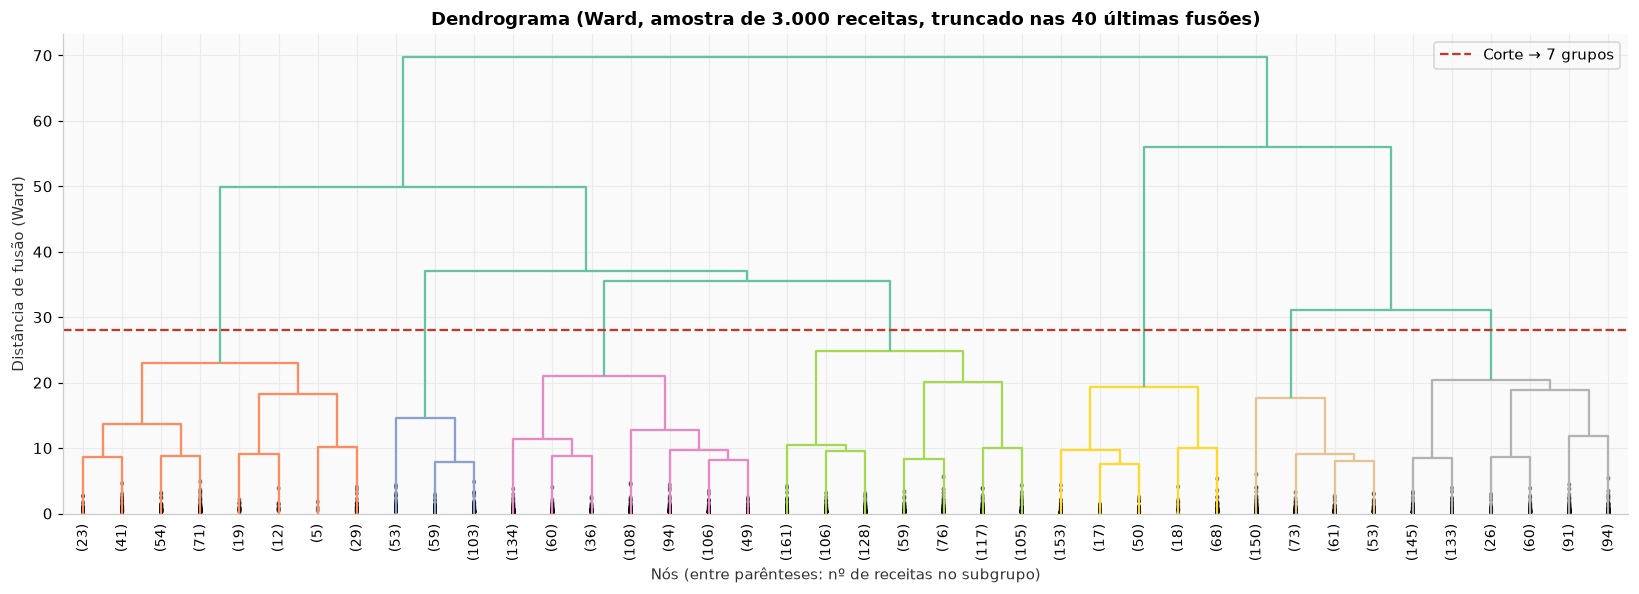

ARI entre K-Means e Hierárquico (Ward): 0.487


Hierárquico,0,1,2,3,4,5,6
K-Means,,,,,,,
0,440,0,12,48,101,0,261
1,22,0,0,1428,0,0,0
2,1833,94,25,0,1,189,0
3,258,1549,0,177,0,24,0
4,425,815,133,185,1451,118,0
5,43,0,1213,0,30,215,0
6,34,180,195,0,74,2518,0


In [41]:
# 3.4 Escolha do linkage e dendrograma
rng_h = np.random.default_rng(SEED)
amostra_h = rng_h.choice(len(Z_cl), size=3000, replace=False)
Z_h = Z_cl[amostra_h]
dist_h = pdist(Z_h)

linhas_link = []
ligacoes = {}
for metodo in ["ward", "complete", "average", "single"]:
    L = linkage(Z_h, method=metodo)
    ligacoes[metodo] = L
    rot = AgglomerativeClustering(n_clusters=K_FINAL, linkage=metodo).fit_predict(Z_h)
    linhas_link.append({
        "Linkage": metodo,
        "Correlação cofenética": cophenet(L, dist_h)[0],
        f"Silhouette (k={K_FINAL})": silhouette_score(Z_h, rot) if len(set(rot)) > 1 else np.nan,
        "Maior grupo (%)": pd.Series(rot).value_counts(normalize=True).max(),
    })
tabela_link = pd.DataFrame(linhas_link)
display(tabela_link.style.format({"Correlação cofenética": "{:.3f}", f"Silhouette (k={K_FINAL})": "{:.3f}",
                                  "Maior grupo (%)": "{:.1%}"}).hide(axis="index"))

L_ward = ligacoes["ward"]
altura_corte = (L_ward[-K_FINAL, 2] + L_ward[-K_FINAL + 1, 2]) / 2
fig, ax = plt.subplots(figsize=(15, 5.5))
dendrogram(L_ward, truncate_mode="lastp", p=40, leaf_rotation=90, leaf_font_size=9, show_contracted=True,
           color_threshold=altura_corte, ax=ax)
ax.axhline(altura_corte, color="#c0392b", linestyle="--", label=f"Corte → {K_FINAL} grupos")
ax.set_title("Dendrograma (Ward, amostra de 3.000 receitas, truncado nas 40 últimas fusões)")
ax.set_xlabel("Nós (entre parênteses: nº de receitas no subgrupo)")
ax.set_ylabel("Distância de fusão (Ward)")
ax.legend()
plt.tight_layout()
plt.savefig("figuras/dendrograma.png", dpi=150, bbox_inches="tight")
plt.show()

# Ajuste em toda a base com o linkage escolhido (Ward) e comparação com K-Means
hier = AgglomerativeClustering(n_clusters=K_FINAL, linkage="ward")
dados_unsup["cluster_hier"] = hier.fit_predict(Z_cl)
ari_hier = adjusted_rand_score(dados_unsup["cluster"], dados_unsup["cluster_hier"])
print(f"ARI entre K-Means e Hierárquico (Ward): {ari_hier:.3f}")
display(pd.crosstab(dados_unsup["cluster"], dados_unsup["cluster_hier"], rownames=["K-Means"], colnames=["Hierárquico"]))

**Discussão do agrupamento hierárquico:**
- **Escolha do *linkage*:** `average` (0,71) e `single` (0,58) têm a maior correlação cofenética, mas cortados em 7 grupos colocam **80% e 99,6%** das receitas em um único grupo (efeito de encadeamento) — partições inúteis para segmentação. **Ward** tem cofenética menor (0,44), mas produz grupos equilibrados (maior grupo = 25%) e minimiza a variância interna, o mesmo critério do K-Means. Por isso foi o escolhido.
- **Concordância com o K-Means:** ARI = 0,49 (moderada). A tabela cruzada mostra que os perfis extremos são praticamente idênticos nos dois métodos — bebidas (1.428 de 1.450), pratos fartos (2.518 de 3.001), proteína magra (1.213 de 1.501) — enquanto as divergências se concentram nos perfis centrais (C4), onde as fronteiras de um contínuo são arbitrárias.
- No dendrograma, a primeira divisão (altura ≈ 70) separa dois grandes blocos; abaixo dela, as fusões ocorrem em alturas graduais (≈ 56, 50, 37, 36, 31, 25), sem um "salto" isolado que indique um número natural de grupos. O corte em 7 grupos (altura ≈ 28) segue a decisão do K-Means — mais um sinal de estrutura contínua.

### 3.5 Modelos de Mistura Gaussiana (GMM)

O GMM generaliza o K-Means: cada grupo é uma distribuição normal com **covariância própria** (grupos elípticos, de tamanhos diferentes) e cada receita recebe uma **probabilidade** de pertencer a cada grupo. Selecionamos o número de componentes **e** o tipo de covariância (`full` × `diag`) pelo menor **BIC** (verossimilhança penalizada pelo nº de parâmetros).

Menor BIC: k = 10, covariância = 'diag' (BIC = 122,636)


ARI K-Means × GMM (k=7, full): 0.368 | ARI K-Means × GMM (BIC, k=10): 0.317
Receitas com atribuição incerta (probabilidade máxima < 0,6): 18.7%


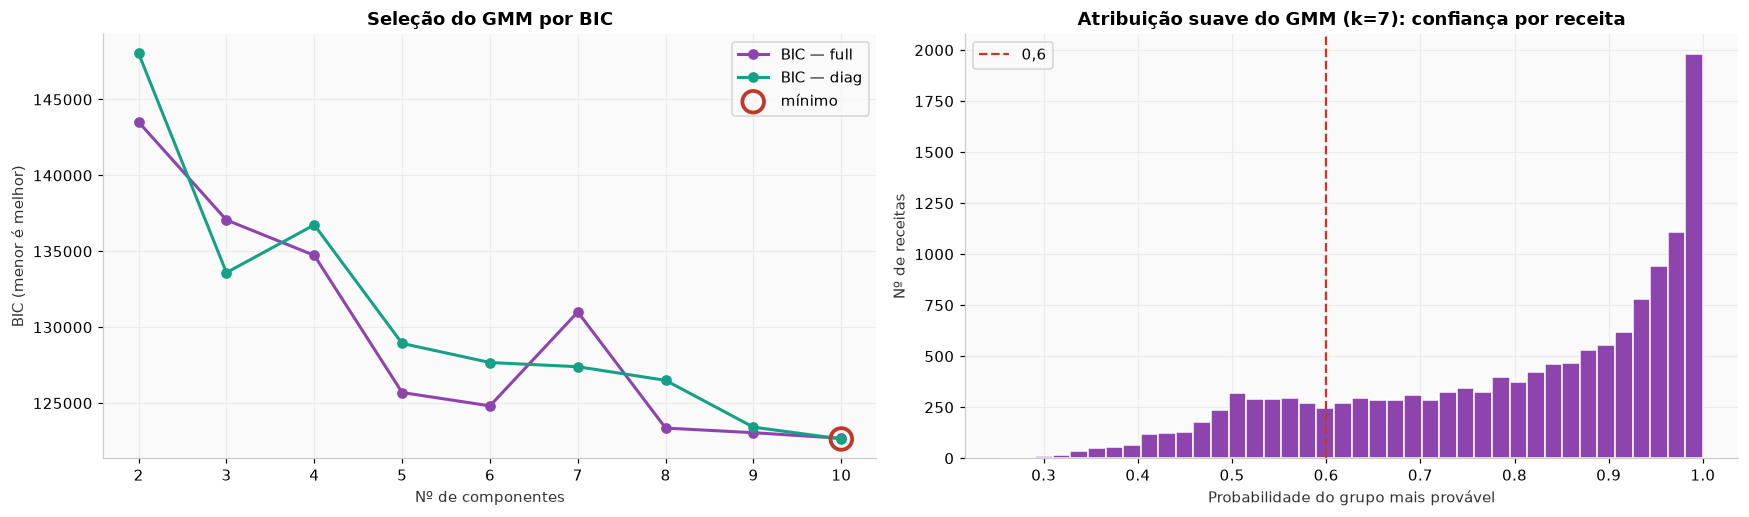

Receitas mais ambíguas (híbridas entre perfis):


,title,calories,pct_energia_gordura,pct_energia_proteina,P(G0),P(G1),P(G2),P(G3),P(G4),P(G5),P(G6)
13573,Plantation Shrimp with Shiitake Mushrooms and Baby Bok Choy,388,56%,15%,0%,21%,25%,7%,23%,24%,0%
9931,Poached Egg Crostone with Wilted Spinach and Bacon,966,67%,9%,0%,24%,24%,3%,23%,0%,26%
2487,Spiced Beef Corn Bread Cobbler,533,46%,26%,0%,26%,24%,21%,27%,2%,0%
8602,Shrimp and Cucumber Salad with Horseradish Mayo,341,82%,13%,0%,24%,2%,0%,25%,28%,21%
1734,Eggs Benedict Bread Pudding,458,49%,24%,0%,28%,27%,15%,28%,2%,0%


In [42]:
# 3.5 Seleção do GMM por BIC
linhas_gmm = []
for tipo_cov in ["full", "diag"]:
    for k in range(2, 11):
        g = GaussianMixture(n_components=k, covariance_type=tipo_cov, n_init=3, random_state=SEED).fit(Z_cl)
        linhas_gmm.append({"Covariância": tipo_cov, "k": k, "BIC": g.bic(Z_cl), "AIC": g.aic(Z_cl)})
tabela_gmm = pd.DataFrame(linhas_gmm)
melhor_gmm = tabela_gmm.loc[tabela_gmm["BIC"].idxmin()]
k_gmm_bic, cov_gmm_bic = int(melhor_gmm["k"]), melhor_gmm["Covariância"]
print(f"Menor BIC: k = {k_gmm_bic}, covariância = '{cov_gmm_bic}' (BIC = {melhor_gmm['BIC']:,.0f})")

gmm_bic = GaussianMixture(n_components=k_gmm_bic, covariance_type=cov_gmm_bic, n_init=5, random_state=SEED).fit(Z_cl)
gmm_k = GaussianMixture(n_components=K_FINAL, covariance_type="full", n_init=5, random_state=SEED).fit(Z_cl)
dados_unsup["cluster_gmm"] = gmm_k.predict(Z_cl)
probs_gmm = gmm_k.predict_proba(Z_cl)
prob_max = probs_gmm.max(axis=1)
ari_gmm = adjusted_rand_score(dados_unsup["cluster"], dados_unsup["cluster_gmm"])
ari_gmm_bic = adjusted_rand_score(dados_unsup["cluster"], gmm_bic.predict(Z_cl))
print(f"ARI K-Means × GMM (k={K_FINAL}, full): {ari_gmm:.3f} | ARI K-Means × GMM (BIC, k={k_gmm_bic}): {ari_gmm_bic:.3f}")
print(f"Receitas com atribuição incerta (probabilidade máxima < 0,6): {(prob_max < 0.6).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for tipo_cov, cor in [("full", "#8e44ad"), ("diag", "#16a085")]:
    sub = tabela_gmm[tabela_gmm["Covariância"] == tipo_cov]
    axes[0].plot(sub["k"], sub["BIC"], marker="o", color=cor, linewidth=2, label=f"BIC — {tipo_cov}")
axes[0].scatter([k_gmm_bic], [melhor_gmm["BIC"]], s=200, facecolor="none", edgecolor="#c0392b", linewidth=2.5,
                zorder=5, label="mínimo")
axes[0].set_xlabel("Nº de componentes")
axes[0].set_ylabel("BIC (menor é melhor)")
axes[0].set_title("Seleção do GMM por BIC")
axes[0].legend()
axes[1].hist(prob_max, bins=40, color="#8e44ad", edgecolor="white")
axes[1].axvline(0.6, color="#c0392b", linestyle="--", label="0,6")
axes[1].set_xlabel("Probabilidade do grupo mais provável")
axes[1].set_ylabel("Nº de receitas")
axes[1].set_title(f"Atribuição suave do GMM (k={K_FINAL}): confiança por receita")
axes[1].legend()
plt.tight_layout()
plt.savefig("figuras/gmm_bic.png", dpi=150, bbox_inches="tight")
plt.show()

exemplos = dados_unsup.iloc[np.argsort(prob_max)[:5]][["title", "calories", "pct_energia_gordura", "pct_energia_proteina"]].copy()
for c in range(K_FINAL):
    exemplos[f"P(G{c})"] = probs_gmm[np.argsort(prob_max)[:5], c]
print("Receitas mais ambíguas (híbridas entre perfis):")
display(exemplos.style.format({"calories": "{:.0f}", "pct_energia_gordura": "{:.0%}", "pct_energia_proteina": "{:.0%}",
                               **{f"P(G{c})": "{:.0%}" for c in range(K_FINAL)}}))

**Discussão do GMM:**
- O BIC continua diminuindo até o limite da grade (**k = 10, covariância diagonal**). Com 14 mil receitas e variáveis não gaussianas (proporções limitadas a [0, 1], assimetrias), o GMM usa componentes extras para **aproximar a forma** da distribuição, e não para revelar grupos — o BIC aqui não indica um *k* "verdadeiro".
- Com k = 7, o GMM concorda pouco com o K-Means (ARI = 0,37) e **18,7% das receitas** têm probabilidade máxima abaixo de 0,6, ou seja, são **híbridas** entre perfis (ex.: *Plantation Shrimp with Shiitake* divide-se entre 4 componentes com 21–25% cada).
- Valor prático: a atribuição suave permite sinalizar receitas ambíguas, para as quais o recomendador deve considerar mais de um perfil. A silhouette menor (0,14) é esperada: o GMM maximiza verossimilhança, não separação geométrica.

### 3.6 DBSCAN — Agrupamento por Densidade e Receitas Atípicas

O DBSCAN não exige *k*: agrupa regiões densas e marca pontos isolados como **ruído**. Parâmetros:
- `min_samples = 2 × nº de variáveis = 8` (regra prática da literatura).
- `eps` escolhido no **joelho do gráfico de 8-distâncias** (distância ao 8º vizinho, ordenada) — detectado automaticamente pela maior distância à corda.

eps escolhido = 0.602 | min_samples = 8
Grupos encontrados: 9 | ruído: 2.2% das receitas
Maior grupo: 97.2% das receitas | demais grupos: [18, 13, 13, 12, 9, 8, 5, 4]


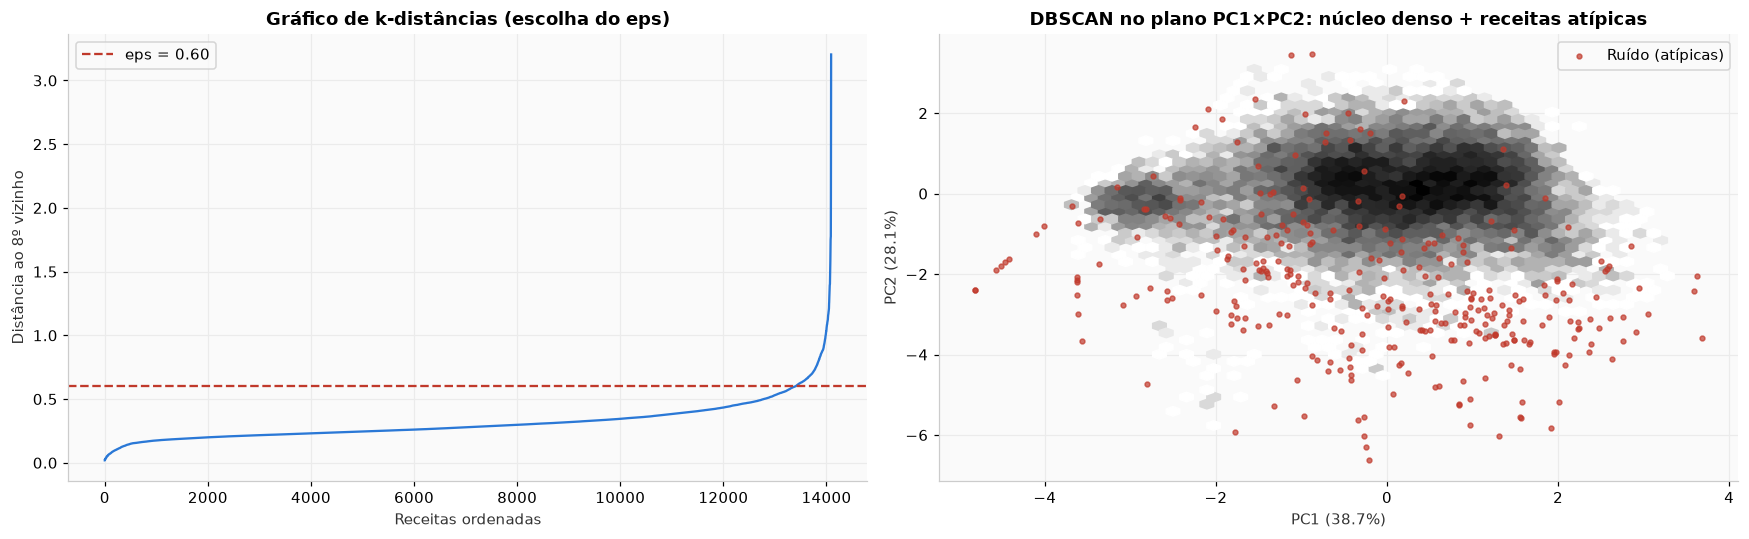

,calories,fat,protein,sodium,pct_energia_gordura,pct_energia_proteina,pct_energia_carbo
Atípicas (ruído),41.00,1.00,2.00,63.00,0.23,0.20,0.40
Núcleo denso,345.00,18.00,9.00,297.00,0.49,0.11,0.35


Exemplos de receitas atípicas: ['Dried Pear Crisps', 'Asian Dipping Sauce', 'Grilled Garlic-Marinated Skirt Steak with Lime', 'Golden Turkey Stock', 'Fish Mixed Grill', 'Light Lemon Yogurt Sauce', 'Toasted Baguette Crumbs', 'Veal Stock']


In [43]:
# 3.6 DBSCAN
min_samples = 2 * len(FEAT_CLUSTER)
dist_k = np.sort(NearestNeighbors(n_neighbors=min_samples).fit(Z_cl).kneighbors(Z_cl)[0][:, -1])
xn = np.linspace(0, 1, len(dist_k))
yn = (dist_k - dist_k.min()) / (dist_k.max() - dist_k.min())
eps_db = float(dist_k[int(np.argmax(xn - yn))])

dbscan = DBSCAN(eps=eps_db, min_samples=min_samples).fit(Z_cl)
rot_db = dbscan.labels_
dados_unsup["cluster_dbscan"] = rot_db
n_grupos_db = len(set(rot_db)) - (1 if -1 in rot_db else 0)
tamanhos_db = pd.Series(rot_db[rot_db >= 0]).value_counts()
print(f"eps escolhido = {eps_db:.3f} | min_samples = {min_samples}")
print(f"Grupos encontrados: {n_grupos_db} | ruído: {(rot_db == -1).mean():.1%} das receitas")
print(f"Maior grupo: {tamanhos_db.max() / len(rot_db):.1%} das receitas | demais grupos: {tamanhos_db.iloc[1:].tolist()}")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].plot(dist_k, color="#2a78d6")
axes[0].axhline(eps_db, color="#c0392b", linestyle="--", label=f"eps = {eps_db:.2f}")
axes[0].set_xlabel("Receitas ordenadas")
axes[0].set_ylabel(f"Distância ao {min_samples}º vizinho")
axes[0].set_title("Gráfico de k-distâncias (escolha do eps)")
axes[0].legend()
ruido = rot_db == -1
axes[1].hexbin(X_pca[~ruido, 0], X_pca[~ruido, 1], gridsize=45, cmap="Greys", mincnt=1, bins="log")
axes[1].scatter(X_pca[ruido, 0], X_pca[ruido, 1], s=10, color="#c0392b", alpha=0.7, label="Ruído (atípicas)")
axes[1].set_xlabel(f"PC1 ({var_exp[0]:.1%})")
axes[1].set_ylabel(f"PC2 ({var_exp[1]:.1%})")
axes[1].set_title("DBSCAN no plano PC1×PC2: núcleo denso + receitas atípicas")
axes[1].legend()
plt.tight_layout()
plt.savefig("figuras/dbscan.png", dpi=150, bbox_inches="tight")
plt.show()

comparacao_ruido = dados_unsup.groupby(np.where(ruido, "Atípicas (ruído)", "Núcleo denso"))[
    ["calories", "fat", "protein", "sodium", "pct_energia_gordura", "pct_energia_proteina", "pct_energia_carbo"]].median()
display(comparacao_ruido.style.format("{:.2f}"))
print("Exemplos de receitas atípicas:", dados_unsup.loc[ruido, "title"].head(8).str.strip().tolist())

**Discussão do DBSCAN:**
- Com `eps` = 0,60 (joelho da curva) e `min_samples` = 8, o DBSCAN encontra **um único núcleo denso com 97,2% das receitas**, 8 microgrupos (4 a 18 receitas) e **2,2% de ruído**.
- Isso confirma, por um critério totalmente diferente (densidade), o que silhouette, dendrograma e GMM sugeriram: **não há regiões densas separadas por vales** — os perfis nutricionais formam um contínuo. Os grupos do K-Means são uma partição útil desse contínuo.
- **Uso adequado: detecção de atípicas.** As receitas marcadas como ruído têm mediana de 41 kcal (contra 345 no núcleo) e incluem caldos, molhos e crocantes (*Veal Stock*, *Asian Dipping Sauce*, *Dried Pear Crisps*), além de possíveis erros de cadastro nutricional — candidatas a revisão de qualidade dos dados.
- As métricas do DBSCAN no quadro comparativo (Davies–Bouldin = 0,59) **não são comparáveis**: excluem o ruído e são dominadas por microgrupos.

### 3.7 Comparação dos Métodos de Agrupamento

In [44]:
# 3.7 Quadro comparativo dos métodos não supervisionados
def metricas_particao(rotulos, nome, obs=""):
    m = rotulos >= 0  # exclui ruído do DBSCAN
    n_g = len(set(rotulos[m]))
    ok = n_g > 1
    return {
        "Método": nome,
        "Nº de grupos": n_g,
        "Silhouette": silhouette_score(Z_cl[m], rotulos[m], sample_size=6000, random_state=SEED) if ok else np.nan,
        "Davies–Bouldin": davies_bouldin_score(Z_cl[m], rotulos[m]) if ok else np.nan,
        "Calinski–Harabasz": calinski_harabasz_score(Z_cl[m], rotulos[m]) if ok else np.nan,
        "ARI vs K-Means": adjusted_rand_score(dados_unsup["cluster"].to_numpy()[m], rotulos[m]),
        "Observação": obs,
    }


comp_unsup = pd.DataFrame([
    metricas_particao(dados_unsup["cluster"].to_numpy(), f"K-Means (k={K_FINAL})", "partição de referência"),
    metricas_particao(dados_unsup["cluster_hier"].to_numpy(), f"Hierárquico Ward (k={K_FINAL})", "ver dendrograma"),
    metricas_particao(dados_unsup["cluster_gmm"].to_numpy(), f"GMM full (k={K_FINAL})", "atribuição suave"),
    metricas_particao(gmm_bic.predict(Z_cl), f"GMM BIC (k={k_gmm_bic}, {cov_gmm_bic})", "melhor BIC"),
    metricas_particao(rot_db, f"DBSCAN (eps={eps_db:.2f})", f"{(rot_db == -1).mean():.1%} ruído"),
])
display(comp_unsup.style.format({"Silhouette": "{:.3f}", "Davies–Bouldin": "{:.3f}", "Calinski–Harabasz": "{:,.0f}",
                                 "ARI vs K-Means": "{:.3f}"}, na_rep="—").hide(axis="index"))

Método,Nº de grupos,Silhouette,Davies–Bouldin,Calinski–Harabasz,ARI vs K-Means,Observação
K-Means (k=7),7,0.255,1.140,"4,409",1.000,partição de referência
Hierárquico Ward (k=7),7,0.196,1.279,"3,497",0.487,ver dendrograma
GMM full (k=7),7,0.139,1.407,"2,802",0.368,atribuição suave
"GMM BIC (k=10, diag)",10,0.127,1.647,"2,519",0.317,melhor BIC
DBSCAN (eps=0.60),9,0.236,0.594,56,0.003,2.2% ruído


### 3.8 Aplicação Prática: Sistema de Substituição de Receitas

`sugerir_substitutos(trecho_titulo)` combina o agrupamento com similaridade de conteúdo:
1. Localiza a receita e seu **perfil nutricional** (cluster K-Means).
2. Filtra receitas **do mesmo perfil** com pelo menos **20% menos calorias**.
3. Ordena por **similaridade de cosseno entre as tags** (ingredientes, técnicas, tipo de prato), para que a substituta seja culinariamente parecida — e não apenas nutricionalmente.

In [45]:
# 3.8 Recomendador de substituições
matriz_tags = dados_unsup[tags_mantidas].to_numpy(dtype=float)
posicao = {idx: i for i, idx in enumerate(dados_unsup.index)}


def sugerir_substitutos(trecho_titulo, n=5, reducao_min=0.20):
    """Sugere receitas do mesmo perfil nutricional, mais leves e com tags semelhantes."""
    achados = dados_unsup[dados_unsup["title"].str.contains(trecho_titulo, case=False, na=False, regex=False)]
    if achados.empty:
        print(f"Nenhuma receita contém '{trecho_titulo}'.")
        return None
    base = achados.iloc[0]
    c = base["cluster"]
    candidatas = dados_unsup[(dados_unsup["cluster"] == c)
                             & (dados_unsup["calories"] <= base["calories"] * (1 - reducao_min))
                             & (dados_unsup.index != base.name)]
    sim = cosine_similarity(matriz_tags[[posicao[base.name]]],
                            matriz_tags[[posicao[i] for i in candidatas.index]])[0]
    sugestoes = candidatas.assign(similaridade=sim).sort_values("similaridade", ascending=False).head(n)
    print("=" * 90)
    print(f"RECEITA: {base['title'].strip()}  |  perfil: C{c} — {NOMES_CLUSTERS[c]}")
    print(f"         {base['calories']:.0f} kcal | gordura {base['fat']:.0f} g | proteína {base['protein']:.0f} g | "
          f"rating {base['rating']:.2f}")
    print("=" * 90)
    tabela = sugestoes[["title", "calories", "fat", "protein", "rating", "similaridade"]].copy()
    tabela["redução de calorias"] = 1 - tabela["calories"] / base["calories"]
    display(tabela.reset_index(drop=True).style.format({"calories": "{:.0f}", "fat": "{:.0f}", "protein": "{:.0f}",
                                                        "rating": "{:.2f}", "similaridade": "{:.2f}",
                                                        "redução de calorias": "{:.0%}"}))
    return sugestoes


_ = sugerir_substitutos("Chocolate Cake", n=5)
_ = sugerir_substitutos("Spicy Fried Chicken", n=5)
_ = sugerir_substitutos("Margarita", n=5)

RECEITA: Mexican Chocolate Cake  |  perfil: C3 — Sobremesas ricas
         730 kcal | gordura 45 g | proteína 8 g | rating 4.38


,title,calories,fat,protein,rating,similaridade,redução de calorias
0,Chocolate Chip Apricot Bars,256,15,2,3.75,0.74,65%
1,Chocolate Cupcakes with Butterscotch Icing,146,8,2,3.12,0.74,80%
2,Chocolate-Anise Straws,58,4,0,4.38,0.72,92%
3,Chocolate Pecan Banana Tarts,437,30,5,4.38,0.72,40%
4,Chocolate-Almond Torte,392,30,10,4.38,0.72,46%


RECEITA: Spicy Fried Chicken  |  perfil: C6 — Pratos principais fartos
         1855 kcal | gordura 148 g | proteína 83 g | rating 3.75


,title,calories,fat,protein,rating,similaridade,redução de calorias
0,Sauteed Chicken with Tomatoes and Cilantro,964,69,65,3.75,0.60,48%
1,Roast Chicken with Rosemary-Garlic Paste,936,66,78,4.38,0.60,50%
2,Grilled Dixie Chicken with Cayenne Spice Rub,1095,80,85,4.38,0.55,41%
3,Jamaican Jerk Chicken,903,60,70,4.38,0.52,51%
4,Mustard Seed Gravy,445,30,34,0.00,0.51,76%


RECEITA: Café Iguana Margarita  |  perfil: C1 — Bebidas e coquetéis
         148 kcal | gordura 0 g | proteína 0 g | rating 5.00


,title,calories,fat,protein,rating,similaridade,redução de calorias
0,Conference,88,0,1,0.00,0.60,41%
1,Laddie's Sub-Bourbon,107,0,0,2.50,0.59,28%
2,The Sidecar,102,0,0,4.38,0.56,31%
3,Fig Leaf,108,0,0,0.00,0.56,27%
4,Income Tax Cocktail,70,0,0,1.25,0.54,53%


**Eficácia do sistema de substituição:**
- **Sobremesa (Mexican Chocolate Cake, 730 kcal, perfil "Sobremesas ricas"):** as sugestões são todas preparações de chocolate (barras, cupcakes, torta de amêndoas), com **40% a 92% menos calorias** e similaridade de tags de 0,72–0,74.
- **Prato principal (Spicy Fried Chicken, 1.855 kcal, perfil "Pratos principais fartos"):** sugere frangos salteados, assados e grelhados com **41% a 51% menos calorias**, mantendo o tipo de prato.
- **Bebida (Café Iguana Margarita, perfil "Bebidas e coquetéis"):** sugere outros coquetéis com 27% a 53% menos calorias — nunca uma comida.
- **Limitações observadas:** (i) a similaridade por tags pode sugerir um componente em vez de um prato (*Mustard Seed Gravy* para o frango frito); (ii) o filtro não considera a nota — várias sugestões não têm avaliação (rating 0). Melhorias: exigir a mesma categoria de prato (`main`, `dessert`, `drink`) e usar o tipo de prato previsto no Bloco 2 para restringir as sugestões à mesma categoria.

---
## Síntese — Quadro Comparativo das Técnicas

Quadro único com todas as técnicas aplicadas no trabalho: configuração, métrica principal no conjunto de teste (ou métrica interna, no caso não supervisionado), pontos fortes e limitações observadas.

In [46]:
# Quadro síntese de todas as técnicas
def linha(bloco, tecnica, config, metrica, forte, limite):
    return {"Bloco": bloco, "Técnica": tecnica, "Configuração": config, "Métrica principal": metrica,
            "Ponto forte": forte, "Limitação": limite}


r_reg = {r["Modelo"]: r for r in resultados_regressao}
def m_reg(chave):
    r = next(v for k, v in r_reg.items() if k.startswith(chave))
    return f"R²aj={r['R² Ajustado Teste']:.3f} | MAE={r['MAE Teste']:.0f} kcal"


r_cls = {r["Modelo"]: r for r in resultados_tipo}
def m_cls(chave):
    r = next(v for k, v in r_cls.items() if k.startswith(chave))
    return f"F1-macro={r['F1-macro']:.3f} | Acurácia={r['Acurácia']:.3f}"


def hp(chave):
    return next(v for k, v in r_cls.items() if k.startswith(chave))["Melhores hiperparâmetros"]


lin_u = {l["Método"].split(" (")[0]: l for l in comp_unsup.to_dict("records")}
sintese = pd.DataFrame([
    linha("Regressão", "Regressão Linear", "3 macros, OLS", m_reg("1."), "Interpretável; base física", "Ignora carboidratos"),
    linha("Regressão", "Polinomial (grau 2)", "3 macros", m_reg("2."), "Captura curvatura", "Sem ganho; risco de extrapolação"),
    linha("Regressão", "Splines cúbicas naturais", "cr(df=4) em fat/protein", m_reg("3."), "Flexível e suave", "Sem ganho sobre o linear"),
    linha("Regressão", "GAM", "s(fat)+s(protein)+s(sodium)", m_reg("4."), "Não linear e interpretável", "Só 3 variáveis"),
    linha("Regressão", "Ridge (L2)", "30 variáveis, α=1", m_reg("5."), "Estável com colinearidade", "Não seleciona variáveis"),
    linha("Regressão", "Lasso (L1)", "335 variáveis, α por CV", m_reg("6."), "Seleção embutida (246 não nulas)", "Penalizado no R² ajustado"),
    linha("Regressão", "Árvore de decisão", "max_depth=8", m_reg("7."), "Regras legíveis", "Alta variância"),
    linha("Regressão", "Bagging", "50 árvores", m_reg("8."), "Reduz variância da árvore", "Menos interpretável"),
    linha("Regressão", "Random Forest", "100 árvores", m_reg("9."), "Robusto, pouco ajuste", "Custo computacional"),
    linha("Regressão", "Gradient Boosting", "HistGB, 30 variáveis", m_reg("10."), "Melhor desempenho", "Caixa-preta; requer ajuste"),
    linha("Classificação", "Regressão Logística", hp("1."), m_cls("1."), "Coeficientes interpretáveis", "Fronteira linear"),
    linha("Classificação", "LDA", hp("2."), m_cls("2."), "Rápido; covariância regularizada", "Supõe normalidade"),
    linha("Classificação", "QDA", hp("3."), m_cls("3."), "Fronteiras quadráticas", "Exige forte regularização"),
    linha("Classificação", "Naive Bayes (Bernoulli)", hp("4."), m_cls("4."), "Muito rápido; natural para tags binárias", "Independência condicional"),
    linha("Classificação", "KNN", hp("5."), m_cls("5."), "Não paramétrico", "Sensível à dimensão; lento na predição"),
    linha("Classificação", "SVM (RBF)", hp("6."), m_cls("6."), "Fronteiras não lineares", "Treino O(n²); probabilidade via calibração interna"),
    linha("Classificação", "Random Forest", hp("7."), m_cls("7."), "Interações automáticas", "Menos interpretável"),
    linha("Classificação", "Gradient Boosting", hp("8."), m_cls("8."), "Interações automáticas; trata ausentes", "Muitos hiperparâmetros"),
    linha("Não supervisionado", "PCA", f"{len(FEAT_CLUSTER)} variáveis padronizadas",
          f"PC1+PC2 = {var_cum[1]:.1%} da variância; Kaiser = {n_kaiser} PCs", "Visualização e interpretação dos eixos", "Linear"),
    linha("Não supervisionado", "K-Means", f"k={K_FINAL} (5 critérios + estabilidade)",
          f"Silhouette={lin_u['K-Means']['Silhouette']:.3f} | DB={lin_u['K-Means']['Davies–Bouldin']:.2f}",
          "Simples, estável, perfis claros", "Supõe grupos esféricos"),
    linha("Não supervisionado", "Hierárquico (Ward)", f"k={K_FINAL}, linkage por cofenética",
          f"Silhouette={lin_u['Hierárquico Ward']['Silhouette']:.3f} | ARI vs KM={ari_hier:.2f}",
          "Mostra a hierarquia dos perfis", "Memória O(n²)"),
    linha("Não supervisionado", "GMM", f"k por BIC={k_gmm_bic} ({cov_gmm_bic}); k={K_FINAL} para comparação",
          f"ARI vs KM={ari_gmm:.2f}; {(prob_max < 0.6).mean():.0%} incertas", "Atribuição suave; grupos elípticos",
          "BIC favorece muitos componentes"),
    linha("Não supervisionado", "DBSCAN", f"eps={eps_db:.2f}, min_samples={min_samples}",
          f"{n_grupos_db} grupos; {(rot_db == -1).mean():.1%} ruído", "Detecta atípicas; sem k",
          "Não separa perfis em dados contínuos"),
])
pd.set_option("display.max_colwidth", 80)
display(sintese.style.hide(axis="index"))
print(f"Total de técnicas aplicadas: {len(sintese)}")

Bloco,Técnica,Configuração,Métrica principal,Ponto forte,Limitação
Regressão,Regressão Linear,"3 macros, OLS",R²aj=0.845 | MAE=95 kcal,Interpretável; base física,Ignora carboidratos
Regressão,Polinomial (grau 2),3 macros,R²aj=0.845 | MAE=96 kcal,Captura curvatura,Sem ganho; risco de extrapolação
Regressão,Splines cúbicas naturais,cr(df=4) em fat/protein,R²aj=0.844 | MAE=96 kcal,Flexível e suave,Sem ganho sobre o linear
Regressão,GAM,s(fat)+s(protein)+s(sodium),R²aj=0.852 | MAE=90 kcal,Não linear e interpretável,Só 3 variáveis
Regressão,Ridge (L2),"30 variáveis, α=1",R²aj=0.887 | MAE=71 kcal,Estável com colinearidade,Não seleciona variáveis
Regressão,Lasso (L1),"335 variáveis, α por CV",R²aj=0.880 | MAE=67 kcal,Seleção embutida (246 não nulas),Penalizado no R² ajustado
Regressão,Árvore de decisão,max_depth=8,R²aj=0.819 | MAE=87 kcal,Regras legíveis,Alta variância
Regressão,Bagging,50 árvores,R²aj=0.873 | MAE=77 kcal,Reduz variância da árvore,Menos interpretável
Regressão,Random Forest,100 árvores,R²aj=0.882 | MAE=70 kcal,"Robusto, pouco ajuste",Custo computacional
Regressão,Gradient Boosting,"HistGB, 30 variáveis",R²aj=0.897 | MAE=66 kcal,Melhor desempenho,Caixa-preta; requer ajuste


Total de técnicas aplicadas: 23


## Conclusões, Ética e Próximos Passos

### Resposta às perguntas de negócio
1. **Regressão — é possível estimar as calorias de uma receita?** **Sim, com alta precisão.** O Gradient Boosting atinge $R^2_{aj}$ = 0,897 e erro médio de 66 kcal. Gordura e proteína explicam a maior parte (base física dos fatores de Atwater), e as tags compensam a ausência de carboidratos (+5 p.p. de $R^2$).
2. **Classificação — é possível categorizar automaticamente o tipo de prato?** **Sim.** O Gradient Boosting atinge F1-macro = 0,766 e acurácia = 0,833 em 6 classes (ROC-AUC = 0,956). Bebidas e sobremesas são quase perfeitas; o principal erro é entre entrada, acompanhamento e prato principal, categorias editorialmente ambíguas. Com rejeição por confiança, **64% das receitas podem ser categorizadas sem revisão com 95% de acerto**.
3. **E o rating?** Testado em 6 formulações, **não é previsível como medida de qualidade** ($R^2$ = 0,04); o sinal existente reflete exposição (ano, fonte editorial), porque o dataset não traz o número de avaliações. É um resultado negativo documentado.
4. **Não supervisionado — existem perfis nutricionais?** **Sim, como segmentação de um contínuo.** Sete perfis interpretáveis (de bebidas a pratos fartos) foram obtidos só com 4 variáveis de composição e validados externamente pelas tags. Silhouette (≈ 0,25), dendrograma, GMM e DBSCAN concordam que não há grupos isolados. O recomendador `sugerir_substitutos()` usa os perfis para sugerir versões até ~90% mais leves do mesmo tipo de prato.

### Cuidados éticos e sociais
- **Viés cultural:** o público e as categorias do Epicurious são majoritariamente norte-americanos — "café da manhã" ou "entrada" são convenções culturais; o modelo reproduz a curadoria editorial que aprendeu.
- **Exposição:** usar o rating para ranquear receitas criaria um ciclo de retroalimentação (quem é destacado recebe mais avaliações).
- **Saúde:** os valores nutricionais são estimativas por porção, com erros de cadastro (vide atípicas do DBSCAN). O recomendador **não substitui orientação de nutricionista**, especialmente para pessoas com restrições clínicas.
- **Transparência:** modelos lineares interpretáveis (Logística, LDA) ficaram a poucos pontos do melhor; quando a explicação for importante, são alternativas legítimas. A classificação com rejeição mantém um humano no circuito para os casos incertos.

### Regulação (LGPD) e limitações
- **Dados:** o dataset é público e contém apenas receitas e notas **agregadas**, sem dados pessoais. Em uma aplicação real com histórico individual de usuários (preferências, restrições alimentares), estes seriam dados pessoais — e dados de saúde são **dados sensíveis** (art. 11 da Lei 13.709/2018), exigindo base legal específica, consentimento, minimização e segurança.
- **Limitações metodológicas:** carboidratos estimados por diferença; ausência do número de avaliações; categorias editoriais com 888 receitas ambíguas; seleção de variáveis feita no treino completo (o CV é levemente otimista; o teste é a referência); perfis do agrupamento dependentes do espaço de atributos.
- **Generalização:** as receitas sem categoria têm menos tags que as rotuladas (mudança de distribuição); o desempenho nelas tende a ser menor que o medido no teste. Os resultados valem para receitas do Epicurious de 2004 a 2016.

### Próximos passos
1. Incorporar o **texto** da receita (ingredientes e modo de preparo) — o teste exploratório com TF-IDF indicou +5 p.p. de F1-macro na categorização.
2. Obter o **número de avaliações** e modelar a nota com média bayesiana, separando qualidade de exposição.
3. Validar a categorização automática com **teste A/B** no catálogo e auditar periodicamente as receitas aceitas sem revisão.
4. Usar o tipo de prato previsto para restringir as sugestões do recomendador à mesma categoria e avaliar a satisfação dos usuários com as substituições.

---
**Fim do Notebook.**